# Active tuned mass damper pada mobil penumpang

**Laporan proyek R&D otomotif · Revisi 3 · 26 November 2026**  
*Quarter-car model · Time response · Bode analysis · Monte Carlo sensitivity analysis*

Ketika mobil melewati jalan bergelombang, ban menerima perubahan *road elevation* terlebih dahulu. Suspensi meneruskan sebagian gerak itu ke bodi. Studi ini menguji apakah *active tuned mass damper* (ATMD) yang dipasang pada bodi dapat mengurangi *peak body displacement*, berapa *actuator force* yang diperlukan, dan pada kondisi apa ruang gerak yang tersedia membatasi manfaatnya.

Konsep mekanis berasal dari *mass damper* Renault Formula 1 yang tercatat dalam putusan FIA [1]. Penerapan ATMD pada *vehicle vibration control* juga telah diteliti oleh Taskin dkk. [2]. Proyek ini memakai *passenger-car model*, kandidat *linear actuator* komersial, dan perbandingan PID–LQR dengan target *peak reduction* yang sama.

| Pertanyaan proyek | Bukti yang diperiksa |
|---|---|
| Apa yang berubah ketika motor diaktifkan? | *Peak displacement*, *RMS force*, dan *road-to-body transmissibility* pada kendaraan standar, TMD pasif, ATMD-PID, dan ATMD-LQR. |
| Kapan *small-signal model* masih mewakili perilaku sistem? | Perbandingan *Laplace model*, *sampled controller*, dan *time-domain simulation*, disertai *force saturation* dan *end-stop contact*. |
| Variabel mana yang perlu diketahui lebih akurat? | *Total-order sensitivity index* untuk *road excitation*, *vehicle parameters*, dan *ATMD parameters* dengan *controller gains* tetap. |
| Apakah optimasi adaptif menghemat gaya pada target reduksi 5%, dan bagaimana hasilnya pada jalan lain? | §12 membandingkan grid, Differential Evolution dan constrained Bayesian Optimization dengan anggaran setara. |

**Cara menjalankan.** Buka di Google Colab, pilih *Python CPU runtime*, kemudian **Runtime → Run all**. Semua data untuk konfigurasi bawaan sudah disertakan. §7–8 menyediakan *sliders* dan animasi. Untuk langsung membaca perluasan studi, buka **§9 Bode analysis**, **§10 Monte Carlo**, lalu **§11 Kesimpulan**. Semua angka pada kesimpulan dihitung kembali setiap kali notebook dijalankan.

In [1]:
from dataclasses import dataclass, replace
from functools import lru_cache
from itertools import product
from pathlib import Path
from io import BytesIO
import sys, shutil, tempfile
import numpy as np
import pandas as pd
import scipy
from scipy import linalg, signal
from scipy.optimize import minimize_scalar, brentq
from scipy.integrate import solve_ivp, trapezoid
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
from IPython.display import display, HTML, Image, Markdown

colors = {"Standard": "#516171", "TMD": "#b95f17", "PID": "#007b76", "LQR": "#6246a0"}
styles = {"Standard": ":", "TMD": "--", "PID": "-", "LQR": "-."}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18,
                     "figure.constrained_layout.use": True, "axes.titlelocation": "left"})
pd.set_option("display.max_columns", 20)
def show_table(frame, decimals=3):
    labels = {"kondisi":"Constraint case","k_factor":"Stiffness factor","c_factor":"Damping factor",
              "nominal_linear_stability":"Nominal linear stability","gain_pct":"Peak reduction (%)",
              "force_rms":"RMS force (N)","force_peak":"Peak force (N)","feasible":"Screen pass",
              "contacts":"Contact events","id":"Gain set","family":"Controller","case":"Scenario"}
    table = frame.rename(columns=labels).to_html(index=False, border=0, na_rep="—", float_format=lambda value: f"{value:.{decimals}f}")
    display(HTML('<div style="width:100%;overflow-x:auto">' + table + '</div>'))
print(f"Python {sys.version.split()[0]} · NumPy {np.__version__} · SciPy {scipy.__version__} · pandas {pd.__version__}")

Python 3.12.14 · NumPy 2.3.5 · SciPy 1.17.0 · pandas 2.2.3


## 1 · Susunan kendaraan dan jalur gaya

*Road elevation* $y(t)$ menggerakkan ban. *Suspension spring* dan *damper* meneruskan gaya dari *unsprung mass* ke *sprung mass*. Di bagian atas, *absorber spring*, *damper*, *end stops*, dan *linear actuator* menghubungkan *absorber mass* dengan bodi. Gaya motor bekerja pada kedua ujungnya dengan tanda berlawanan [2].

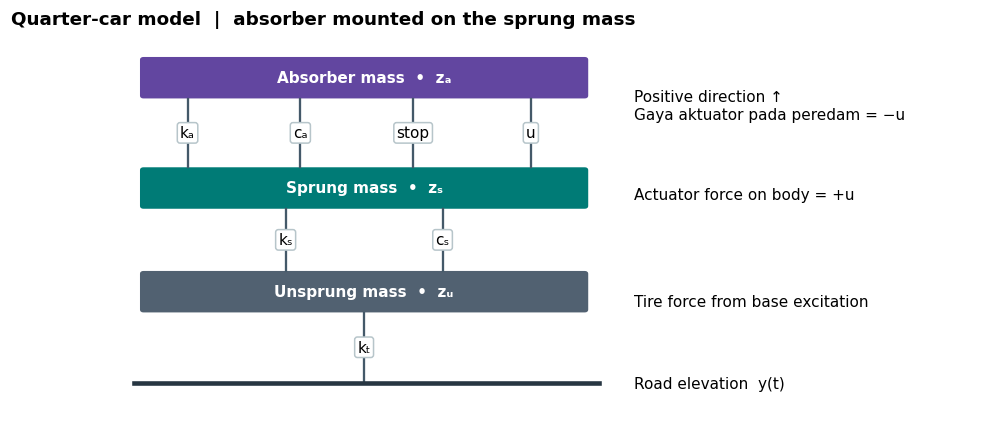

In [2]:
def draw_layout():
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.set(xlim=(0, 10), ylim=(-.3, 4.35)); ax.axis("off")
    for y, label, col in [(3.60, "Absorber mass  •  zₐ", "#6246a0"),
                          (2.27, "Sprung mass  •  zₛ", "#007b76"), (1.02, "Unsprung mass  •  zᵤ", "#516171")]:
        ax.add_patch(FancyBboxPatch((1.35,y),4.5,.43,boxstyle="round,pad=.035",
                                    linewidth=0, facecolor=col))
        ax.text(3.6,y+.215,label,color="white",weight="bold",va="center",ha="center")
    def branch(x, low, high, label):
        ax.plot([x,x],[low,high],color="#445969",lw=1.5)
        ax.text(x,(low+high)/2,label,ha="center",va="center",fontsize=10,
                bbox=dict(boxstyle="round,pad=.18",facecolor="white",edgecolor="#b7c5ca"))
    for x, txt in zip([1.8,2.95,4.1,5.3], ["kₐ","cₐ","stop","u"]):
        branch(x,2.74,3.56,txt)
    branch(2.8,1.49,2.23,"kₛ"); branch(4.4,1.49,2.23,"cₛ")
    branch(3.6,.15,.98,"kₜ")
    ax.plot([1.25,6.0],[.13,.13],lw=3,color="#273642")
    ax.text(6.35,.13,"Road elevation  y(t)",va="center")
    ax.text(6.35,3.48,"Positive direction ↑\nGaya aktuator pada peredam = −u",va="center")
    ax.text(6.35,2.40,"Actuator force on body = +u",va="center")
    ax.text(6.35,1.12,"Tire force from base excitation",va="center")
    ax.set_title("Quarter-car model  |  absorber mounted on the sprung mass",weight="bold")
    plt.show()
draw_layout()

### Koordinat dan persamaan Newton

$z_s,z_u,z_a$ menyatakan *vertical displacement* bodi, roda, dan *absorber* terhadap *static equilibrium* masing-masing. Arah positif ke atas. Semua posisi dan kecepatan awal bernilai nol. *Relative stroke* adalah $r=z_a-z_s$. Pada kecepatan maju tetap $v$, posisi sepanjang jalan adalah $v(t-t_0)$. Model dibatasi pada gerak vertikal satu sudut kendaraan. Pengaruh *drag*, *downforce*, *pitch*, dan *roll* memerlukan model tambahan.

Dengan $F_s=k_s(z_s-z_u)+c_s(\dot z_s-\dot z_u)$ dan $F_t=k_t(z_u-y)+c_t(\dot z_u-\dot y)$, hukum Newton menghasilkan

$$
\begin{aligned}
m_s\ddot z_s &=-F_s+k_a r+c_a\dot r+F_b+u,\\
m_u\ddot z_u &= F_s-F_t,\\
m_a\ddot z_a &=-k_a r-c_a\dot r-F_b-u .
\end{aligned}
$$

$F_b$ adalah *end-stop force* pada bodi. Ketika ketiga persamaan dijumlahkan, semua gaya internal saling menghapus dan hanya $-F_t$ yang tersisa. Kendaraan standar memiliki dua *degrees of freedom*. TMD pasif menambahkan *absorber* dengan $u=0$. Kedua ATMD memakai *hardware* mekanis yang sama dengan TMD. Untuk *state feedback*, urutan *state vector* adalah $x=[z_s,z_u,z_a,\dot z_s,\dot z_u,\dot z_a]^T$. *Body displacement* menjadi sasaran proyek. Penilaian *ride comfort* manusia memerlukan metrik tambahan.

### Sumber parameter dan asumsi desain

| Parameter | Nilai nominal | Dasar pemilihan |
|---|---:|---|
| *Sprung mass* $m_s$ | 300 kg per sudut | Asumsi mobil penumpang, termasuk ekuivalen massa dudukan tetap. |
| *Unsprung mass* $m_u$, *suspension stiffness* $k_s$, *tire stiffness* $k_t$, *suspension damping* $c_s$ | 45 kg, 18.990 N/m, 195.900 N/m, 1.800 N·s/m | Rasio *Golden Car* dikalikan 300 kg [3, hlm. 15–17]. *Tire damping* $c_t=0$ untuk desain. |
| *Absorber mass* $m_a$ | 12 kg | Asumsi 4% dari $m_s$, termasuk komponen motor yang ikut bergerak. Kendaraan standar lebih ringan 12 kg. TMD dan kedua ATMD memiliki massa total yang sama. |
| *Absorber stiffness* $k_a$ dan *damping* $c_a$ | Hasil §4 | *Minimax tuning* di sekitar *body-bounce mode*. *Spring preload* atau penyeimbang gravitasi diasumsikan menempatkan posisi diam di tengah *stroke*. |
| *Linear actuator* | LinMot DM01-37x120F-HP-R-95, 0150-4013 | *Rated stroke* total 95 mm [4]. Posisi tengah memberi ruang 47,5 mm ke setiap arah. |
| *Peak force* / *continuous force* | 255 N pada 48 V / 62 N dengan *passive cooling* | *Peak force* membatasi *command*. Nilai 62 N menjadi acuan *RMS duty screening*. Katalog juga mencantumkan 87 N dengan kipas dan *thermal time constant* 600 s untuk *passive cooling* [4]. |
| *Speed limit* sebagai acuan | 2,5 m/s pada 48 V | *Assembly drawing* mencantumkan nilai ini untuk *part number* yang sama pada sumbu horizontal [5]. Pada 72 V nilainya 3,8 m/s. *Peak force* dan *maximum speed* merupakan dua titik operasi yang berbeda. |
| *End-stop clearance*, *stiffness*, *damping* | ±40 mm, 200 kN/m, 850 N·s/m | Asumsi *compliant bumper*, dengan transisi 1 mm. Masih tersedia 7,5 mm antara *first contact* dan ujung *stroke*. |
| *Motoring efficiency* | 95% | Asumsi proyek. Energi mekanis terserap dicatat terpisah dengan *regeneration credit* nol. |
| *Integration step* / *controller sample time* | 0,5 ms / 2 ms | §6 menguji ulang dengan *integration step* separuh. |

Model mengasumsikan *force loop* ideal dengan *command clipping*. *Force–speed envelope*, *winding temperature*, gesekan, dan kekuatan dudukan memerlukan data tambahan. *End-stop force* merupakan beban mekanis internal dan dapat melampaui *motor force*.

In [3]:
@dataclass(frozen=True)
class Vehicle:
    body_mass: float = 300.0
    wheel_mass: float = 45.0
    suspension_stiffness: float = 18990.0
    suspension_damping: float = 1800.0
    tire_stiffness: float = 195900.0
    tire_damping: float = 0.0
    absorber_mass: float = 12.0

@dataclass(frozen=True)
class Hardware:
    peak_force: float = 255.0
    continuous_force: float = 62.0
    speed_reference: float = 2.5
    half_travel: float = .0475
    stop_onset: float = .040
    stop_stiffness: float = 200_000.
    stop_damping: float = 850.
    transition_length: float = .001
    efficiency: float = .95

@dataclass(frozen=True)
class Absorber:
    stiffness: float
    damping: float

vehicle = Vehicle()
hardware = Hardware()
control_period = .002                  # s, pengendali diperbarui pada 500 Hz
integration_step = .0005               # s, kontak diperbarui empat kali per periode
assert 0 < hardware.stop_onset < hardware.half_travel

In [4]:
def mechanical_matrices(car, absorber=None):
    # Saat absorber=None, sistem benar-benar hanya memiliki dua derajat kebebasan.
    masses = [car.body_mass, car.wheel_mass]
    if absorber is not None:
        masses.append(car.absorber_mass)
    count = len(masses)
    unit = np.eye(count)
    suspension_direction = unit[0] - unit[1]
    stiffness = car.suspension_stiffness * np.outer(suspension_direction, suspension_direction)
    damping = car.suspension_damping * np.outer(suspension_direction, suspension_direction)
    stiffness += car.tire_stiffness * np.outer(unit[1], unit[1])
    damping += car.tire_damping * np.outer(unit[1], unit[1])
    actuator_direction = np.zeros(count)
    if absorber is not None:
        actuator_direction = unit[0] - unit[2]
        stiffness += absorber.stiffness * np.outer(actuator_direction, actuator_direction)
        damping += absorber.damping * np.outer(actuator_direction, actuator_direction)
    return np.diag(masses), stiffness, damping, unit[1], actuator_direction

def state_matrices(car, absorber=None):
    mass, stiffness, damping, wheel_direction, actuator_direction = mechanical_matrices(car, absorber)
    count = len(mass)
    dynamics = np.block([[np.zeros_like(mass), np.eye(count)],
                         [-np.linalg.solve(mass, stiffness), -np.linalg.solve(mass, damping)]])
    # Kolom input: elevasi jalan, kecepatan vertikal jalan, gaya pada bodi.
    forces = np.column_stack((wheel_direction * car.tire_stiffness,
                              wheel_direction * car.tire_damping, actuator_direction))
    inputs = np.vstack((np.zeros((count,3)), np.linalg.solve(mass,forces)))
    return dynamics, inputs

def modes_hz(car):
    mass, stiffness, *_ = mechanical_matrices(car)
    return np.sqrt(linalg.eigvalsh(stiffness, mass)) / (2*np.pi)
print("Undamped natural frequencies, standard vehicle (Hz):", np.round(modes_hz(vehicle),3))

Undamped natural frequencies, standard vehicle (Hz): [ 1.208 11.005]


## 2 · Verifikasi terhadap publikasi

**Time domain.** Gambar 1 dan kurva pasif pada panel pertama Gambar 13 direkonstruksi dari persamaan (5)–(6) dan Tabel 1 Samaroo dkk. [6]. Nilai acuannya $m_s=250$ kg, $m_u=45$ kg, $k_s=6500$ N/m, $k_t=15000$ N/m, $c_s=285$ N·s/m, dan $c_t=1600$ N·s/m. *Half-sine bump* setinggi 50 mm dimulai pada 2,5 s dan berlangsung 0,1 s. Lebar 0,5 m setara dengan kecepatan 18 km/jam.

Untuk perbandingan tambahan, *active suspension* pada publikasi memakai motor antara bodi dan roda. Kurva di bawah menggunakan *feedback* $e=-z_s$ dan *gains* dari Tabel 3. Sel memeriksa batas ±500 N dan menghitung selisih terhadap penurunan RMS 56% yang dilaporkan. *Simulink model*, pengaturan *derivative filter*, *output samples*, dan *RMS window* penulis belum tersedia. Angka 56% menjadi pembanding skalar. Kurva *semi-active* serta dua *road profiles* lainnya berada di luar rekonstruksi ini.

**Frequency domain.** Verifikasi kedua mereproduksi Gambar 7 laporan Karamihas [3]. Untuk sinus, rasio *suspension-stroke slope* terhadap *road-profile slope* sama dengan rasio amplitudo kedua *displacement*. Kecepatan 80 km/jam dan *moving-average length* 0,25 m memberi faktor $|\mathrm{sinc}(0{,}25/\lambda)|$ dengan definisi NumPy. Tabel memeriksa empat angka yang dilaporkan penulis. Evaluasi desain ATMD proyek dimulai setelah verifikasi kedua model referensi ini.

Fig. 1: puncak 50.000 mm pada 2.550 s (acuan 50 mm pada 2,550 s); durasi rumus 0,100 s.
Fig. 13: puncak positif 12.110 mm; minimum -7.920 mm.
RMS simpangan aktif vs pasif (0–20 s): 44.88% vs 56% di paper; selisih -11.12 poin persen.


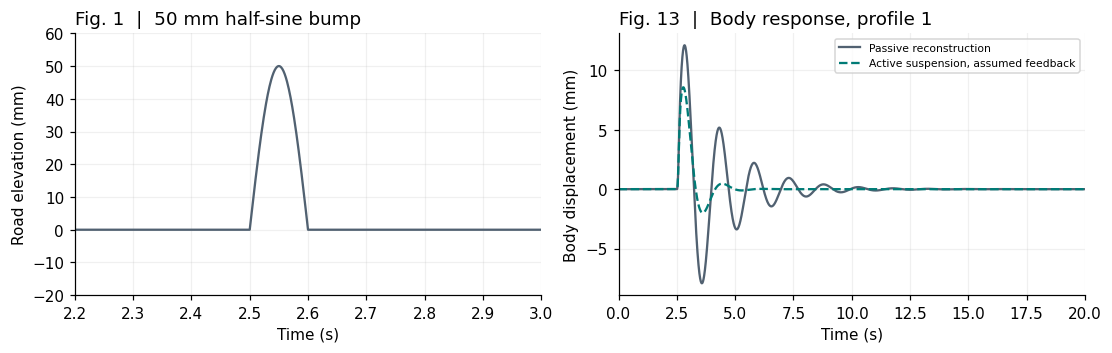

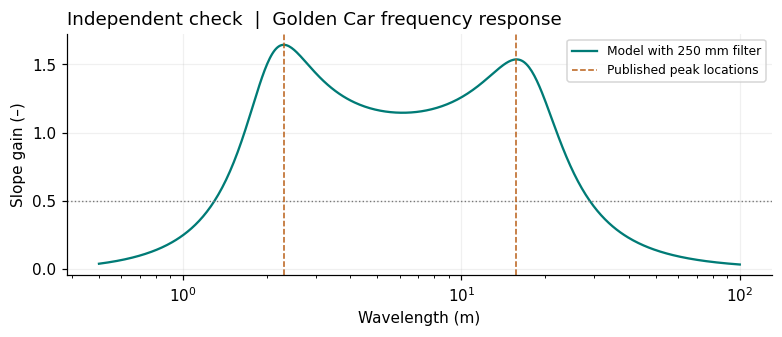

"Reference point, Fig. 7",Published (m),Model (m),Difference (m)
Short-wavelength peak,2.300,2.304,0.004
Long-wavelength peak,15.780,15.779,-0.001
"0.5 gain, lower crossing",1.250,1.301,0.051
"0.5 gain, upper crossing",30.000,28.904,-1.096


In [5]:
# A. Samaroo dkk., Fig. 1 dan kurva pasif pada Fig. 13 (profil 1).
# Parameter publikasi sengaja terpisah dari kendaraan untuk desain ATMD.
reference_car = Vehicle(body_mass=250, wheel_mass=45, suspension_stiffness=6500,
                        tire_stiffness=15000, suspension_damping=285, tire_damping=1600)
paper_time = np.linspace(0,20,20001)
phase_time = paper_time - 2.5
paper_road = np.where((phase_time >= 0) & (phase_time <= .1), .05*np.sin(10*np.pi*phase_time), 0.)
paper_dynamics, paper_inputs = state_matrices(reference_car)
# Turunan jalan diskontinu di kaki benjolan. Kemiringan ruas linear memberi
# luas dan amplitudo yang konsisten dengan road profile; lsim memakai grid 1 ms.
paper_road_speed = np.gradient(paper_road, paper_time)
body_output = np.array([[1.,0.,0.,0.]])
_, paper_body, _ = signal.lsim((paper_dynamics,paper_inputs[:,:2],body_output,np.zeros((1,2))),
                                np.column_stack((paper_road,paper_road_speed)),paper_time)
# Rekonstruksi pembanding aktif paper (aktuator bodi–roda), dengan hipotesis e=-z_s.
# Karena force linear di bawah batas paper, solusi linear di kasus ini sah.
reference_force_direction = np.array([0.,0.,1/250.,-1/45.])
reference_feedback = np.array([5.,0.,900.,0.])
reference_active_matrix = paper_dynamics - np.outer(reference_force_direction,reference_feedback)
_, reconstructed_active_body, reconstructed_active_state = signal.lsim(
    (reference_active_matrix,paper_inputs[:,:2],body_output,np.zeros((1,2))),
    np.column_stack((paper_road,paper_road_speed)),paper_time)
assert np.max(np.abs(reconstructed_active_state@reference_feedback)) < 500
reference_rms_gain = 100*(1-np.sqrt(np.sum(reconstructed_active_body**2)/np.sum(paper_body**2)))
fig, axes = plt.subplots(1,2,figsize=(10,3.1))
axes[0].plot(paper_time,paper_road*1000,color="#516171")
axes[0].set(xlim=(2.2,3.),ylim=(-20,60),xlabel="Time (s)",ylabel="Road elevation (mm)", title="Fig. 1  |  50 mm half-sine bump")
axes[1].plot(paper_time,1000*paper_body,color=colors["Standard"],label="Passive reconstruction")
axes[1].plot(paper_time,1000*reconstructed_active_body,color="#007b76",ls="--",label="Active suspension, assumed feedback")
axes[1].legend(fontsize=7)
axes[1].set(xlim=(0,20),xlabel="Time (s)",ylabel="Body displacement (mm)", title="Fig. 13  |  Body response, profile 1")
plt.show()
print(f"Fig. 1: puncak {1000*max(paper_road):.3f} mm pada {paper_time[np.argmax(paper_road)]:.3f} s "
      "(acuan 50 mm pada 2,550 s); durasi rumus 0,100 s.")
print(f"Fig. 13: puncak positif {1000*max(paper_body):.3f} mm; minimum {1000*min(paper_body):.3f} mm.")
print(f"RMS simpangan aktif vs pasif (0–20 s): {reference_rms_gain:.2f}% vs 56% di paper; "
      f"selisih {reference_rms_gain-56:+.2f} poin persen.")
# B. Karamihas, Gambar 7: gain antara slope profil dan slope stroke suspensi.
# Faktor jω/v untuk slope saling meniadakan pada pembilang dan penyebut.
golden_reference = Vehicle(body_mass=1., wheel_mass=.15, suspension_stiffness=63.3,
                           tire_stiffness=653., suspension_damping=6., tire_damping=0.)
golden_mass, golden_stiffness, golden_damping, golden_wheel, _ = mechanical_matrices(golden_reference)
def slope_gain(wavelength):
    speed = 80/3.6
    angular_frequency = 2*np.pi*speed/wavelength
    impedance = golden_stiffness + 1j*angular_frequency*golden_damping - angular_frequency**2*golden_mass
    response = np.linalg.solve(impedance, golden_wheel*golden_reference.tire_stiffness)
    return abs((response[0]-response[1]) * np.sinc(.25/wavelength))

wavelengths = np.geomspace(.5,100,500)
figure_gain = np.array([slope_gain(length) for length in wavelengths])
short_peak = minimize_scalar(lambda length: -slope_gain(length), bounds=(1.6,3.6),method="bounded").x
long_peak = minimize_scalar(lambda length: -slope_gain(length), bounds=(10,22),method="bounded").x
reproduction = pd.DataFrame({"Reference point, Fig. 7":["Short-wavelength peak","Long-wavelength peak","0.5 gain, lower crossing","0.5 gain, upper crossing"],
    "Published (m)":[2.30,15.78,1.25,30.0],
    "Model (m)":[short_peak,long_peak,brentq(lambda w:slope_gain(w)-.5,1,2),
                 brentq(lambda w:slope_gain(w)-.5,20,50)]})
reproduction["Difference (m)"] = reproduction["Model (m)"]-reproduction["Published (m)"]
fig, ax = plt.subplots(figsize=(7,2.95))
ax.semilogx(wavelengths,figure_gain,color="#007b76",label="Model with 250 mm filter")
ax.axhline(.5,color="#777",lw=.9,ls=":")
for idx, value in enumerate((2.30,15.78)):
    ax.axvline(value,ls="--",color="#b95f17",lw=1,label="Published peak locations" if idx==0 else None)
ax.set(xlabel="Wavelength (m)",ylabel="Slope gain (–)",title="Independent check  |  Golden Car frequency response")
ax.legend(fontsize=8); plt.show()
show_table(reproduction,3)

## 3 · Road input dan pembagian skenario

Audit ulang membandingkan 25.612 baris di `ATMD_measured_spatial_vectors.csv` (11 kolom) dan `cph1_aran_hh.csv` (80 kolom). Setelah *origin* jarak disamakan, *maximum distance difference* adalah sekitar 0,00000302 m dan *maximum elevation difference* sekitar 0,00000005 m. Sebanyak 36 baris memiliki *jump flag* pada seluruh lintasan. Sel di bawah mengulangi audit ketika kedua CSV tersedia.

| Kolom | Besaran | Penggunaan |
|---|---|---|
| `distance_m` | Jarak 0–25.611 m, interval 1 m | *Spatial axis*. Konversi ke waktu memakai kecepatan pada tabel skenario. |
| `elevation_m` | *Absolute route elevation*, m | *Detrending* menghasilkan proksi *road roughness* yang masih dipengaruhi resolusi dan posisi sensor. |
| `iri_*_m_per_km`, `rut_*_mm`, `mpd_*_mm` | *Roughness index*, *rut depth*, *texture depth* | Besaran ringkasan ini disimpan terpisah dari *signed road displacement*. |
| `suspect_elevation_jump_gt_0p2m_per_m` | *Quality flag* | Segmen terpilih harus bebas *flag* dan lulus pemeriksaan kemiringan. |

Cuplikan bawaan berisi 97 titik dari meter 500–596. Pada 12 m/s, waktu tempuh adalah 8 s. *Spatial Nyquist limit* 0,5 siklus/m setara dengan 6 Hz. *Time interpolation* mempertahankan batas informasi ini. *Savitzky–Golay filter* orde 2 memakai 21 titik. *Taper* diterapkan pada 8 m di kedua ujung. Hasil pada segmen ini bersifat eksploratif. Deskripsi data ARAN tersedia di [7, tab. 9].

**SHA-256.** Untuk CSV turunan, `28c61fc286ec151ec2d85d679a735e68f9b26751c9afae345da38501c959e693`. Untuk CSV sumber, `acd5569ddbdd10bc6a4c03777322cedca61e736561dc1129509b9e69ac9dd6c8`.

Cuplikan CSV yang disematkan · 97 titik · puncak absolut residu 16.37 mm


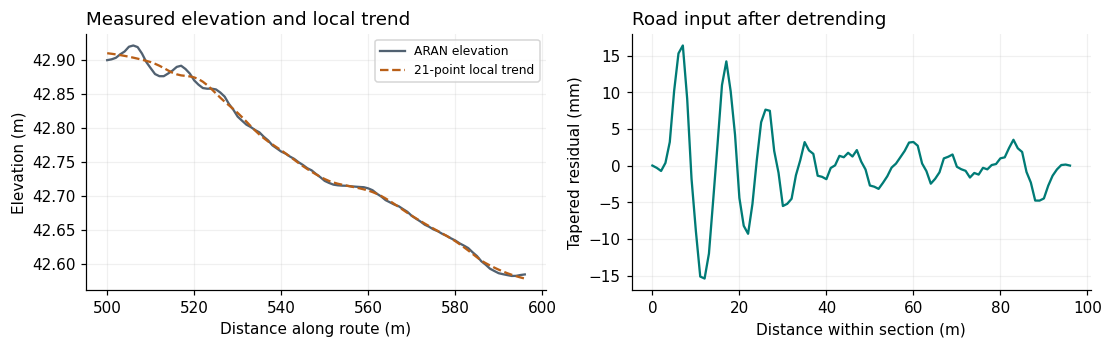

In [6]:
# Potongan sumber asli disematkan agar Run all bekerja tanpa upload.
# Ketelitian desimal mengikuti CSV turunan. Sumbu jarak absolut pada berkas dimulai dari 0 m.
default_segment_start = 500
embedded_segment_start = 500          # lokasi asli cuplikan yang disematkan
segment_length_m = 96
embedded_elevation = np.array([
    42.899912, 42.9010993, 42.903354, 42.9085201, 42.9126336, 42.9196751, 42.9215118, 42.9191418,
    42.9096445, 42.8970438, 42.888103, 42.8794461, 42.8762901, 42.8762824, 42.8802089, 42.8845005,
    42.890001, 42.8916753, 42.8868864, 42.8801391, 42.8700749, 42.8637427, 42.8588203, 42.8578416,
    42.8579338, 42.8568117, 42.852279, 42.846233, 42.8353574, 42.8268786, 42.8166881, 42.81074,
    42.8049177, 42.801408, 42.7970297, 42.793521, 42.787073, 42.781706, 42.7743548, 42.7698666,
    42.7653096, 42.762281, 42.7579809, 42.7544617, 42.7495412, 42.7455492, 42.7407967, 42.7376135,
    42.7322777, 42.727544, 42.7221016, 42.7191034, 42.7166, 42.7155916, 42.7150713, 42.7149097,
    42.7141565, 42.7136177, 42.7131541, 42.7127542, 42.7111054, 42.7083549, 42.7032313, 42.6990446,
    42.6937458, 42.6905178, 42.6872324, 42.6848116, 42.6806191, 42.6765742, 42.6706924, 42.6663801,
    42.6623221, 42.6575691, 42.6545332, 42.6506189, 42.6480119, 42.644204, 42.641238, 42.6375905,
    42.6343903, 42.630142, 42.6267868, 42.6231139, 42.6169554, 42.6114222, 42.6037565, 42.5986523,
    42.5927667, 42.5893665, 42.5861063, 42.5846437, 42.583317, 42.5820902, 42.5822235, 42.5834556,
    42.5843059
])

def audit_original_pair(derived_csv, survey_csv):
    derived = pd.read_csv(derived_csv, usecols=["distance_m","elevation_m","suspect_elevation_jump_gt_0p2m_per_m"])
    survey = pd.read_csv(survey_csv, sep=";", encoding="latin1", usecols=["BeginChainage","Elevation (m)"])
    if len(derived)!=len(survey) or len(derived)<2:
        raise ValueError("Jumlah sampel CSV turunan dan survei tidak sesuai.")
    if not np.isfinite(derived.to_numpy()).all() or not np.isfinite(survey.to_numpy()).all():
        raise ValueError("Jarak, elevasi, atau flag memiliki nilai yang tidak valid.")
    relative_chainage = survey["BeginChainage"]-survey["BeginChainage"].iloc[0]
    distance_error = np.max(abs(derived["distance_m"]-relative_chainage))
    elevation_error = np.max(abs(derived["elevation_m"]-survey["Elevation (m)"]))
    if distance_error>1e-4 or elevation_error>1e-5:
        raise ValueError("Registrasi posisi atau satuan elevasi kedua file tidak cocok dengan cuplikan.")
    return {"Jumlah baris":len(derived),"Selisih jarak maks (m)":distance_error,
            "Selisih elevasi maks (m)":elevation_error,"Jumlah flag":int(derived["suspect_elevation_jump_gt_0p2m_per_m"].ne(0).sum())}

if Path("ATMD_measured_spatial_vectors.csv").is_file() and Path("cph1_aran_hh.csv").is_file():
    print("Audit kedua file yang diunggah:",audit_original_pair("ATMD_measured_spatial_vectors.csv","cph1_aran_hh.csv"))

def load_measured_segment(start_m=default_segment_start, full_csv="ATMD_measured_spatial_vectors.csv"):
    path = Path(full_csv)
    if path.is_file():
        data = pd.read_csv(path, usecols=["distance_m","elevation_m","suspect_elevation_jump_gt_0p2m_per_m"])
        distance = data["distance_m"].to_numpy(dtype=float)
        if not np.isfinite(distance).all() or not np.all(np.diff(distance)>0):
            raise ValueError("distance_m harus berhingga dan naik ketat dalam meter.")
        sample = data[data.distance_m.between(start_m,start_m+segment_length_m)].copy()
        distance = sample.distance_m.to_numpy()
        elevation = sample.elevation_m.to_numpy()
        if not (sample.suspect_elevation_jump_gt_0p2m_per_m == 0).all():
            raise ValueError("Segmen memuat flag lompatan atau flag kosong. Pilih awal lain.")
        source = path.name
    else:
        if start_m != embedded_segment_start:
            raise ValueError("Untuk segmen di luar 500–596 m, unggah CSV lengkap ke folder notebook.")
        distance = embedded_segment_start + np.arange(len(embedded_elevation))
        elevation = embedded_elevation.copy()
        source = "Cuplikan CSV yang disematkan"
    if len(distance)!=segment_length_m+1 or not np.allclose(np.diff(distance),1.0,atol=1e-4):
        raise ValueError("Dibutuhkan 97 sampel berurutan dengan interval 1 m.")
    if not np.isfinite(elevation).all() or np.any(np.abs(np.diff(elevation)/np.diff(distance))>.2):
        raise ValueError("Segmen tidak lolos cek elevasi atau kemiringan.")
    local_distance = distance-distance[0]
    trend = signal.savgol_filter(elevation,window_length=21,polyorder=2)
    # Taper 8 m di tiap ujung membuat sambungan ke jalan datar halus.
    edge_fraction = np.minimum(np.minimum(local_distance,local_distance[-1]-local_distance)/8,1.)
    taper = .5*(1-np.cos(np.pi*edge_fraction))
    return local_distance,elevation,trend,(elevation-trend)*taper,source

profile_distance, survey_elevation, survey_trend, profile_residual, profile_source = load_measured_segment()
fig, axes = plt.subplots(1,2,figsize=(10,3.05))
axes[0].plot(profile_distance+default_segment_start,survey_elevation,label="ARAN elevation",color="#516171")
axes[0].plot(profile_distance+default_segment_start,survey_trend,ls="--",label="21-point local trend",color="#b95f17")
axes[0].set(xlabel="Distance along route (m)",ylabel="Elevation (m)",title="Measured elevation and local trend")
axes[0].legend(fontsize=8)
axes[1].plot(profile_distance,1000*profile_residual,color="#007b76")
axes[1].set(xlabel="Distance within section (m)",ylabel="Tapered residual (mm)",title="Road input after detrending")
plt.show()
print(f"{profile_source} · {len(profile_distance)} titik · puncak absolut residu {np.max(np.abs(profile_residual))*1000:.2f} mm")

### Dua synthetic road profiles

*Smooth bump* mengikuti $y(x)=h[1-\cos(2\pi x/L)]/2$ pada $0\le x\le L$ sehingga *slope* dan *height* kembali ke nol pada kedua ujung. *Sinusoidal road* mengikuti $y(x)=A_r\sin(2\pi x/\lambda)$ dengan *smooth ramp* selama satu panjang gelombang. *Excitation frequency* adalah $f=v/\lambda$.

Keempat konfigurasi menerima *road samples* dan *initial conditions* yang sama pada setiap skenario. Hanya dua baris **Tuning** yang menentukan *controller gains*. Skenario **Evaluation** mengubah amplitudo, frekuensi, *sprung mass*, atau jenis jalan. Semua *gains*, $k_a$, dan $c_a$ dibekukan sebelum evaluasi.

In [7]:
@dataclass(frozen=True)
class Scenario:
    name: str
    road_type: str
    amplitude_m: float
    length_m: float        # lebar satu benjolan atau panjang gelombang sinus
    speed_m_s: float
    mass_factor: float = 1.0
    duration_s: float = 8.0
    onset_s: float = .5

    def __post_init__(self):
        if self.road_type not in ("bump","sine","measured"):
            raise ValueError("Profile harus bump, sine, atau measured.")
        if min(self.length_m,self.speed_m_s,self.mass_factor)<=0 or self.duration_s <= self.onset_s or self.onset_s < 0:
            raise ValueError("Panjang, kecepatan dan massa harus positif. Durasi harus melewati onset.")

training = [
    Scenario("Training bump","bump",.012,3.0,10),
    Scenario("Training sine","sine",.0030,10.0,12)]
evaluation = [
    Scenario("Smooth bump","bump",.022,2.5,10),
    Scenario("Nominal sine","sine",.004,10.0,12),
    Scenario("Sprung mass +25%","sine",.004,10.0,12,1.25),
    Scenario("Sprung mass −20%","sine",.004,10.0,12,.80),
    Scenario("Low frequency","sine",.004,10.0,8),
    Scenario("High frequency","sine",.004,10.0,16),
    Scenario("High mass and frequency","sine",.004,10.0,16,1.25),
    Scenario("High-amplitude sine","sine",.030,10.0,12),
    Scenario("ARAN section","measured",0.,96.,12.,duration_s=10)]
def sinusoidal_profile(cycles, amplitude):
    ramp = .5*(1-np.cos(np.pi*np.clip(cycles,0,1)))
    return amplitude*ramp*np.sin(2*np.pi*cycles)

def road_input(time, scenario):
    distance = (time-scenario.onset_s)*scenario.speed_m_s
    if scenario.road_type=="bump":
        fraction = np.clip(distance/scenario.length_m,0.,1.)
        return .5*scenario.amplitude_m*(1-np.cos(2*np.pi*fraction))
    if scenario.road_type=="sine":
        return sinusoidal_profile(distance/scenario.length_m,scenario.amplitude_m)
    if scenario.road_type=="measured":
        return np.interp(distance,profile_distance,profile_residual,left=0.,right=0.)
    raise ValueError(f"Jenis profil tidak dikenal: {scenario.road_type}")

def scenario_row(s, group):
    return [group,s.name,s.road_type,s.amplitude_m*1000 if s.road_type!="measured" else np.nan,
            s.length_m,s.speed_m_s,s.speed_m_s/s.length_m if s.road_type=="sine" else np.nan,
            s.mass_factor,s.duration_s]
show_table(pd.DataFrame([scenario_row(s,g) for g,group in [("Tuning",training),("Evaluation",evaluation)]
                         for s in group],columns=["Set","Scenario","Profile","Road amplitude (mm)","Profile length (m)",
                                                  "v (m/s)","f (Hz)","Sprung mass factor","Duration (s)"]),2)

Set,Scenario,Profile,Road amplitude (mm),Profile length (m),v (m/s),f (Hz),Sprung mass factor,Duration (s)
Tuning,Training bump,bump,12.00,3.00,10.00,—,1.00,8.00
Tuning,Training sine,sine,3.00,10.00,12.00,1.20,1.00,8.00
Evaluation,Smooth bump,bump,22.00,2.50,10.00,—,1.00,8.00
Evaluation,Nominal sine,sine,4.00,10.00,12.00,1.20,1.00,8.00
Evaluation,Sprung mass +25%,sine,4.00,10.00,12.00,1.20,1.25,8.00
Evaluation,Sprung mass −20%,sine,4.00,10.00,12.00,1.20,0.80,8.00
Evaluation,Low frequency,sine,4.00,10.00,8.00,0.80,1.00,8.00
Evaluation,High frequency,sine,4.00,10.00,16.00,1.60,1.00,8.00
Evaluation,High mass and frequency,sine,4.00,10.00,16.00,1.60,1.25,8.00
Evaluation,High-amplitude sine,sine,30.00,10.00,12.00,1.20,1.00,8.00


## 4 · Passive tuning, PID, dan LQR

TMD pasif menjadi acuan untuk mengukur manfaat tambahan dari motor. Pencarian memilih *tuning frequency* dan *damping ratio* yang meminimumkan maksimum $|Z_s/Y|$ pada pita 0,65–1,50 kali *undamped body-mode frequency*. Hasil untuk *small-signal model* ini selanjutnya diuji dengan *end stops* yang sama pada ketiga konfigurasi bermassa tambahan.

In [8]:
# Minimax gain |z_s/y| pada pita yang ditetapkan sebelum melihat data evaluasi.
nominal_body_hz = modes_hz(vehicle)[0]
design_frequencies = nominal_body_hz*np.linspace(.65,1.5,121)
def passive_band_peak(ratio, damping_ratio):
    omega_absorber = 2*np.pi*nominal_body_hz*ratio
    design = Absorber(vehicle.absorber_mass*omega_absorber**2,
                      2*damping_ratio*vehicle.absorber_mass*omega_absorber)
    mass, stiffness, damping, wheel, _ = mechanical_matrices(vehicle,design)
    omega = 2*np.pi*design_frequencies[:,None,None]
    impedance = stiffness + 1j*omega*damping - omega**2*mass
    excitations = (vehicle.tire_stiffness+1j*omega[:,0,0,None]*vehicle.tire_damping)*wheel
    response = np.linalg.solve(impedance,excitations[:,:,None])[:,:,0]
    return np.max(abs(response[:,0])),design
passive_trials = [(passive_band_peak(ratio,zeta),ratio,zeta)
                  for ratio in np.linspace(.75,1.05,21) for zeta in np.linspace(.06,.35,16)]
(best_gain, tuned_absorber),best_ratio,best_zeta = min(passive_trials,key=lambda row:row[0][0])
print(f"TMD terpilih. Frequency ratio {best_ratio:.3f}, damping ratio {best_zeta:.3f}, maximum gain {best_gain:.3f}.")
print(f"kₐ = {tuned_absorber.stiffness:.2f} N/m, cₐ = {tuned_absorber.damping:.2f} N·s/m.")
static_weight = vehicle.absorber_mass*9.80665
print(f"Berat absorber {static_weight:.1f} N. Tanpa preload, static spring deflection "
      f"{1000*static_weight/tuned_absorber.stiffness:.0f} mm untuk dibandingkan dengan ruang dari tengah.")

TMD terpilih. Frequency ratio 0.840, damping ratio 0.157, maximum gain 1.721.
kₐ = 488.03 N/m, cₐ = 23.98 N·s/m.
Berat absorber 117.7 N. Tanpa preload, static spring deflection 241 mm untuk dibandingkan dengan ruang dari tengah.


### Feedback dan implementasi controller

**Proportional–integral–derivative (PID).** Definisikan $e=-z_s+\beta r$. Parameter $\beta$ menentukan bobot *absorber stroke*. Komponen *derivative* memakai kecepatan yang diasumsikan terukur. Satuan $K_p,K_i,K_d$ berturut-turut adalah N/m, N/(m·s), dan N·s/m. Dengan $I$ dalam N,

$$u^*=K_pe+K_d\dot e+I,\qquad \dot I=K_ie+(u-u^*)/T_{aw}-\ell I.$$

$u$ adalah *applied force* setelah *clipping*. Selisih $u-u^*$ memberi *back-calculation anti-windup*. *Integral leakage* $\ell=0{,}15\ \mathrm{s^{-1}}$ membatasi akumulasi bias. Nilai $K_i=0$ menonaktifkan cabang integral.

**Linear quadratic regulator (LQR).** Dengan seluruh *state vector* tersedia, $u^*=-Kx$. *Continuous-time algebraic Riccati equation* menghasilkan $K$ dari *linear model* tanpa kontak. *Cost function* memuat *body displacement*, *body velocity*, *relative stroke*, *relative velocity*, dan *actuator force*. Semakin besar *force scale*, semakin kecil penalti gaya $R$. Kedua *controllers* memakai *sample time*, *peak force limit*, dan *end stops* yang sama. Beban sensor aktual untuk memperoleh enam *states* belum dimasukkan.

In [9]:
@dataclass(frozen=True)
class Controller:
    label: str
    family: str
    feedback: tuple = (0.,)*6      # u perintah = -feedback @ x + kontribusi integral
    integral_gain: float = 0.
    stroke_mix: float = 0.
    parameters: tuple = ()

standard = Controller("Standard","Standard")
passive = Controller("TMD","TMD")
def design_pid(label, proportional, integral, derivative, stroke_mix=.15):
    # y = z_s - beta*(z_a-z_s) ; e = -y; d(e)/dt dari kecepatan terukur.
    position_output = np.array([1+stroke_mix,0.,-stroke_mix])
    feedback = np.r_[proportional*position_output,derivative*position_output]
    return Controller(label,"PID",tuple(feedback),integral,stroke_mix,
                      (proportional,integral,derivative,stroke_mix))

def design_lqr(label, force_scale, stroke_weight):
    dynamics,inputs = state_matrices(vehicle,tuned_absorber)
    # Bryson scaling. Masing-masing baris mengubah satu besaran ke bentuk tak berdimensi.
    outputs = np.array([[1/.010,0,0,0,0,0], [0,0,0,1/.15,0,0],
                        [-1/.040,0,1/.040,0,0,0], [0,0,0,-1/.5,0,1/.5]])
    cost = outputs.T@np.diag([1., .20, stroke_weight, .025])@outputs + np.eye(6)*1e-9
    force_penalty = np.array([[1./force_scale**2]])
    actuator_input = inputs[:,2:3]
    riccati = linalg.solve_continuous_are(dynamics,actuator_input,cost,force_penalty)
    gain = np.linalg.solve(force_penalty,actuator_input.T@riccati)[0]
    return Controller(label,"LQR",tuple(gain),parameters=(force_scale,stroke_weight))

# Peluruhan lambat membatasi bias akibat target simpangan absolut; integral dalam satuan N.
integral_leak_rate = .15              # 1/s
tracking_time_s = .075                 # s, tracking anti-windup

### End-stop contact, solver, dan output metrics

Jika $d=\max(0,|r|-r_0)$ adalah *bumper compression*, maka gaya kontak pada bodi adalah

$$F_b=\operatorname{sign}(r)\{k_bd+c_b\max[0,\operatorname{sign}(r)\dot r]\min(d/d_0,1)\}.$$

*Contact damping* bekerja saat kompresi dan meningkat bertahap pada $d_0=1$ mm pertama. Satu *contact event* dimulai saat gaya kontak berubah dari nol menjadi aktif. Jika $|r|>47{,}5$ mm, lintasan sudah melampaui *rated stroke*. *Normal tire load* dihitung dari berat statis sudut kendaraan dan gaya ban dinamis. Nilai negatif menunjukkan bahwa asumsi ban selalu menempel pada jalan telah dilanggar.

*Solver* memakai *matrix exponential* untuk bagian linear, *road elevation* rata-rata per langkah, dan *zero-order hold* untuk *motor force*. *Contact force* diperbarui setiap 0,5 ms dan *controller* setiap 2 ms.

| Output | Definisi operasional |
|---|---|
| *Peak body displacement* | $p=\max_t\lvert z_s(t)\rvert$ selama seluruh rekaman, termasuk *startup transient*. |
| *Additional peak reduction* | $100(1-p_{\mathrm{active}}/p_{\mathrm{TMD}})$ pada jalan, massa, dan *end stops* yang sama. Nilai negatif berarti *active peak* lebih besar. |
| *Root mean square* (RMS) | $\sqrt{\int_{t_1}^{t_2}a^2\,dt/(t_2-t_1)}$. Untuk sinus digunakan tiga periode terakhir setelah *ramp* jika tersedia. Untuk *bump* dan segmen ARAN digunakan waktu sejak *onset* sampai akhir. Tabel menyertakan batas waktu aktual. |
| *Force*, *stroke*, dan *hardware screen* | Laporkan *peak/RMS motor force*, $\max\lvert r\rvert$, dan *contact count*. Syarat awal mencakup *stroke* ≤47,5 mm, *relative speed* ≤2,5 m/s, *normal tire load* ≥0, dan nilai terbesar antara *onset-to-end RMS force* dan *analysis-window RMS force* ≤62 N. |
| *Power* dan *energy* | $P_m=u(\dot z_s-\dot z_a)$. Untuk $P_m>0$, estimasi *electrical input power* adalah $P_m/0{,}95$. Untuk $P_m<0$, *absorbed mechanical energy* dicatat tanpa kredit regenerasi. *Holding current*, *copper losses*, dan *standby power* memerlukan model drive tambahan. |

In [10]:
def end_stop_force(travel, relative_velocity, clearance, limits):
    depth = np.maximum(np.abs(travel)-clearance, 0.)
    direction = np.sign(travel)
    approach_speed = np.maximum(direction*relative_velocity,0.)
    engagement = np.minimum(depth/limits.transition_length,1.)
    return direction*(limits.stop_stiffness*depth + limits.stop_damping*approach_speed*engagement)

def update_integral_force(integral, error, integral_gain, applied_force, requested_force):
    increment = (integral_gain*error + (applied_force-requested_force)/tracking_time_s
                 - integral_leak_rate*integral)
    return integral + control_period*(integral_gain>0)*increment

@lru_cache(maxsize=60)
def discrete_plant(car, absorber, step):
    dynamics, inputs = state_matrices(car,absorber)
    count, inputs_count = inputs.shape
    augmented = np.zeros((count+inputs_count,count+inputs_count))
    augmented[:count,:count] = dynamics
    augmented[:count,count:] = inputs
    transition = linalg.expm(augmented*step)
    return transition[:count,:count],transition[:count,count:]

def stable_nominal(controller):
    # Peta closed-loop satu periode kontrol tanpa clipping/kontak.
    transition, inputs = discrete_plant(vehicle,tuned_absorber,control_period)
    gain = np.asarray(controller.feedback)
    feedback_map = transition-np.outer(inputs[:,2],gain)
    if controller.family=="PID" and controller.integral_gain>0:
        beta = controller.stroke_mix
        output = np.array([1+beta,0,-beta,0,0,0])
        feedback_map = np.block([[feedback_map,inputs[:,2:3]],
                                 [-control_period*controller.integral_gain*output[None,:],
                                  np.array([[1-control_period*integral_leak_rate]])]])
    return np.max(np.abs(np.linalg.eigvals(feedback_map))) < 1.

@dataclass
class Trace:
    time: np.ndarray
    road: np.ndarray
    body: np.ndarray
    wheel: np.ndarray
    absorber: np.ndarray
    relative_speed: np.ndarray
    force: np.ndarray
    request: np.ndarray
    contact_force: np.ndarray
    attached: bool

def simulate(scenario, controllers, limits=hardware, step=integration_step, *, stops=True, force_limit=True, model_vehicle=None):
    # Satu batch memiliki massa dan komponen yang sama. Kendaraan standar memakai model 2-DOF.
    if not controllers:
        return {}
    attached = controllers[0].family!="Standard"
    if any((control.family!="Standard")!=attached for control in controllers):
        raise ValueError("Pisahkan kendaraan 2-DOF dan 3-DOF dalam pemanggilan simulator.")
    if len({c.label for c in controllers})!=len(controllers):
        raise ValueError("Label kandidat dalam satu batch harus unik.")
    ctrl_stride = round(control_period/step)
    if ctrl_stride<1 or not np.isclose(ctrl_stride*step,control_period):
        raise ValueError("Periode kontrol harus kelipatan bulat dari langkah integrasi.")
    base_vehicle = vehicle if model_vehicle is None else model_vehicle
    car = replace(base_vehicle,body_mass=base_vehicle.body_mass*scenario.mass_factor)
    transition, inputs = discrete_plant(car,tuned_absorber if attached else None,step)
    time = np.arange(round(scenario.duration_s/step)+1)*step
    road = road_input(time,scenario)
    road_average = .5*(road[:-1]+road[1:])
    road_slope = np.diff(road)/step
    road_effect = road_average[:,None]*inputs[:,0] + road_slope[:,None]*inputs[:,1]
    count = len(controllers)
    states = np.zeros((len(time),count,len(transition)))
    force_history = np.zeros((len(time),count))
    command_history = np.zeros_like(force_history)
    contacts = np.zeros_like(force_history)
    force = np.zeros(count); command = np.zeros(count); integral_force = np.zeros(count)
    gains = np.array([c.feedback for c in controllers])
    integral_gains = np.array([c.integral_gain for c in controllers])
    stroke_weights = np.array([c.stroke_mix for c in controllers])
    for index in range(len(time)):
        state = states[index]
        if attached:
            travel = state[:,2]-state[:,0]
            relative_speed = state[:,5]-state[:,3]
            if index % ctrl_stride == 0:
                command = -np.einsum("ij,ij->i",gains,state)+integral_force
                force = np.clip(command,-limits.peak_force,limits.peak_force) if force_limit else command
                error = -state[:,0]+stroke_weights*travel
                integral_force = update_integral_force(integral_force,error,integral_gains,force,command)
            force_history[index] = force
            command_history[index] = command
            contact = contacts[index]
            if stops:
                if np.any(np.abs(travel)>limits.stop_onset):
                    contact[:] = end_stop_force(travel,relative_speed,limits.stop_onset,limits)
        if index+1==len(time):
            break
        next_state = state@transition.T + road_effect[index]
        if attached:
            next_state += (force+contacts[index])[:,None]*inputs[:,2]
        states[index+1] = next_state

    result = {}
    for column,controller in enumerate(controllers):
        history = states[:,column,:]
        if attached:
            absorber_position = history[:,2]
            speed = history[:,5]-history[:,3]
        else:
            absorber_position = np.full(len(time),np.nan)
            speed = np.zeros(len(time))
        result[controller.label] = Trace(time,road,history[:,0],history[:,1],absorber_position,speed,
              force_history[:,column],command_history[:,column],contacts[:,column],attached)
    return result

def metrics(trace, scenario, limits=hardware, model_vehicle=None):
    base_vehicle = vehicle if model_vehicle is None else model_vehicle
    t = trace.time
    start = scenario.onset_s
    # RMS sinus pada tiga periode terakhir setelah ramp, jika rekaman cukup. Smooth bump/ARAN dari onset sampai akhir.
    start_rms = (max(start+scenario.length_m/scenario.speed_m_s, t[-1]-3*scenario.length_m/scenario.speed_m_s)
                 if scenario.road_type=="sine" else start)
    if start_rms >= t[-1]:
        raise ValueError("Perpanjang durasi skenario agar jendela RMS memiliki data setelah ramp.")
    window = t>=start_rms-1e-10
    def rms_window(values):
        return np.sqrt(trapezoid(values[window]**2,t[window])/(t[-1]-t[window][0]))
    # Puncak, energi dan jumlah peristiwa selalu pada seluruh rekaman, termasuk transien.
    force = trace.force
    mechanical_power = -force*trace.relative_speed
    if trace.attached:
        stroke = np.abs(trace.absorber-trace.body)
        peak_travel = np.max(stroke)*1000
        in_contact = np.abs(trace.contact_force)>0
        events = int(np.count_nonzero(np.diff(in_contact.astype(int),prepend=0)==1))
        maximum_compression = max(0.,peak_travel-1000*limits.stop_onset)
    else:
        peak_travel = maximum_compression = np.nan
        events = 0
    active_interval = t>=start-1e-10
    rms_duty = np.sqrt(trapezoid(force[active_interval]**2,t[active_interval])/
                       (t[-1]-t[active_interval][0]))
    static_mass = base_vehicle.body_mass*scenario.mass_factor + base_vehicle.wheel_mass
    if trace.attached:
        static_mass += base_vehicle.absorber_mass
    tire_compression = trace.road-trace.wheel
    normal_force = static_mass*9.80665 + base_vehicle.tire_stiffness*tire_compression
    if base_vehicle.tire_damping:
        normal_force += base_vehicle.tire_damping*np.gradient(tire_compression,t)
    return dict(peak_mm=1000*np.max(np.abs(trace.body)),rms_mm=1000*rms_window(trace.body),
                peak_force_N=np.max(np.abs(force)),rms_force_N=rms_window(force), duty_rms_N=rms_duty,
                stroke_mm=peak_travel,contact_events=events,compression_mm=maximum_compression,
                contact_peak_N=np.max(np.abs(trace.contact_force)),speed_m_s=np.max(abs(trace.relative_speed)),
                sat_pct=100*np.mean(np.abs(trace.request[active_interval]-force[active_interval])>1e-7),
                motor_energy_J=trapezoid(np.maximum(mechanical_power,0)/limits.efficiency,t),
                absorbed_energy_J=trapezoid(np.maximum(-mechanical_power,0),t),
                power_peak_W=np.max(np.maximum(mechanical_power,0))/limits.efficiency,
                tire_normal_min_N=np.min(normal_force),rms_from_s=t[window][0],rms_to_s=t[-1])

def screened(row, limits=hardware):
    # Penyaringan awal untuk batas langkah, kecepatan, dan beban gaya berulang.
    return ((np.isnan(row["stroke_mm"]) or row["stroke_mm"]<=limits.half_travel*1000)
            and row["tire_normal_min_N"]>=0
            and row["speed_m_s"]<=limits.speed_reference
            and max(row["rms_force_N"],row["duty_rms_N"])<=limits.continuous_force+1e-7)

def batch_metrics(scenario, controls, **options):
    traces = simulate(scenario,controls,**options)
    return {name:metrics(result,scenario,options.get("limits",hardware),options.get("model_vehicle")) for name,result in traces.items()}

### Automatic tuning pada target yang sebanding

Seleksi memakai dua *training cases* berbobot sama. Kandidat harus stabil, lolos *hardware screen*, bebas kontak, dan memiliki penurunan terburuk minimal −3% terhadap TMD. Target bersama ditetapkan sebesar 80% dari *mean additional peak reduction* terbaik yang dapat dicapai kedua keluarga. Di antara pasangan yang mencapai target dengan selisih maksimal satu poin persentase, dipilih pasangan dengan jumlah *mean RMS force* terendah. Tabel menampilkan kedua *training cases* secara terpisah. Pencarian ini terbatas pada *gain grid* yang dinyatakan dalam kode.

In [11]:
# Desain memenuhi stabilitas linear nominal sebelum masuk simulasi nonlinear.
candidate_list = []
for proportional, integral_ratio, derivative, mix in product(
        (0.,800.,2500.,6000.,12000.),(.12,.28,.65), (35.,180.,550.,1150.),(0.,.2,.7)):
    integral = max(proportional,100.)*integral_ratio
    tuning = design_pid(f"P{len(candidate_list):03d}",proportional,integral,derivative,mix)
    if stable_nominal(tuning):
        candidate_list.append(tuning)
for force_scale,stroke_weight in product(np.geomspace(2.,250.,24),(.02,.15,.8,3.)):
    tuning = design_lqr(f"L{len(candidate_list):03d}",force_scale,stroke_weight)
    if stable_nominal(tuning):
        candidate_list.append(tuning)
controllers_by_id = {c.label:c for c in candidate_list}
def evaluate_training():
    # Chunk membatasi pemakaian RAM di Colab.
    rows = []
    for s in training:
        passive_result = batch_metrics(s,[passive])["TMD"]
        for first in range(0,len(candidate_list),35):
            chunk = candidate_list[first:first+35]
            results = batch_metrics(s,chunk)
            for c in chunk:
                m = results[c.label]
                rows.append(dict(id=c.label,family=c.family,case=s.name,
                    gain_pct=100*(1-m["peak_mm"]/passive_result["peak_mm"]),
                    force_rms=m["rms_force_N"],force_peak=m["peak_force_N"],
                    feasible=screened(m),contacts=m["contact_events"]))
    return pd.DataFrame(rows)
training_rows = evaluate_training()
training_scores = training_rows.groupby(["id","family"],as_index=False).agg(
    gain_mean=("gain_pct","mean"),gain_worst=("gain_pct","min"),force_rms=("force_rms","mean"),
    force_peak=("force_peak","max"),valid=("feasible","all"),contacts=("contacts","max"))
# Optimalkan tambahan peredaman rata-rata dan batasi kerugian pada satu kasus.
pool = training_scores.query("valid and contacts == 0 and gain_worst >= -3").copy()
def choose_pair(pool):
    a = pool[pool.family=="PID"].drop(columns="family")
    b = pool[pool.family=="LQR"].drop(columns="family")
    if a.empty or b.empty:
        raise ValueError("Grid tuning tidak menghasilkan kandidat layak untuk kedua keluarga.")
    pairs = a.merge(b,how="cross",suffixes=("_PID","_LQR"))
    pairs["gap"] = abs(pairs.gain_mean_PID-pairs.gain_mean_LQR)
    pairs["common_gain"] = pairs[["gain_mean_PID","gain_mean_LQR"]].min(axis=1)
    pairs["sum_force"] = pairs.force_rms_PID+pairs.force_rms_LQR
    # Target 80% dari gain terbaik yang sama-sama dapat dicapai.
    target = .8*min(a.gain_mean.max(),b.gain_mean.max())
    within = pairs[(pairs.gap<=1.) & (pairs.common_gain>=max(0.,target))]
    if within.empty:
        choice = pairs.sort_values(["gap","common_gain"],ascending=[True,False]).iloc[0]
        rule = "cadangan: pasangan dengan selisih terkecil"
    else:
        choice = within.sort_values(["sum_force","gap"]).iloc[0]
        rule = "pasangan layak, combined RMS force terendah"
    return choice, target, rule
selected_pair,target_gain,selection_rule = choose_pair(pool)
auto_pid = replace(controllers_by_id[selected_pair.id_PID],label="PID")
auto_lqr = replace(controllers_by_id[selected_pair.id_LQR],label="LQR")
active_controllers = [auto_pid,auto_lqr]
print(f"{len(candidate_list)} kandidat lulus nominal stability check. Target rata-rata tambahan {target_gain:.2f}% vs TMD.")
print(f"Aturan seleksi yang dipakai {selection_rule}. Selisih rata-rata tuning {selected_pair.gap:.2f} poin persen.")
print("PID (Kp, Ki, Kd, beta):",auto_pid.parameters)
print("LQR (force scale in N, stroke weight):",np.round(auto_lqr.parameters,4))
print("K LQR untuk urutan [z_s, z_u, z_a, v_s, v_u, v_a]:",np.round(auto_lqr.feedback,2))
show_table(training_rows[training_rows.id.isin([selected_pair.id_PID,selected_pair.id_LQR])],3)

276 kandidat lulus nominal stability check. Target rata-rata tambahan 6.07% vs TMD.
Aturan seleksi yang dipakai pasangan layak, combined RMS force terendah. Selisih rata-rata tuning 0.27 poin persen.
PID (Kp, Ki, Kd, beta): (800.0, 96.0, 35.0, 0.0)
LQR (force scale in N, stroke weight): [7.09447e+01 2.00000e-02]
K LQR untuk urutan [z_s, z_u, z_a, v_s, v_u, v_a]: [1631.91 -177.23  -60.68   48.63    2.6   -37.  ]


Gain set,Controller,Scenario,Peak reduction (%),RMS force (N),Peak force (N),Screen pass,Contact events
P036,PID,Training bump,1.647,1.406,9.322,True,0
L248,LQR,Training bump,1.981,1.669,11.431,True,0
P036,PID,Training sine,11.411,2.635,3.846,True,0
L248,LQR,Training sine,10.532,2.264,3.243,True,0


## 5 · Time-domain results pada evaluation cases

Tabel pertama memperlihatkan hasil keempat konfigurasi. Perbandingan dengan kendaraan standar mencakup pengaruh tambahan massa 12 kg. Untuk mengukur pengaruh pengaktifan motor, gunakan *passive TMD* sebagai acuan. Tabel berikutnya merinci kebutuhan daya dan beban mekanis. Data lengkap tersedia melalui `results`.

Untuk *smooth bump*, *settling time* dihitung sejak roda keluar dari benjolan hingga seluruh sampel sisa berada di dalam *settling band*. Ambang bersama adalah 2% dari *peak displacement* TMD atau 0,1 mm, mana yang lebih besar.

In [12]:
case_by_name = {s.name:s for s in evaluation}
traces_by_case, evaluation_rows = {},[]
for case in evaluation:
    group = simulate(case,[standard])
    group.update(simulate(case,[passive,*active_controllers]))
    traces_by_case[case.name] = group
    reference_peak = metrics(group["TMD"],case)["peak_mm"]
    for name, trace in group.items():
        row = metrics(trace,case)
        row.update(case=case.name,controller=name,
                   extra_pct=100*(1-row["peak_mm"]/reference_peak) if reference_peak>1e-12 else np.nan,
                   screen=screened(row))
        evaluation_rows.append(row)
results = pd.DataFrame(evaluation_rows)
key_metrics = ["case","controller","peak_mm","rms_mm","extra_pct","peak_force_N",
               "rms_force_N","stroke_mm","contact_events","screen","rms_from_s","rms_to_s"]
names_id = {"case":"Scenario","controller":"System","peak_mm":"Peak body displacement (mm)","rms_mm":"RMS body displacement (mm)",
            "extra_pct":"Additional peak reduction (%)","peak_force_N":"Peak actuator force (N)","rms_force_N":"RMS actuator force (N)",
            "stroke_mm":"Peak relative stroke (mm)","contact_events":"Contact events","screen":"Screen pass",
            "duty_rms_N":"Onset-to-end RMS force (N)","speed_m_s":"Relative speed (m/s)",
            "sat_pct":"Clipping (%)","motor_energy_J":"Motoring input energy (J)",
            "absorbed_energy_J":"Absorbed mechanical energy (J)","power_peak_W":"Peak motoring input power (W)",
            "rms_from_s":"RMS start (s)","rms_to_s":"RMS end (s)","contact_peak_N":"Peak contact force (N)",
            "compression_mm":"Peak bumper compression (mm)","tire_normal_min_N":"Min tire normal load (N)"}
show_table(results[key_metrics].rename(columns=names_id),2)
display(Markdown("**Electrical power dan hardware limits** · Kasus nominal dan uji batas. Semua skenario tersedia di tabel Python `results`."))
show_table(results[(results.case.isin(["Nominal sine","High-amplitude sine"])) & (results.controller.isin(["PID","LQR"]))][
    ["case","controller","motor_energy_J","absorbed_energy_J","power_peak_W","speed_m_s","duty_rms_N",
     "sat_pct","contact_peak_N","tire_normal_min_N","rms_from_s","rms_to_s"]].rename(columns=names_id),2)

# Waktu reda sejak roda keluar dari benjolan, ambang sama untuk keempat sistem.
bump = case_by_name["Smooth bump"]
bump_traces = traces_by_case[bump.name]
bump_end = bump.onset_s+bump.length_m/bump.speed_m_s
settle_band_mm = max(.1,.02*metrics(bump_traces["TMD"],bump)["peak_mm"])
settle_rows = []
for label, trace in bump_traces.items():
    after = trace.time>=bump_end
    time_after, response_after = trace.time[after],abs(trace.body[after])*1000
    remaining_peak = np.maximum.accumulate(response_after[::-1])[::-1]
    inside = np.flatnonzero(remaining_peak<=settle_band_mm)
    settling = time_after[inside[0]]-bump_end if len(inside) else np.nan
    settle_rows.append({"System":label,"Settling band (mm)":settle_band_mm,
                        "Settling time after bump (s)":settling})
show_table(pd.DataFrame(settle_rows))

Scenario,System,Peak body displacement (mm),RMS body displacement (mm),Additional peak reduction (%),Peak actuator force (N),RMS actuator force (N),Peak relative stroke (mm),Contact events,Screen pass,RMS start (s),RMS end (s)
Smooth bump,Standard,17.34,2.77,-0.96,0.00,0.00,—,0,True,0.50,8.00
Smooth bump,TMD,17.17,2.69,0.00,0.00,0.00,18.09,0,True,0.50,8.00
Smooth bump,PID,16.92,2.63,1.46,15.42,2.24,40.92,2,True,0.50,8.00
Smooth bump,LQR,16.87,2.61,1.75,19.13,2.79,41.14,1,True,0.50,8.00
Nominal sine,Standard,7.64,5.40,-11.04,0.00,0.00,—,0,True,5.50,8.00
Nominal sine,TMD,6.88,4.86,0.00,0.00,0.00,18.70,0,True,5.50,8.00
Nominal sine,PID,6.10,4.19,11.41,5.13,3.51,36.64,0,True,5.50,8.00
Nominal sine,LQR,6.16,4.28,10.53,4.32,3.02,27.86,0,True,5.50,8.00
Sprung mass +25%,Standard,7.39,5.20,-9.03,0.00,0.00,—,0,True,5.50,8.00
Sprung mass +25%,TMD,6.78,4.79,0.00,0.00,0.00,18.62,0,True,5.50,8.00


**Electrical power dan hardware limits** · Kasus nominal dan uji batas. Semua skenario tersedia di tabel Python `results`.

Scenario,System,Motoring input energy (J),Absorbed mechanical energy (J),Peak motoring input power (W),Relative speed (m/s),Onset-to-end RMS force (N),Clipping (%),Peak contact force (N),Min tire normal load (N),RMS start (s),RMS end (s)
Nominal sine,PID,2.98,0.30,1.16,0.27,3.36,0.00,0.00,3393.39,5.50,8.00
Nominal sine,LQR,1.42,0.55,0.58,0.21,2.88,0.00,0.00,3389.39,5.50,8.00
High-amplitude sine,PID,50.81,18.33,36.07,0.77,31.48,0.00,1045.58,2353.79,5.50,8.00
High-amplitude sine,LQR,66.51,35.55,40.62,0.82,49.88,0.00,1108.34,2384.89,5.50,8.00


System,Settling band (mm),Settling time after bump (s)
Standard,0.343,1.386
TMD,0.343,1.004
PID,0.343,2.264
LQR,0.343,1.191


### Actuator force pada peak reduction yang sebanding

Pada setiap *evaluation case*, penentuan *controller* yang membutuhkan *RMS force* lebih rendah mensyaratkan selisih *additional peak reduction* ≤1 poin persentase, kedua nilai positif, dan kedua *hardware screens* lulus. *Peak actuator force* juga ditampilkan. Grafik kedua memperlihatkan seluruh *candidate gains* dari tahap *tuning* pada satu kasus evaluasi.

Lingkaran hitam = pasangan yang dibekukan dari data tuning. Silang = kontak atau batas skrining terlewati.


Scenario,PID reduction (%),LQR reduction (%),Difference (pp),RMS PID (N),RMS LQR (N),PID peak force (N),LQR peak force (N),Lower RMS force at matched peak reduction
Smooth bump,1.46,1.75,0.29,2.24,2.79,15.42,19.13,PID
Nominal sine,11.41,10.53,0.88,3.51,3.02,5.13,4.32,LQR
Sprung mass +25%,11.09,10.51,0.57,3.55,2.98,5.07,4.23,LQR
Sprung mass −20%,10.65,9.21,1.44,3.29,2.87,4.90,4.31,Unmatched or infeasible
Low frequency,-4.22,1.84,6.06,3.82,3.11,5.42,4.40,Unmatched or infeasible
High frequency,1.80,7.59,5.80,3.11,4.40,4.49,6.41,Unmatched or infeasible
High mass and frequency,3.87,4.88,1.00,2.48,3.61,3.72,5.35,Unmatched or infeasible
High-amplitude sine,-1.60,0.70,2.30,33.55,53.52,48.30,101.12,Unmatched or infeasible
ARAN section,-2.96,1.33,4.28,6.41,8.64,22.08,46.65,Unmatched or infeasible


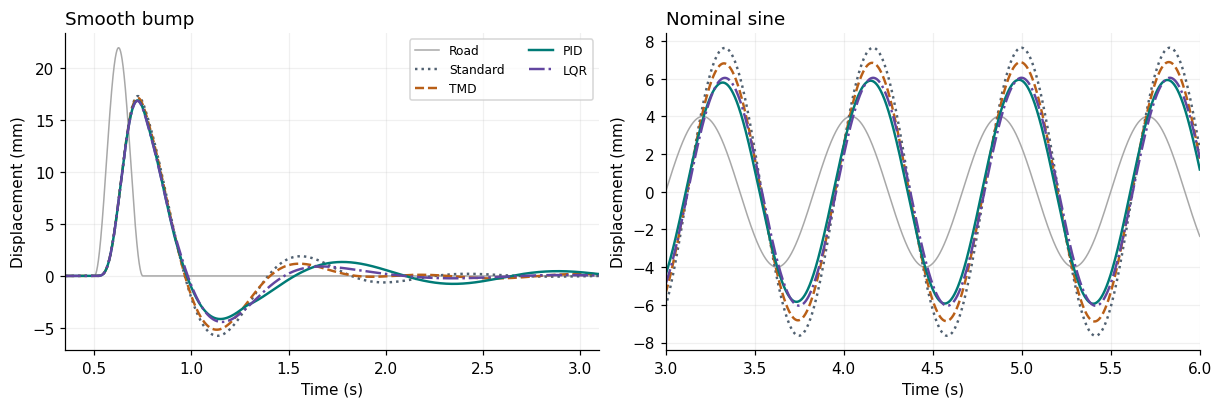

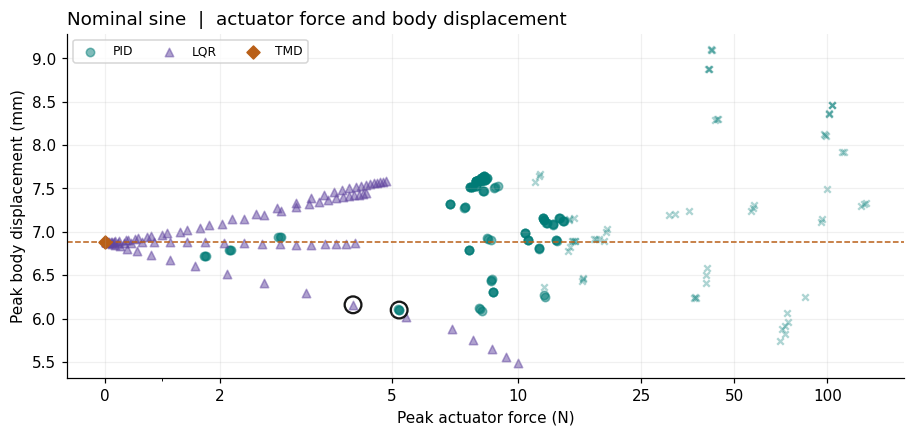

In [13]:
def compare_active_cases(results):
    pid = results[results.controller=="PID"].set_index("case")
    lqr = results[results.controller=="LQR"].set_index("case")
    compare = pd.DataFrame({"PID reduction (%)":pid.extra_pct, "LQR reduction (%)":lqr.extra_pct,
              "Difference (pp)":(pid.extra_pct-lqr.extra_pct).abs(),
              "RMS PID (N)":pid.rms_force_N,"RMS LQR (N)":lqr.rms_force_N,
              "PID peak force (N)":pid.peak_force_N,"LQR peak force (N)":lqr.peak_force_N})
    matched = (compare["Difference (pp)"]<=1.)&(pid.extra_pct>0)&(lqr.extra_pct>0)&pid.screen&lqr.screen
    compare["Lower RMS force at matched peak reduction"] = np.where(matched,np.where(
        np.isclose(pid.rms_force_N,lqr.rms_force_N,atol=.02),"Tie",
        np.where(pid.rms_force_N<lqr.rms_force_N,"PID","LQR")),"Unmatched or infeasible")
    return compare.rename_axis("Scenario").reset_index()
matched_results = compare_active_cases(results)
show_table(matched_results,2)

fig, axes = plt.subplots(1,2,figsize=(11,3.6))
for ax, name, xlim in zip(axes,["Smooth bump","Nominal sine"],[(.35,3.1),(3.,6.)]):
    group = traces_by_case[name]
    trace = group["Standard"]
    ax.plot(trace.time,1000*trace.road,color="#a8a8a8",lw=1,label="Road")
    for label,trace in group.items():
        ax.plot(trace.time,1000*trace.body,ls=styles[label],color=colors[label],lw=1.6,label=label)
    ax.set(xlabel="Time (s)",ylabel="Displacement (mm)",xlim=xlim,title=name)
axes[0].legend(ncol=2,fontsize=8)
plt.show()

# Peta kandidat pada satu uji buta. Titik tambahan hanya untuk menjelaskan
# trade-off, tidak dipakai untuk mengubah pasangan yang sudah terpilih.
trade_case = case_by_name["Nominal sine"]
reference_peak = results[(results.case==trade_case.name)&(results.controller=="TMD")].peak_mm.iloc[0]
trade_rows = []
for first in range(0,len(candidate_list),35):
    chunk = candidate_list[first:first+35]
    outcome = batch_metrics(trade_case,chunk)
    for candidate in chunk:
        m = outcome[candidate.label]
        trade_rows.append(dict(id=candidate.label,family=candidate.family,peak_mm=m["peak_mm"],
                               peak_force_N=m["peak_force_N"],valid=screened(m),contact=m["contact_events"]))
trade = pd.DataFrame(trade_rows)
fig, ax = plt.subplots(figsize=(8.2,3.85))
for family, marker in [("PID","o"),("LQR","^")]:
    pts = trade[(trade.family==family)&trade.valid&(trade.contact==0)]
    ax.scatter(pts.peak_force_N,pts.peak_mm,c=colors[family],marker=marker,alpha=.50,s=30,label=family)
    excluded = trade[(trade.family==family)&(~trade.valid|(trade.contact!=0))]
    ax.scatter(excluded.peak_force_N,excluded.peak_mm,marker="x",color=colors[family],alpha=.32,s=18)
for name in ["PID","LQR"]:
    point = results[(results.case==trade_case.name)&(results.controller==name)].iloc[0]
    ax.scatter(point.peak_force_N,point.peak_mm,s=120,facecolors="none",edgecolors="#171717",lw=1.5)
ax.axhline(reference_peak,ls="--",lw=1,color=colors["TMD"])
ax.scatter(0,reference_peak,color=colors["TMD"],marker="D",label="TMD")
ax.set_xscale("symlog",linthresh=6)
force_ticks = [0,2,5,10,25,50,100]
ax.set_xticks(force_ticks,labels=[str(value) for value in force_ticks])
ax.set(xlabel="Peak actuator force (N)",ylabel="Peak body displacement (mm)",
       title="Nominal sine  |  actuator force and body displacement")
ax.legend(ncol=3,fontsize=8)
plt.show()
print("Lingkaran hitam = pasangan yang dibekukan dari data tuning. Silang = kontak atau batas skrining terlewati.")

## 6 · Pemisahan pengaruh force limit dan end stops

Pada *high-amplitude sine*, skenario *unconstrained*, *force limit only*, *end stops only*, dan *both limits* memakai profil, massa, dan *gains* yang identik. Setiap *active peak* dibandingkan dengan TMD pasif yang memakai kondisi *end stops* yang sama. Kolom *peak stroke* memperlihatkan ruang yang diperlukan oleh masing-masing desain.

Uji berikutnya mengubah *bumper stiffness* atau *bumper damping* menjadi 0,5× dan 2× nominal satu per satu. Hasilnya menunjukkan apakah kesimpulan mengenai *body displacement* dan *peak contact force* bertahan terhadap perubahan karakteristik *bumper*.

In [14]:
stress_case = case_by_name["High-amplitude sine"]
constraint_rows = []
for description, use_stops, use_cap in [("Unconstrained",False,False),
    ("Force limit only",False,True),("End stops only",True,False),("Both limits",True,True)]:
    run = batch_metrics(stress_case,[passive,*active_controllers],stops=use_stops,force_limit=use_cap)
    for label,m in run.items():
        constraint_rows.append(dict(kondisi=description,controller=label,peak_mm=m["peak_mm"],
              extra_pct=100*(1-m["peak_mm"]/run["TMD"]["peak_mm"]),stroke_mm=m["stroke_mm"],
              peak_force_N=m["peak_force_N"],contact_events=m["contact_events"]))
ablation = pd.DataFrame(constraint_rows)
show_table(ablation.rename(columns=names_id),2)

contact_rows = []
for k_factor,c_factor in [(0.5,1.),(1.,.5),(1.,1.),(1.,2.),(2.,1.)]:
    altered = replace(hardware,stop_stiffness=hardware.stop_stiffness*k_factor,
                      stop_damping=hardware.stop_damping*c_factor)
    outcome = batch_metrics(stress_case,[passive,*active_controllers],limits=altered)
    for name,m in outcome.items():
        contact_rows.append(dict(k_factor=k_factor,c_factor=c_factor,controller=name,
            extra_pct=100*(1-m["peak_mm"]/outcome["TMD"]["peak_mm"]),peak_mm=m["peak_mm"],
            contact_peak_N=m["contact_peak_N"],compression_mm=m["compression_mm"],
            contact_events=m["contact_events"],screen=screened(m,altered)))
contact_sensitivity = pd.DataFrame(contact_rows)
show_table(contact_sensitivity.rename(columns=names_id),2)

Constraint case,System,Peak body displacement (mm),Additional peak reduction (%),Peak relative stroke (mm),Peak actuator force (N),Contact events
Unconstrained,TMD,51.62,0.00,140.22,0.00,0
Unconstrained,PID,45.73,11.41,274.82,38.46,0
Unconstrained,LQR,46.19,10.53,208.98,32.43,0
Force limit only,TMD,51.62,0.00,140.22,0.00,0
Force limit only,PID,45.73,11.41,274.82,38.46,0
Force limit only,LQR,46.19,10.53,208.98,32.43,0
End stops only,TMD,56.24,0.00,42.66,0.00,17
End stops only,PID,57.14,-1.60,44.47,48.30,32
End stops only,LQR,55.85,0.70,44.75,101.12,32
Both limits,TMD,56.24,0.00,42.66,0.00,17


Stiffness factor,Damping factor,System,Additional peak reduction (%),Peak body displacement (mm),Peak contact force (N),Peak bumper compression (mm),Contact events,Screen pass
0.50,1.00,TMD,0.00,56.05,478.44,3.38,17,True
0.50,1.00,PID,-1.05,56.64,784.84,5.66,32,True
0.50,1.00,LQR,1.32,55.31,838.49,6.10,32,True
1.00,0.50,TMD,0.00,56.42,636.06,3.06,17,True
1.00,0.50,PID,-1.93,57.51,1255.51,6.05,27,True
1.00,0.50,LQR,0.13,56.35,1069.24,5.15,32,True
1.00,1.00,TMD,0.00,56.24,627.77,2.66,17,True
1.00,1.00,PID,-1.60,57.14,1045.58,4.47,32,True
1.00,1.00,LQR,0.70,55.85,1108.34,4.75,32,True
1.00,2.00,TMD,0.00,55.97,841.33,2.16,17,True


### Numerical verification

Pada kasus kontak, ulangi dengan *integration step* 0,25 ms dengan *controller sample time* tetap. Sebagai pemeriksaan terpisah, integrasikan persamaan Newton kendaraan standar secara langsung dengan DOP853. Uji *force clipping* memakai *artificial force limit* ±2 N agar cabang *anti-windup* benar-benar dijalankan.

In [15]:
# Nilai puncak saat langkah integrasi dibagi dua. Periode kontrol tidak berubah.
refinement = batch_metrics(stress_case,[passive,*active_controllers],step=integration_step/2)
check_rows = []
for name, fine in refinement.items():
    base = results[(results.case==stress_case.name)&(results.controller==name)].iloc[0]
    check_rows.append({"System":name,"Δ body peak (mm)":fine["peak_mm"]-base.peak_mm,
                   "Δ stroke (mm)":fine["stroke_mm"]-base.stroke_mm,
                   "Δ peak contact force (%)":100*(fine["contact_peak_N"]/base.contact_peak_N-1)
                      if base.contact_peak_N>0 else np.nan,
                   "Contacts at nominal step":int(base.contact_events),"Contacts at half step":fine["contact_events"]})
checks = pd.DataFrame(check_rows)
show_table(checks,4)
# Validasi lintasan dua massa dari solver proyek terhadap integrator adaptif independen.
# Di sini persamaan Newton ditulis langsung untuk menangkap salah tanda saat merakit matriks.
bench_case = case_by_name["Smooth bump"]
bench_trace = traces_by_case[bench_case.name]["Standard"]
car = replace(vehicle,body_mass=vehicle.body_mass*bench_case.mass_factor)
def independent_rhs(t,state):
    body,wheel,body_v,wheel_v = state
    road = road_input(t,bench_case)
    support = car.suspension_stiffness*(body-wheel)+car.suspension_damping*(body_v-wheel_v)
    road_velocity = ((road_input(t+1e-6,bench_case)-road_input(t-1e-6,bench_case))/2e-6
                     if car.tire_damping else 0.)
    tire = car.tire_stiffness*(wheel-road)+car.tire_damping*(wheel_v-road_velocity)
    return [body_v,wheel_v,-support/car.body_mass,(support-tire)/car.wheel_mass]
independent = solve_ivp(independent_rhs,(0.,bench_case.duration_s),np.zeros(4),t_eval=bench_trace.time,
                        method="DOP853",rtol=1e-9,atol=1e-11,max_step=.0125)
assert independent.success
displacement_error_mm = 1000*np.max(np.abs(independent.y[0]-bench_trace.body))
mass,_,_,_,actuator_direction = mechanical_matrices(vehicle,tuned_absorber)
assert np.array_equal(actuator_direction,[1.,0.,-1.]) and actuator_direction.sum()==0.
assert displacement_error_mm < .01, "Periksa integrator atau tanda gaya."
assert (results.peak_force_N<=hardware.peak_force+1e-8).all()
assert np.allclose(results[results.controller=="TMD"].peak_force_N,0)
assert results.dropna(subset=["stroke_mm"]).shape[0]==3*len(evaluation)
assert np.isfinite(results[["peak_mm","rms_mm","peak_force_N"]]).all().all()
print(f"Selisih lintasan standar vs DOP853: {displacement_error_mm:.6f} mm maksimum.")
print("Tanda gaya internal, gaya pasif, batas clipping, jumlah kasus, dan hasil hingga: lolos.")

# Uji fungsi saturasi tersendiri. Rating 2 N di sini hanya untuk mengaktifkan cabang anti-windup.
test_drive = replace(hardware,peak_force=2.)
test_pid = design_pid("Cek saturasi",2500.,500.,180.,0.)
test_case = Scenario("Tes perangkat lunak","sine",.004,10.,12.,duration_s=3.)
test_trace = simulate(test_case,[test_pid],limits=test_drive)[test_pid.label]
test_metrics = metrics(test_trace,test_case,test_drive)
assert test_metrics["sat_pct"] > 0. and np.isclose(test_metrics["peak_force_N"],test_drive.peak_force)
print(f"Uji force clipping buatan ±2 N: {test_metrics['sat_pct']:.1f}% sampel mengalami clipping. "
      f"Gaya aktual tertinggi {test_metrics['peak_force_N']:.2f} N.")

Selisih lintasan standar vs DOP853: 0.000103 mm maksimum.
Tanda gaya internal, gaya pasif, batas clipping, jumlah kasus, dan hasil hingga: lolos.
Uji force clipping buatan ±2 N: 74.7% sampel mengalami clipping. Gaya aktual tertinggi 2.00 N.


System,Δ body peak (mm),Δ stroke (mm),Δ peak contact force (%),Contacts at nominal step,Contacts at half step
TMD,-0.0339,-0.0288,-1.1264,17,17
PID,-0.0774,-0.0839,-1.9416,32,32
LQR,-0.0922,-0.0172,-0.4240,32,32


## 7 · Manual tuning

Di Colab, ubah *sliders* lalu jalankan sel ini. Di Jupyter biasa, ubah angka pada baris awal. Bandingkan satu perubahan $K_d$ dengan *automatic tuning* pada kasus yang sama melalui *peak body displacement*, *force*, dan *stroke*. Kolom *nominal stability* menguji model linear. Sel ini tidak mengubah *controller gains* yang dipakai dalam §9–10.

System,Peak body displacement (mm),RMS body displacement (mm),Additional peak reduction (%),Peak actuator force (N),RMS actuator force (N),Peak relative stroke (mm),Contact events,Screen pass,Nominal linear stability
TMD,6.88,4.86,0.00,0.00,0.00,18.70,0,True,True
PID,6.10,4.19,11.41,5.13,3.51,36.64,0,True,True
LQR,6.16,4.28,10.53,4.32,3.02,27.86,0,True,True
PID manual,6.33,4.35,8.00,10.06,7.11,33.76,0,True,True
LQR manual,6.86,4.84,0.27,2.52,1.78,13.78,0,True,True


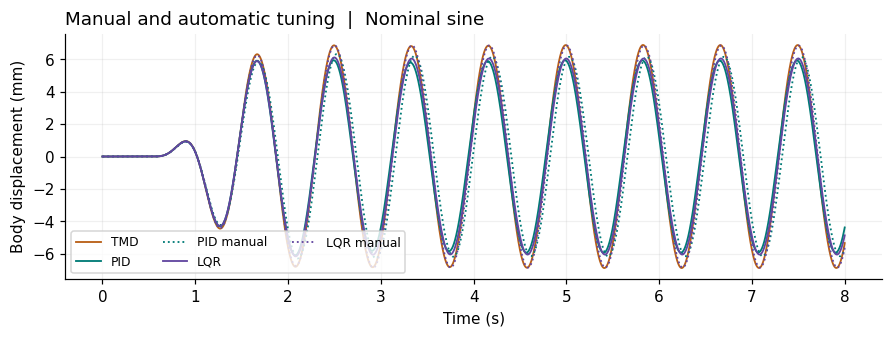

In [16]:
#@title Manual tuning — ubah parameter lalu jalankan sel
manual_proportional = 1500 #@param {type:"slider", min:0, max:15000, step:100}
manual_integral = 300 #@param {type:"slider", min:0, max:6000, step:50}
manual_derivative = 200 #@param {type:"slider", min:0, max:1600, step:10}
manual_stroke_mix = 0.2 #@param {type:"slider", min:0, max:1, step:0.05}
manual_lqr_force_scale = 50 #@param {type:"slider", min:2, max:250, step:1}
manual_lqr_stroke_weight = 0.15 #@param {type:"slider", min:0.01, max:3.01, step:0.01}
manual_case_name = "Nominal sine" #@param ["Smooth bump","Nominal sine","Sprung mass +25%","Sprung mass −20%","Low frequency","High frequency","High mass and frequency","High-amplitude sine","ARAN section"]

def manual_comparison(proportional,integral,derivative,mix,force_scale,stroke_weight,case_name):
    case = case_by_name[case_name]
    manual_controls = [design_pid("PID manual",proportional,integral,derivative,mix),
                       design_lqr("LQR manual",force_scale,stroke_weight)]
    experiment = simulate(case,[passive,*active_controllers,*manual_controls])
    base_peak = metrics(experiment["TMD"],case)["peak_mm"]
    rows = []
    for c in [passive,*active_controllers,*manual_controls]:
        m = metrics(experiment[c.label],case)
        rows.append(dict(controller=c.label,peak_mm=m["peak_mm"],rms_mm=m["rms_mm"],
                         extra_pct=100*(1-m["peak_mm"]/base_peak) if base_peak>1e-12 else np.nan,
                         peak_force_N=m["peak_force_N"],rms_force_N=m["rms_force_N"],stroke_mm=m["stroke_mm"],
                         contact_events=m["contact_events"],screen=screened(m),
                         nominal_linear_stability=stable_nominal(c)))
    show_table(pd.DataFrame(rows).rename(columns=names_id),2)
    fig,ax = plt.subplots(figsize=(8.0,2.95))
    for name in ["TMD","PID","PID manual","LQR","LQR manual"]:
        history = experiment[name]
        family = name.split()[0]
        ax.plot(history.time,1000*history.body,c=colors[family],lw=1.2,
                ls=":" if "manual" in name else "-",label=name)
    ax.set(xlabel="Time (s)",ylabel="Body displacement (mm)",title=f"Manual and automatic tuning  |  {case_name}")
    ax.legend(ncol=3,fontsize=8); plt.show()

manual_comparison(manual_proportional,manual_integral,manual_derivative,manual_stroke_mix,
                  manual_lqr_force_scale,manual_lqr_stroke_weight,manual_case_name)

## 8 · Animasi dengan skala dan waktu yang sama

Pilih *evaluation case* lalu jalankan sel. Keempat konfigurasi memakai waktu dan pembesaran vertikal yang sama. Kotak paling atas menunjukkan *absorber mass*. Warna jingga menunjukkan *end-stop contact*. Kurva bawah menampilkan *body displacement* aktual dalam mm relatif terhadap *static equilibrium*.

In [17]:
#@title Synchronized animation — pilih skenario lalu jalankan sel
animation_case_name = "Nominal sine" #@param ["Smooth bump","Nominal sine","Sprung mass +25%","Sprung mass −20%","Low frequency","High frequency","High mass and frequency","High-amplitude sine","ARAN section"]
def animate_comparison(case_name):
    from IPython.display import Video
    import matplotlib.ticker as ticker
    group = traces_by_case[case_name]
    first = group["Standard"]
    fps = 18
    end = min(6.,first.time[-1])
    frames = np.arange(round(end*fps)+1)/fps
    indices = np.searchsorted(first.time,frames).clip(0,len(first.time)-1)
    fig = plt.figure(figsize=(9.4,5.25),layout="none")
    fig.text(.075,.97,"ATMD  /  "+case_name,ha="left",va="top",fontsize=15,weight="bold")
    fig.text(.075,.895,"Vertical motion magnified 2× in all diagrams. The time history shows actual displacement.",fontsize=9)
    time_label = fig.text(.965,.965,"",ha="right",va="top",fontsize=10)
    gain = 2.
    base_levels = np.array([0.,70.,190.,340.]) # posisi gambar saat setimbang, mm skematik
    # Seluruh kolom berbagi batas yang sama, termasuk pada skenario amplitudo tinggi.
    diagram_positions = []
    for trace in group.values():
        signals = [trace.road, trace.wheel, trace.body]
        if trace.attached:
            signals.append(trace.absorber)
        diagram_positions.extend(level + gain*1000*series[indices] for level,series in zip(base_levels,signals))
    lower = min(-40., min(np.min(series) for series in diagram_positions)-32.)
    upper = max(380., max(np.max(series) for series in diagram_positions)+38.)
    panels = []
    for column,(name,tr) in enumerate(group.items()):
        left = .065 + column*.23
        ax = fig.add_axes([left,.445,.215,.315]); ax.axis("off")
        ax.set(xlim=(-.90,.90),ylim=(lower,upper))
        fig.text(left+.1075,.802,name,ha="center",color=colors[name],fontsize=11,weight="bold")
        ground, = ax.plot([],[],color="#926423",lw=3)
        wheel = Rectangle((-.25,0),.50,20,facecolor="#516171")
        body = Rectangle((-.60,0),1.20,30,facecolor=colors[name])
        ax.add_patch(wheel); ax.add_patch(body)
        absorber = Rectangle((-.27,0),.54,23,facecolor="#d8d2e9",edgecolor="#45336d")
        absorber.set_visible(tr.attached); ax.add_patch(absorber)
        tire, = ax.plot([],[],color="#737d86",lw=1.3)
        suspension, = ax.plot([],[],color="#496978",lw=1.5)
        damper, = ax.plot([],[],color="#654b86",lw=1.4)
        readout=ax.text(.5,-.01,"",transform=ax.transAxes,ha="center",va="top",fontsize=8)
        panels.append((tr,ground,wheel,body,absorber,tire,suspension,damper,readout))
    trace_ax = fig.add_axes([.085,.13,.875,.23])
    for name,tr in group.items():
        trace_ax.plot(first.time,tr.body*1000,color=colors[name],ls=styles[name],lw=1.25)
    trace_ax.set(xlim=(0,end),xlabel="Simulation time (s)",ylabel="Body (mm)")
    trace_ax.xaxis.set_major_locator(ticker.MaxNLocator(8))
    cursor = trace_ax.axvline(0,color="#273642",lw=1.)
    def update(frame):
        index = indices[frame]
        time_label.set_text(f"t = {first.time[index]:.2f} s")
        for tr,ground,wheel,body,absorber,tire,suspension,damper,readout in panels:
            offset = gain*1000*np.array([tr.road[index],tr.wheel[index],tr.body[index],
                                         tr.absorber[index] if tr.attached else 0.])
            road_y,wheel_y,body_y,damper_y = base_levels+offset
            ground.set_data([-.65,.65],[road_y,road_y]); wheel.set_y(wheel_y-10); body.set_y(body_y-15)
            tire.set_data([0,0],[road_y,wheel_y-10])
            suspension.set_data([0,.08,-.08,.08,-.08,0],np.linspace(wheel_y+10,body_y-15,6))
            caption=f"body {tr.body[index]*1000:+.1f} mm"
            if tr.attached:
                absorber.set_y(damper_y-11.5)
                damper.set_data([0,.075,-.075,.075,-.075,0],np.linspace(body_y+15,damper_y-11.5,6))
                absorber.set_facecolor("#ef9a68" if abs(tr.contact_force[index])>0 else "#d8d2e9")
            readout.set_text(caption)
        cursor.set_xdata([first.time[index]]*2)
    animation = FuncAnimation(fig,update,frames=len(frames),interval=1000/fps,blit=False)
    with tempfile.TemporaryDirectory() as temp:
        if shutil.which("ffmpeg"):
            output = Path(temp)/"atmd.mp4"
            animation.save(output,writer=FFMpegWriter(fps=fps,codec="libx264",
                extra_args=["-threads","1","-pix_fmt","yuv420p","-vf","pad=ceil(iw/2)*2:ceil(ih/2)*2"]))
            media = Video(data=output.read_bytes(),embed=True,mimetype="video/mp4",
                          html_attributes="controls playsinline loop muted")
        else:
            output = Path(temp)/"atmd.gif"
            animation.save(output,writer=PillowWriter(fps=fps))
            media = Image(data=output.read_bytes(),format="gif")
    plt.close(fig)
    display(media)
with plt.rc_context({"figure.constrained_layout.use":False, "figure.autolayout":False}):
    animate_comparison(animation_case_name)

## 9 · Laplace model dan Bode analysis

**Pertanyaan desain.** Jika permukaan jalan membentuk sinus yang sama, apa yang berubah pada amplitudo dan *phase* bodi sebelum dan sesudah *feedback* diaktifkan? Dua acuan digunakan. Kendaraan standar menunjukkan pengaruh penambahan *absorber*. TMD pasif dengan $u=0$ mengisolasi pengaruh pengaktifan motor pada *mechanical plant* yang sama.

Dengan *zero initial conditions*, gunakan $s=\sigma+j\omega$, lalu evaluasi $s=j2\pi f$ untuk membuat *Bode plot* [8]. Untuk kendaraan standar, tulis $D_s=k_s+c_s s$ dan $D_t=k_t+c_t s$. Eliminasi $Z_u$ dari dua persamaan Newton memberi

$$ H_{\mathrm{standard}}(s)=\frac{Z_s(s)}{Y(s)}
=\frac{D_sD_t}{(m_s s^2+D_s)(m_u s^2+D_s+D_t)-D_s^2}. $$

Untuk ketiga konfigurasi dengan *absorber*, persamaan *state-space* pada §1 memberi

$$ X=(sI-A)^{-1}\big[(b_y+s b_{\dot y})Y+b_u U\big]=G_y(s)Y+G_u(s)U. $$

$Y$ adalah *road displacement* dalam m. $b_y$ dan $b_{\dot y}$ mewakili *base excitation* melalui ban. $U$ adalah gaya motor dalam N, dengan arah positif pada bodi. Definisikan $U=-F(s)X$ dan $C_sX=Z_s$. Untuk TMD pasif, $F=0$. Untuk LQR, $F=K$. Untuk PID dengan *leaky integral*, $F(s)=g+K_i C_e/(s+\ell)$, dengan $C_eX=z_s-\beta r$ dan $gX=K_p C_eX+K_d\,d(C_eX)/dt$. *Back-calculation* tidak aktif dalam *small-signal regime* ini.

$$
L(s)=F(s)G_u(s),\qquad
\frac{U}{Y}=-\frac{F(s)G_y(s)}{1+L(s)},\qquad
H_b(s)=\frac{Z_s}{Y}=C_s\left[G_y+G_u\frac{U}{Y}\right].
$$

| Channel | Makna pada analisis |
|---|---|
| $Z_s/Y$ [m/m] | *Road-to-body transmissibility*. Bode sebelum dan sesudah *feedback* memakai pasangan input–output yang sama. |
| $(Z_a-Z_s)/Y$ [m/m] | *Relative stroke gain*. Kalikan dengan *road amplitude* untuk memperoleh *peak stroke*. |
| $U/Y$ [N/m] | *Actuator-force demand*. Tabel membagi hasil dengan 1.000 untuk menyajikan N/mm. |
| $L=F G_u$ [–] | *Actuator return ratio* pada titik pemutusan gaya motor. *Gain margin* dan *phase margin* dihitung dari channel ini [8]. |

*Bode magnitude* adalah $20\log_{10}|H_b|$ dalam dB relatif terhadap 1 m/m. *Phase* negatif menunjukkan bodi tertinggal dari jalan pada frekuensi yang diperiksa. Semua kurva berlaku di sekitar *static equilibrium*, selama *actuator* masih linear dan belum terjadi kontak. Nilai $H_b(0)=1$ diverifikasi dalam kode melalui *assertion*.

In [18]:
hardware_cases = [standard,passive,auto_pid,auto_lqr]
display_names = {standard.label:"Standard",passive.label:"Passive TMD","PID":"ATMD-PID","LQR":"ATMD-LQR"}
frequency_grid_hz = np.geomspace(.1,30.,1601)
nominal_sine = case_by_name["Nominal sine"]
nominal_excitation_hz = nominal_sine.speed_m_s/nominal_sine.length_m

def linear_description(control, car=vehicle):
    attached = control.family!=standard.family
    a,b = state_matrices(car,tuned_absorber if attached else None)
    gain = np.array(control.feedback) if attached else np.zeros(len(a))
    error_coordinate = np.zeros(len(a))
    if control.family=="PID":
        error_coordinate[[0,2]] = [1+control.stroke_mix,-control.stroke_mix]
    return a,b,gain,error_coordinate

def closed_matrices(control, sampled=False):
    a,b,gain,coordinate = linear_description(control)
    actuator = b[:,2]
    drift = a
    integrator_scale, integral_pole = 1.,-integral_leak_rate
    if sampled:
        drift,drive = discrete_plant(vehicle,tuned_absorber if control.family!=standard.family else None,
                                     control_period)
        actuator = drive[:,2]
        integrator_scale, integral_pole = control_period,1-control_period*integral_leak_rate
    closed = drift-np.outer(actuator,gain)
    if control.integral_gain:
        bottom = -integrator_scale*control.integral_gain*coordinate[None,:]
        closed = np.block([[closed,actuator[:,None]],[bottom,np.array([[integral_pole]])]])
    return closed

def frequency_channels(control, frequencies_hz, sampled=False):
    # Semua kurva memakai Y sebagai road displacement phasor. U adalah gaya pada bodi.
    s = 2j*np.pi*np.atleast_1d(frequencies_hz)
    a,b,gain,coordinate = linear_description(control)
    eye = np.eye(len(a))
    resolvent = s[:,None,None]*eye - a
    road_rhs = b[:,0] + s[:,None]*b[:,1]
    road_state = np.linalg.solve(resolvent,road_rhs[:,:,None])[:,:,0]
    drive = b[:,2]
    fb = np.broadcast_to(gain.astype(complex),(len(s),len(a))).copy()
    if sampled:
        phi,gamma = discrete_plant(vehicle,tuned_absorber if control.family!=standard.family else None,
                                   control_period)
        z = np.exp(s*control_period)
        resolvent = z[:,None,None]*eye - phi
        drive = gamma[:,2]
        integral_denominator = np.expm1(s*control_period)/control_period + integral_leak_rate
    else:
        integral_denominator = s+integral_leak_rate
    if control.integral_gain:
        fb += control.integral_gain*coordinate[None,:]/integral_denominator[:,None]
    drive_rhs = np.broadcast_to(drive,(len(s),len(drive)))
    force_state = np.linalg.solve(resolvent,drive_rhs[:,:,None])[:,:,0]
    return_ratio = np.sum(fb*force_state,axis=1)
    force_per_m = -np.sum(fb*road_state,axis=1)/(1+return_ratio)
    closed_state = road_state + force_state*force_per_m[:,None]
    attached = control.family!=standard.family
    return {"body":closed_state[:,0],"stroke":(closed_state[:,2]-closed_state[:,0]) if attached else None,
            "force":force_per_m,"loop":return_ratio}

def gain_db(channel):
    return 20*np.log10(np.maximum(np.abs(channel),1e-15))

def unwrapped_phase(channel):
    return np.rad2deg(np.unwrap(np.angle(channel)))

continuous_frf = {c.label:frequency_channels(c,frequency_grid_hz) for c in hardware_cases}
sampled_frf = {c.label:frequency_channels(c,frequency_grid_hz,sampled=True) for c in hardware_cases}
# Pembanding independen dari dua persamaan Newton, berlaku juga untuk tire damping nonzero.
s_grid = 2j*np.pi*frequency_grid_hz
ks_dyn = vehicle.suspension_stiffness + s_grid*vehicle.suspension_damping
kt_dyn = vehicle.tire_stiffness + s_grid*vehicle.tire_damping
standard_exact = ks_dyn*kt_dyn/((vehicle.body_mass*s_grid**2+ks_dyn)*
                (vehicle.wheel_mass*s_grid**2+ks_dyn+kt_dyn)-ks_dyn**2)
assert np.max(abs(standard_exact-continuous_frf[standard.label]["body"])) < 1e-8
for c in hardware_cases:
    assert abs(frequency_channels(c,[0.])["body"][0]-1)<1e-8
    assert np.max(np.real(np.linalg.eigvals(closed_matrices(c))))<0
    assert np.max(abs(np.linalg.eigvals(closed_matrices(c,True))))<1

### 9.1 · Perbandingan magnitude dan phase

Pita hijau menandai *body-bounce band* 0,55–2,50 Hz. Pita abu-abu menandai *wheel-hop band* 5–20 Hz. Garis vertikal menandai *nominal excitation frequency*. *Band edge* pada tabel berarti maksimum ditemukan di batas pita. Mode roda dapat terlihat lemah pada *body-displacement channel*.

Pada frekuensi mendekati nol, ketiga massa mengikuti perubahan tinggi jalan secara kuasistatis sehingga *body gain* mendekati 1 m/m (0 dB). Di sekitar *body-bounce mode*, *gain* dapat melampaui satu. Setelah melewati pita itu, gerak bodi pada model nominal makin terisolasi dari jalan. Karena itu, ukur pengaruh *controller* di sekitar puncak dan di kedua sisinya.

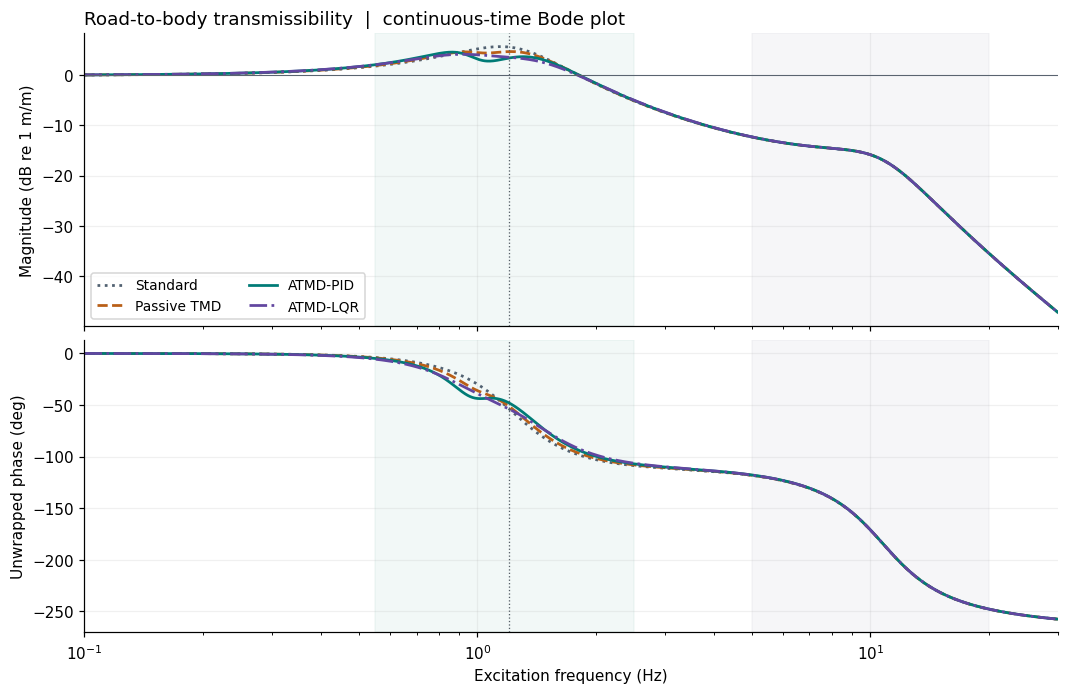

System,Band,Frequency (Hz),Max gain (m/m),Magnitude (dB),Location
Standard,Body-bounce band,1.144,1.928,5.700,Interior peak
Standard,Wheel-hop band,5.000,0.242,-12.325,Band edge
Passive TMD,Body-bounce band,1.219,1.721,4.715,Interior peak
Passive TMD,Wheel-hop band,5.000,0.242,-12.315,Band edge
ATMD-PID,Body-bounce band,0.861,1.699,4.606,Interior peak
ATMD-PID,Wheel-hop band,5.000,0.243,-12.296,Band edge
ATMD-LQR,Body-bounce band,0.919,1.616,4.171,Interior peak
ATMD-LQR,Wheel-hop band,5.000,0.243,-12.282,Band edge


System,f (Hz),Gain (m/m),Gain (dB),Phase (deg),Reduction vs TMD (%),Force gain (N/mm)
Standard,0.800,1.537,3.734,-13.700,2.976,0.000
Standard,1.200,1.911,5.624,-53.243,-11.132,0.000
Standard,1.600,1.284,2.171,-89.657,-0.604,0.000
Passive TMD,0.800,1.584,3.996,-16.400,0.000,0.000
Passive TMD,1.200,1.719,4.707,-50.959,0.000,0.000
Passive TMD,1.600,1.276,2.118,-87.076,0.000,0.000
ATMD-PID,0.800,1.651,4.356,-21.243,-4.232,1.347
ATMD-PID,1.200,1.481,3.408,-47.704,13.891,1.242
ATMD-PID,1.600,1.264,2.033,-82.983,0.978,1.100
ATMD-LQR,0.800,1.564,3.883,-20.866,1.292,1.100


In [19]:
fig,axes=plt.subplots(2,1,figsize=(9.6,6.2),sharex=True)
for c in hardware_cases:
    channel = continuous_frf[c.label]["body"]
    shared = dict(color=colors[c.label],ls=styles[c.label],lw=1.8,label=display_names[c.label])
    axes[0].semilogx(frequency_grid_hz,gain_db(channel),**shared)
    axes[1].semilogx(frequency_grid_hz,unwrapped_phase(channel),**shared)
for ax in axes:
    ax.axvspan(.55,2.5,color="#80bbb2",alpha=.10)
    ax.axvspan(5,20,color="#a4a5b7",alpha=.09)
    ax.axvline(nominal_excitation_hz,color="#555e66",ls=":",lw=.85)
axes[0].axhline(0,color="#5a6470",lw=.7)
axes[0].set(ylabel="Magnitude (dB re 1 m/m)",title="Road-to-body transmissibility  |  continuous-time Bode plot")
axes[1].set(ylabel="Unwrapped phase (deg)",xlabel="Excitation frequency (Hz)",xlim=(.1,30))
axes[0].legend(ncol=2,fontsize=9)
plt.show()

def strongest_in_band(control,lo,hi):
    grid = np.geomspace(lo,hi,301)
    amplitude = abs(frequency_channels(control,grid)["body"])
    idx = np.argmax(amplitude)
    if idx in (0,len(grid)-1):
        return grid[idx],amplitude[idx],True
    optimum = minimize_scalar(lambda f:-abs(frequency_channels(control,[f])["body"][0]),
                            bounds=(grid[idx-1],grid[idx+1]),method="bounded")
    return optimum.x,-optimum.fun,False

band_rows,point_rows=[],[]
for c in hardware_cases:
    for label,lo,hi in [("Body-bounce band",.55,2.5),("Wheel-hop band",5.,20.)]:
        at,peak,edge = strongest_in_band(c,lo,hi)
        band_rows.append({"System":display_names[c.label],"Band":label,"Frequency (Hz)":at,
                          "Max gain (m/m)":peak,"Magnitude (dB)":gain_db(peak),
                          "Location":"Band edge" if edge else "Interior peak"})
    for frequency in np.unique([.8,nominal_excitation_hz,1.6]):
        small = frequency_channels(c,[frequency])
        passive_body = frequency_channels(passive,[frequency])["body"][0]
        point_rows.append({"System":display_names[c.label],"f (Hz)":frequency,
           "Gain (m/m)":abs(small["body"][0]),"Gain (dB)":gain_db(small["body"][0]),
           "Phase (deg)":np.angle(small["body"][0],deg=True),
           "Reduction vs TMD (%)":100*(1-abs(small["body"][0]/passive_body)),
           "Force gain (N/mm)":abs(small["force"][0])/1000})
band_results = pd.DataFrame(band_rows)
frequency_results = pd.DataFrame(point_rows)
show_table(band_results,3)
show_table(frequency_results,3)

### 9.2 · Kapan pendekatan linear mencapai batas hardware?

Dengan *road amplitude* $A_r$, *steady-state stroke* yang diprediksi adalah $A_r|H_r|$ dan *peak actuator force* adalah $A_r|H_u|$. Tabel menghitung *road amplitude* saat masing-masing batas pertama kali tercapai pada *nominal excitation frequency*. Ambang *force cap* dihitung dengan model linear yang diteruskan secara hipotetis tanpa *end stops*. Setelah batas pertama tercapai, simulasi nonlinear pada §5–6 dan §10 menjadi dasar untuk menilai sistem. *Startup transient* juga dapat mengubah waktu kontak.

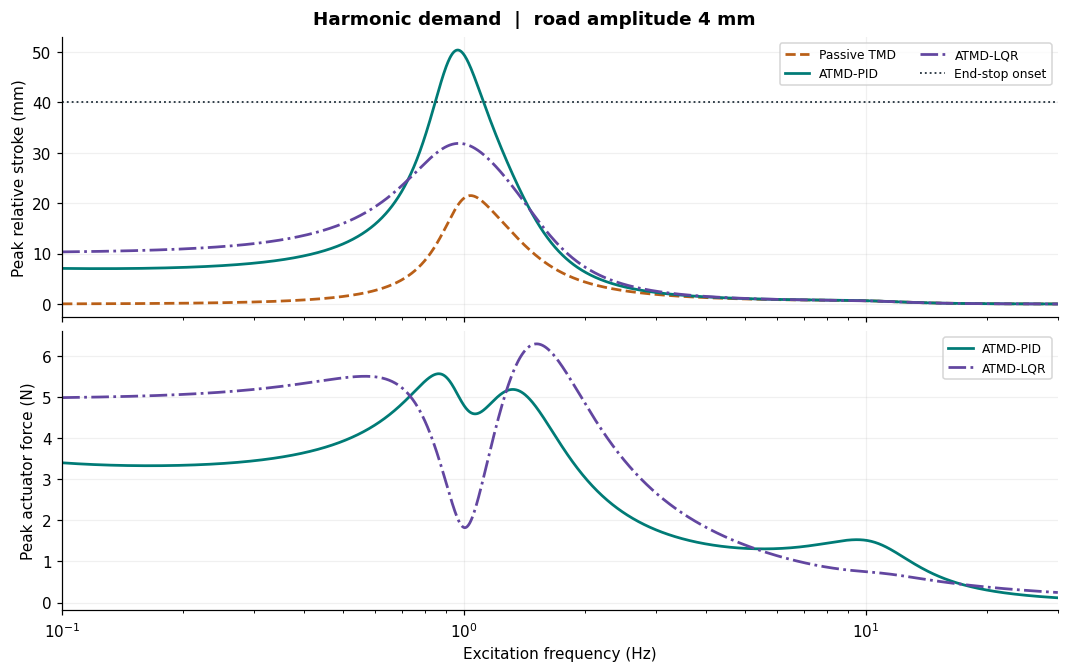

System,Stroke gain (m/m),Force gain (N/mm),First contact amplitude (mm),Force cap amplitude (mm)
Passive TMD,4.421,0.000,9.047,—
ATMD-PID,8.391,1.242,4.767,205.350
ATMD-LQR,6.817,1.065,5.867,239.334


In [20]:
fig,axes=plt.subplots(2,1,figsize=(9.6,6.0),sharex=True)
rated_amplitude_m = nominal_sine.amplitude_m
fig.suptitle(f"Harmonic demand  |  road amplitude {1000*rated_amplitude_m:g} mm",weight="bold")
for c in [passive,auto_pid,auto_lqr]:
    channels = continuous_frf[c.label]
    kwargs=dict(color=colors[c.label],ls=styles[c.label],lw=1.8,label=display_names[c.label])
    axes[0].semilogx(frequency_grid_hz,1000*rated_amplitude_m*abs(channels["stroke"]),**kwargs)
    if c.family in ("PID","LQR"):
        axes[1].semilogx(frequency_grid_hz,rated_amplitude_m*abs(channels["force"]),**kwargs)
axes[0].axhline(1000*hardware.stop_onset,ls=":",lw=1.2,color="#26343f",label="End-stop onset")
axes[0].set(ylabel="Peak relative stroke (mm)")
axes[1].set(ylabel="Peak actuator force (N)",xlabel="Excitation frequency (Hz)",xlim=(.1,30))
axes[0].legend(fontsize=8,ncol=2); axes[1].legend(fontsize=8)
plt.show()
demand_rows=[]
for c in [passive,auto_pid,auto_lqr]:
    channel = frequency_channels(c,[nominal_excitation_hz])
    stroke_gain,force_gain = abs(channel["stroke"][0]),abs(channel["force"][0])
    demand_rows.append({"System":display_names[c.label],"Stroke gain (m/m)":stroke_gain,
        "Force gain (N/mm)":force_gain/1000,"First contact amplitude (mm)":1000*hardware.stop_onset/stroke_gain,
        "Force cap amplitude (mm)":1000*hardware.peak_force/force_gain if force_gain>0 else np.nan})
demand_limits = pd.DataFrame(demand_rows)
show_table(demand_limits,3)

### 9.3 · Return ratio, stability, dan pengaruh sampling

Implementasi menahan gaya selama $T_s=2$ ms. Untuk *sampled return ratio*, gunakan $z=e^{j2\pi f T_s}$, $\Phi=e^{AT_s}$ dan $\Gamma_u=\int_0^{T_s}e^{A\tau}b_u\,d\tau$. *Actuator channel* yang disampel ialah $(zI-\Phi)^{-1}\Gamma_u$. Pada PID, *forward-Euler integral* mengganti $s+\ell$ dengan $(z-1)/T_s+\ell$. *Road excitation* tetap berupa sinus kontinu. *Road-to-body response* untuk perbandingan digital dievaluasi pada waktu sampling [8].

*Gain crossover* memenuhi $|L|=1$, sedangkan *phase crossover* terjadi ketika $L$ berada pada sumbu real negatif. Tabel memuat seluruh *crossings* yang terdeteksi pada **0,01–100 Hz**, di bawah *Nyquist frequency* 250 Hz. Tanda “—” berarti kolom tidak berlaku atau tidak ada *crossing* dari jenis itu dalam rentang yang diperiksa. *Phase margin* setiap *crossing* memakai sudut bertanda relatif terhadap −180° pada cabang terdekat. Pada beberapa *crossings*, satu nilai *phase margin* belum cukup untuk menilai stabilitas. Pemeriksaan langsung memakai $\max\Re(p)<0$ untuk *continuous poles* dan $\max|z_p|<1$ untuk *sampled poles*.

PID memiliki peak loop magnitude -13.25 dB, 0 gain crossover dalam pita uji, dan sampled spectral radius 0.99970.
LQR memiliki peak loop magnitude 4.73 dB, 2 gain crossover dalam pita uji, dan sampled spectral radius 0.99598.


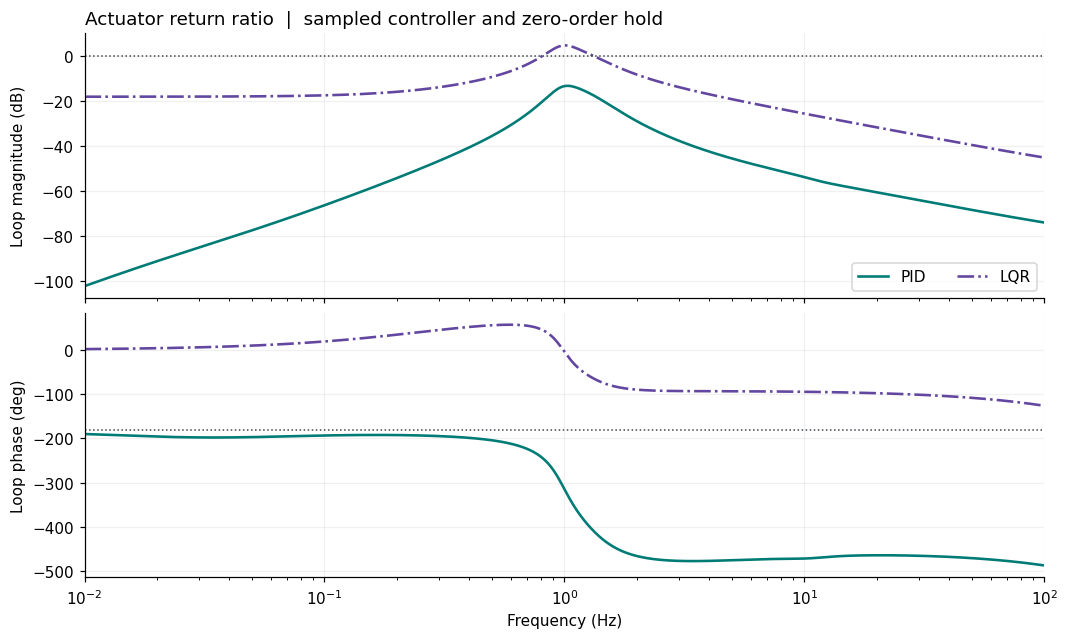

System,Dynamic order,Max Re(p) (1/s),Max |z| at 2 ms
Standard,4,-2.59007,0.99483
Passive TMD,6,-1.02987,0.99794
ATMD-PID,7,-0.15000,0.99970
ATMD-LQR,6,-2.00883,0.99598


Controller,Crossing,f (Hz),GM (dB),PM (deg)
PID,Gain crossover,—,—,—
PID,Phase crossover,—,—,—
LQR,Gain crossover,0.809,—,-134.498
LQR,Gain crossover,1.326,—,115.392
LQR,Phase crossover,—,—,—


In [21]:
loop_grid = np.geomspace(.01,100.,3001)
def roots_on_grid(values,grid,refine):
    changes = np.flatnonzero(np.signbit(values[1:])!=np.signbit(values[:-1]))
    roots=[brentq(refine,grid[i],grid[i+1]) for i in changes]
    return np.unique(np.r_[roots,grid[np.asarray(values)==0]]).tolist()

margin_rows, stability_rows=[],[]
fig,axs=plt.subplots(2,1,figsize=(9.6,5.7),sharex=True)
for control in hardware_cases:
    c_poles = np.linalg.eigvals(closed_matrices(control))
    d_poles = np.linalg.eigvals(closed_matrices(control,True))
    stability_rows.append({"System":display_names[control.label],"Dynamic order":len(c_poles),
            "Max Re(p) (1/s)":c_poles.real.max(),"Max |z| at 2 ms":max(abs(d_poles))})
    if control.family not in ("PID","LQR"):
        continue
    values = frequency_channels(control,loop_grid,True)["loop"]
    def loop_at(f):
        return frequency_channels(control,[f],True)["loop"][0]
    cross_gain = roots_on_grid(gain_db(values),loop_grid,lambda f:gain_db(loop_at(f)))
    cross_phase = [f for f in roots_on_grid(values.imag,loop_grid,lambda f:loop_at(f).imag)
                   if loop_at(f).real<0]
    for kind,crossings in [("Gain crossover",cross_gain),("Phase crossover",cross_phase)]:
        if not crossings:
            margin_rows.append({"Controller":control.label,"Crossing":kind,"f (Hz)":np.nan,
                                "GM (dB)":np.nan,"PM (deg)":np.nan})
        for f in crossings:
            value = loop_at(f)
            pm = np.remainder(np.angle(value,deg=True),360.)-180.
            margin_rows.append({"Controller":control.label,"Crossing":kind,"f (Hz)":f,
                 "GM (dB)":-gain_db(value) if kind=="Phase crossover" else np.nan,
                 "PM (deg)":pm if kind=="Gain crossover" else np.nan})
    style=dict(color=colors[control.label],ls=styles[control.label],label=control.label,lw=1.7)
    axs[0].semilogx(loop_grid,gain_db(values),**style)
    phase_curve=unwrapped_phase(values)
    # Ambil cabang yang berdekatan dengan -180° di puncak |L|. Semua margin memakai nilai kompleks.
    phase_curve-=360*round((phase_curve[np.argmax(abs(values))]+180)/360)
    axs[1].semilogx(loop_grid,phase_curve,**style)
axs[0].axhline(0,color="#404850",ls=":",lw=1)
axs[1].axhline(-180,color="#404850",ls=":",lw=1)
axs[0].set(title="Actuator return ratio  |  sampled controller and zero-order hold",ylabel="Loop magnitude (dB)")
axs[1].set(xlabel="Frequency (Hz)",ylabel="Loop phase (deg)",xlim=(loop_grid[0],loop_grid[-1]))
axs[0].legend(ncol=2); plt.show()
stability_table=pd.DataFrame(stability_rows)
margin_table=pd.DataFrame(margin_rows)
show_table(stability_table,5); show_table(margin_table,3)

for controller in (auto_pid,auto_lqr):
    loop_gain = gain_db(frequency_channels(controller,loop_grid,True)["loop"])
    cross_count = margin_table.loc[(margin_table.Controller==controller.label) &
                                   (margin_table.Crossing=="Gain crossover"),"f (Hz)"].notna().sum()
    spectral_radius = stability_table.loc[stability_table.System==display_names[controller.label],
                                         "Max |z| at 2 ms"].iloc[0]
    print(f"{controller.label} memiliki peak loop magnitude {loop_gain.max():.2f} dB, "
          f"{cross_count} gain crossover dalam pita uji, dan sampled spectral radius {spectral_radius:.5f}.")

### 9.4 · Rentang frekuensi yang mendapat manfaat dari active control

Kurva berikut membagi amplitudo setiap ATMD dengan amplitudo TMD pasif pada *road input* yang sama. Nilai −3 dB berarti rasio amplitudo sekitar 0,708. Batas interval di tabel diperoleh dari perpotongan 0 dB pada *body-bounce band*.

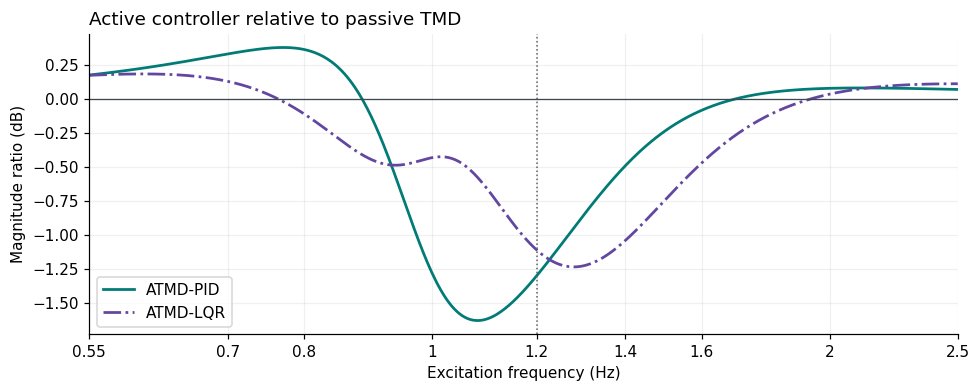

System,Lower edge (Hz),Upper edge (Hz)
ATMD-PID,0.885,1.700
ATMD-LQR,0.763,1.938



Di dalam *body-bounce band*, *peak gain* kendaraan standar adalah **1,928 m/m**.
TMD pasif menurunkannya menjadi **1,721 m/m**.
Dengan PID dan LQR, *peak gain* masing-masing **1,699** dan **1,616 m/m**. Setiap maksimum dapat terjadi pada frekuensi yang berbeda.

Pada **1,2 Hz**, *phase* bodi terhadap jalan adalah **-47,7°** untuk PID dan **-53,6°** untuk LQR. Nilai negatif menunjukkan bahwa gerak bodi tertinggal. Pada **0,8 Hz**, perubahan PID terhadap TMD bernilai **-4,23%** menurut definisi *additional peak reduction*. Pada grafik rasio, area di bawah 0 dB menunjukkan frekuensi ketika pengaktifan motor memperkecil amplitudo bodi. Tabel menyatakan interval tersebut di dalam 0,55–2,50 Hz.


In [22]:
point_view = frequency_results.set_index(["System","f (Hz)"])
peak_view = band_results.set_index(["System","Band"])
limit_view = demand_limits.set_index("System")
def indonesia(value,digits=2):
    return f"{value:.{digits}f}".replace(".",",")
def relative_gain_at(control,frequency):
    h_active = frequency_channels(control,[frequency])["body"][0]
    h_passive = frequency_channels(passive,[frequency])["body"][0]
    return gain_db(h_active/h_passive)

ratio_band = np.geomspace(.55,2.5,651)
fig, ax = plt.subplots(figsize=(8.8,3.45))
windows = []
for c in (auto_pid,auto_lqr):
    ratio_db = gain_db(frequency_channels(c,ratio_band)["body"]/frequency_channels(passive,ratio_band)["body"])
    ax.semilogx(ratio_band,ratio_db,color=colors[c.label],ls=styles[c.label],lw=1.8,label=display_names[c.label])
    crossings = roots_on_grid(ratio_db,ratio_band,lambda f:relative_gain_at(c,f))
    edges = np.unique([ratio_band[0],*crossings,ratio_band[-1]])
    for low,high in zip(edges[:-1],edges[1:]):
        if relative_gain_at(c,(low*high)**.5)<0:
            windows.append({"System":display_names[c.label],"Lower edge (Hz)":low,"Upper edge (Hz)":high})
ax.axhline(0,color="#3b4850",lw=.85)
ax.axvline(nominal_excitation_hz,color="#59636a",ls=":",lw=1.)
ax.set(title="Active controller relative to passive TMD",ylabel="Magnitude ratio (dB)",
       xlabel="Excitation frequency (Hz)",xlim=(.55,2.5))
ticks = [.55,.7,.8,1.,1.2,1.4,1.6,2.,2.5]
ax.set_xticks(ticks,labels=[f"{tick:g}" for tick in ticks])
ax.minorticks_off()
ax.legend()
plt.show()
improvement_windows = pd.DataFrame(windows,columns=["System","Lower edge (Hz)","Upper edge (Hz)"])
show_table(improvement_windows,3)
b = "Body-bounce band"
delta_pid = point_view.loc[("ATMD-PID",.8),"Reduction vs TMD (%)"]
nominal_pid = point_view.loc[("ATMD-PID",nominal_excitation_hz)]
nominal_lqr = point_view.loc[("ATMD-LQR",nominal_excitation_hz)]
display(Markdown(f"""
Di dalam *body-bounce band*, *peak gain* kendaraan standar adalah **{indonesia(peak_view.loc[('Standard',b),'Max gain (m/m)'],3)} m/m**.
TMD pasif menurunkannya menjadi **{indonesia(peak_view.loc[('Passive TMD',b),'Max gain (m/m)'],3)} m/m**.
Dengan PID dan LQR, *peak gain* masing-masing **{indonesia(peak_view.loc[('ATMD-PID',b),'Max gain (m/m)'],3)}** dan **{indonesia(peak_view.loc[('ATMD-LQR',b),'Max gain (m/m)'],3)} m/m**. Setiap maksimum dapat terjadi pada frekuensi yang berbeda.

Pada **{indonesia(nominal_excitation_hz,1)} Hz**, *phase* bodi terhadap jalan adalah **{indonesia(nominal_pid['Phase (deg)'],1)}°** untuk PID dan **{indonesia(nominal_lqr['Phase (deg)'],1)}°** untuk LQR. Nilai negatif menunjukkan bahwa gerak bodi tertinggal. Pada **0,8 Hz**, perubahan PID terhadap TMD bernilai **{indonesia(delta_pid)}%** menurut definisi *additional peak reduction*. Pada grafik rasio, area di bawah 0 dB menunjukkan frekuensi ketika pengaktifan motor memperkecil amplitudo bodi. Tabel menyatakan interval tersebut di dalam 0,55–2,50 Hz.
"""))

### 9.5 · Cross-check dengan time-domain simulation

Masukkan sinus dengan *road amplitude* 0,3 mm agar tetap di daerah linear. Pada 0,8 Hz, frekuensi nominal, 1,6 Hz, dan *undamped wheel-mode frequency*, cocokkan sinus serta kosinus terhadap enam periode terakhir. Rasio *fitted body phasor* dan *road phasor* memberi *gain* dan *phase* yang dapat diperiksa secara independen. Dua kolom pertama membandingkan *fit* dengan *sampled model*. Dua berikutnya mengukur perbedaan antara *sampled model* dan *Laplace model*. Batas lulus untuk *fit* adalah 0,05 dB dan 0,5°. Kode juga memeriksa bahwa tidak ada *force clipping* maupun *contact*.

In [23]:
def fitted_phasor(values, times, frequency):
    angle = 2*np.pi*frequency*times
    basis = np.column_stack((np.sin(angle),np.cos(angle),np.ones(len(times))))
    sine,cosine,_ = np.linalg.lstsq(basis,values,rcond=None)[0]
    return sine+1j*cosine

frequency_check_rows = []
for frequency in np.unique([.8,nominal_excitation_hz,1.6,modes_hz(vehicle)[1]]):
    test = Scenario("Small-signal check","sine",.0003,10.,10.*frequency,duration_s=max(20.,14/frequency))
    verification_traces = simulate(test,[standard])
    verification_traces.update(simulate(test,[passive,auto_pid,auto_lqr]))
    for control in hardware_cases:
        trace = verification_traces[control.label]
        sample_stride = round(control_period/integration_step)
        indices = np.arange(0,len(trace.time),sample_stride)
        indices = indices[trace.time[indices]>=trace.time[-1]-6/frequency]
        measured = (fitted_phasor(trace.body[indices],trace.time[indices],frequency)/
                    fitted_phasor(trace.road[indices],trace.time[indices],frequency))
        analogue = frequency_channels(control,[frequency])["body"][0]
        digital = frequency_channels(control,[frequency],True)["body"][0]
        assert abs(trace.contact_force).max()==0 and np.allclose(trace.force,trace.request)
        frequency_check_rows.append({"System":display_names[control.label],"f (Hz)":frequency,
            "Fit minus sampled (dB)":gain_db(measured/digital),
            "Fit minus sampled (deg)":np.angle(measured/digital,deg=True),
            "Sampled minus Laplace (dB)":gain_db(digital/analogue),
            "Sampled minus Laplace (deg)":np.angle(digital/analogue,deg=True)})
frequency_checks = pd.DataFrame(frequency_check_rows)
show_table(frequency_checks,4)
max_fit_db = frequency_checks["Fit minus sampled (dB)"].abs().max()
max_fit_deg = frequency_checks["Fit minus sampled (deg)"].abs().max()
assert max_fit_db<.05 and max_fit_deg<.5, "Periksa settling, time grid, atau state feedback."
print(f"Maximum fit residual pada empat check frequencies: {max_fit_db:.4f} dB, {max_fit_deg:.4f}°.")

Maximum fit residual pada empat check frequencies: 0.0017 dB, 0.0000°.


System,f (Hz),Fit minus sampled (dB),Fit minus sampled (deg),Sampled minus Laplace (dB),Sampled minus Laplace (deg)
Standard,0.8000,-0.0000,0.0000,0.0000,0.0000
Passive TMD,0.8000,-0.0000,0.0000,0.0000,0.0000
ATMD-PID,0.8000,-0.0000,-0.0000,-0.0039,-0.0104
ATMD-LQR,0.8000,-0.0000,-0.0000,-0.0017,0.0064
Standard,1.2000,-0.0000,0.0000,0.0000,-0.0000
Passive TMD,1.2000,-0.0000,-0.0000,0.0000,-0.0000
ATMD-PID,1.2000,-0.0000,0.0000,0.0034,0.0600
ATMD-LQR,1.2000,-0.0000,0.0000,-0.0035,0.0199
Standard,1.6000,-0.0000,0.0000,0.0000,-0.0000
Passive TMD,1.6000,-0.0000,0.0000,0.0000,-0.0000


## 10 · Monte Carlo dan global sensitivity analysis

**Apa yang dimaksud dengan “input”?** Pada *plant*, $y(t)$ adalah *disturbance input* dan $u(t)$ adalah *control input* dari PID atau LQR. Pada *Monte Carlo experiment*, satu baris data memberi **tujuh uncertain factors**. Dua faktor membentuk $y(t)$. Lima lainnya mengubah parameter fisik. *Actuator force* dihitung oleh *feedback controller* sebagai respons terhadap setiap realisasi. Mengacak $u(t)$ secara independen akan mengubah pertanyaan riset.

| Kategori | Variabel dan perannya |
|---|---|
| *Road excitation* | *Road amplitude* dan *excitation frequency*. Untuk $\lambda=10$ m, $f=0{,}75$–$1{,}75$ Hz setara dengan $v=7{,}5$–$17{,}5$ m/s. Kecepatan diturunkan dari frekuensi agar satu pengaruh tidak dihitung dua kali. |
| *Vehicle parameters* | *Sprung mass*, *suspension stiffness*, dan *suspension damping* mengubah karakteristik dinamis kendaraan. |
| *ATMD parameters* | *Absorber mass* dan *end-stop clearance* mengubah massa bergerak serta ruang geraknya. |
| *Outputs of interest* | *Peak body displacement* (mm), *additional peak reduction* terhadap TMD pada sampel yang sama (%), dan *RMS actuator force* (N). |

Setiap faktor diasumsikan **independent uniform** pada rentang di bawah. Rentang ini adalah pilihan desain eksperimen. Pada kendaraan nyata, sebagian faktor dapat berkorelasi dan distribusinya memerlukan data pengukuran. Semua realisasi menggunakan *gains* hasil §4 tanpa *retuning*. TMD, PID, dan LQR menerima sampel yang sama. Kendaraan standar sudah diuji di §9. TMD menjadi acuan berpasangan agar perbedaan pada §10 berasal dari pengaktifan motor.

In [24]:
# Rentang independen adalah asumsi eksperimen di sekitar nominal. Satuan internal mengikuti nama kolom.
factor_spec = pd.DataFrame([
    ("amplitude_mm","Road amplitude","Road excitation","mm",2.,20.),
    ("frequency_hz","Excitation frequency","Road excitation","Hz",.75,1.75),
    ("body_kg","Sprung mass","Vehicle parameter","kg",.80*vehicle.body_mass,1.25*vehicle.body_mass),
    ("spring_N_m","Suspension stiffness","Vehicle parameter","N/m",.85*vehicle.suspension_stiffness,1.15*vehicle.suspension_stiffness),
    ("damping_Ns_m","Suspension damping","Vehicle parameter","N·s/m",.75*vehicle.suspension_damping,1.25*vehicle.suspension_damping),
    ("absorber_kg","Absorber mass","ATMD parameter","kg",.90*vehicle.absorber_mass,1.10*vehicle.absorber_mass),
    ("clearance_mm","End-stop clearance","ATMD parameter","mm",.875*1000*hardware.stop_onset,1.025*1000*hardware.stop_onset),
], columns=["key","Factor","Role","Unit","Low","High"]).set_index("key")
monte_carlo_seed = 20261121
base_sample_size = 1024
sample_batch_size = 128
mc_duration_s, mc_onset_s, mc_wavelength_m = 8., .5, 10.
bootstrap_count = 400
show_table(factor_spec.reset_index(drop=True),2)

def physical_factors(unit_samples):
    low = factor_spec["Low"].to_numpy()
    high = factor_spec["High"].to_numpy()
    return pd.DataFrame(low + np.asarray(unit_samples)*(high-low),columns=factor_spec.index)

def vehicle_from_factors(inputs):
    return replace(vehicle,body_mass=inputs.body_kg,suspension_stiffness=inputs.spring_N_m,
                   suspension_damping=inputs.damping_Ns_m,absorber_mass=inputs.absorber_kg)

Factor,Role,Unit,Low,High
Road amplitude,Road excitation,mm,2.00,20.00
Excitation frequency,Road excitation,Hz,0.75,1.75
Sprung mass,Vehicle parameter,kg,240.00,375.00
Suspension stiffness,Vehicle parameter,N/m,16141.50,21838.50
Suspension damping,Vehicle parameter,N·s/m,1350.00,2250.00
Absorber mass,ATMD parameter,kg,10.80,13.20
End-stop clearance,ATMD parameter,mm,35.00,41.00


### 10.1 · Nonlinear batch simulation

Setiap realisasi mulai dari *static equilibrium*. *Road input* dimulai pada 0,5 s, naik selama satu periode, lalu diteruskan hingga 8 s. *Peak displacement* mencakup seluruh rekaman. *RMS actuator force* memakai tiga periode terakhir. *Force clipping*, *anti-windup*, dan *compliant end stops* tetap aktif. *Batch solver* memakai *time step* dan persamaan fisik yang sama dengan §4. Tiga *cross-check cases* di bawah membandingkan sembilan lintasan dengan *time-history solver*, termasuk satu kasus 30 mm yang menyentuh *end stops*.

In [25]:
# Menghitung semua controller untuk satu realisasi. Output disimpan sebagai running statistics.
def simulate_uncertain_batch(factors, controllers=None):
    if not len(factors):
        raise ValueError("Sampel Monte Carlo kosong.")
    limits = hardware
    if controllers is None:
        controllers = [passive,auto_pid,auto_lqr]
    step = integration_step
    stride = round(control_period/step)
    if stride<1 or not np.isclose(stride*step,control_period):
        raise ValueError("Control period harus kelipatan integration step.")
    sample_count, configuration_count = len(factors),len(controllers)
    configurations = [control.label for control in controllers]
    models = [discrete_plant(vehicle_from_factors(row),tuned_absorber,step)
              for row in factors.itertuples()]
    transitions = np.ascontiguousarray(np.array([pair[0].T for pair in models]))
    inputs = np.array([pair[1] for pair in models])
    force_input = inputs[:,None,:,2]
    clearance = factors.clearance_mm.to_numpy()[:,None]/1000
    if np.any((clearance<=0) | (clearance>=limits.half_travel)):
        raise ValueError("End-stop clearance harus berada di dalam usable half-stroke.")
    amplitude = factors.amplitude_mm.to_numpy()/1000
    frequency = factors.frequency_hz.to_numpy()
    time = np.arange(round(mc_duration_s/step)+1)*step
    elapsed = time[:,None]-mc_onset_s
    road = sinusoidal_profile(elapsed*frequency,amplitude)
    # Waktu RMS disamakan persis dengan simulator time-history, termasuk pembulatan grid.
    first_rms = np.searchsorted(time,np.maximum(mc_onset_s+1/frequency,time[-1]-3/frequency)-1e-10)
    first_duty = np.searchsorted(time,mc_onset_s-1e-10)
    if np.any(first_rms>=len(time)-1):
        raise ValueError("Rekaman terlalu pendek untuk RMS window.")
    static_weight = 9.80665*(factors.body_kg.to_numpy()+vehicle.wheel_mass+factors.absorber_kg.to_numpy())
    feedback = np.array([c.feedback for c in controllers])
    integral_gains = np.array([c.integral_gain for c in controllers])
    stroke_mix = np.array([c.stroke_mix for c in controllers])
    shape = (sample_count,configuration_count)
    state = np.zeros((*shape,6))
    peak_body = np.zeros(shape); peak_travel = np.zeros(shape); peak_speed = np.zeros(shape)
    peak_force = np.zeros(shape); sum_rms = np.zeros(shape); sum_duty = np.zeros(shape)
    integral = np.zeros(shape); force = np.zeros(shape); previous_squared_force = np.zeros(shape)
    normal_min = np.full(shape,np.inf); ever_saturated = np.zeros(shape,dtype=bool)
    for index in range(len(time)):
        body = state[:,:,0]
        travel = state[:,:,2]-body
        relative_velocity = state[:,:,5]-state[:,:,3]
        if index % stride == 0:
            request = -np.einsum("nci,ci->nc",state,feedback)+integral
            force = np.clip(request,-limits.peak_force,limits.peak_force)
            error = -body+stroke_mix*travel
            integral = update_integral_force(integral,error,integral_gains,force,request)
            ever_saturated |= np.abs(force-request)>1e-7
            peak_force = np.maximum(peak_force,np.abs(force))
        peak_body = np.maximum(peak_body,np.abs(body))
        peak_travel = np.maximum(peak_travel,np.abs(travel))
        peak_speed = np.maximum(peak_speed,np.abs(relative_velocity))
        # Central difference pada road velocity, setara dengan perhitungan normal load pada time history.
        road_level = road[index,:,None]
        normal = static_weight[:,None]+vehicle.tire_stiffness*(road_level-state[:,:,1])
        if vehicle.tire_damping:
            lo,hi = max(0,index-1),min(len(time)-1,index+1)
            road_velocity = (road[hi]-road[lo])/((hi-lo)*step)
            normal += vehicle.tire_damping*(road_velocity[:,None]-state[:,:,4])
        normal_min = np.minimum(normal_min,normal)
        squared_force = force*force
        interval_power = .5*(previous_squared_force+squared_force)
        if index>first_duty:
            sum_duty += interval_power
        sum_rms += (index>first_rms)[:,None]*interval_power
        previous_squared_force = squared_force
        if index+1==len(time):
            break
        contact = end_stop_force(travel,relative_velocity,clearance,limits)
        road_effect = (.5*(road[index]+road[index+1]))[:,None]*inputs[:,:,0]
        if vehicle.tire_damping:
            road_effect += ((road[index+1]-road[index])/step)[:,None]*inputs[:,:,1]
        state = state@transitions+road_effect[:,None,:]+(force+contact)[:,:,None]*force_input
    rms_force = np.sqrt(step*sum_rms/(time[-1]-time[first_rms])[:,None])
    duty_rms = np.sqrt(step*sum_duty/(time[-1]-time[first_duty]))
    feasible = ((peak_travel<=limits.half_travel) & (normal_min>=0) & (peak_speed<=limits.speed_reference)
                & (np.maximum(rms_force,duty_rms)<=limits.continuous_force+1e-7))
    records = {}
    for column,name in enumerate(configurations):
        values = {"peak_mm":1000*peak_body[:,column], "force_rms_N":rms_force[:,column],
                  "extra_pct":100*(1-peak_body[:,column]/peak_body[:,0]),
                  "stroke_mm":1000*peak_travel[:,column], "peak_force_N":peak_force[:,column],
                  "contact":peak_travel[:,column]>clearance[:,0], "clipped":ever_saturated[:,column],
                  "screen":feasible[:,column]}
        for metric, column_values in values.items():
            records[(name,metric)]=column_values
    return pd.DataFrame(records,index=factors.index)

In [26]:
# Cross-check dengan simulator time-history asli. Pakai dua titik uji di dalam rentang dan satu nominal beramplitudo besar.
check_factors = physical_factors(np.array([[.05,.20,.70,.80,.10,.25,.80],[.85,.55,.20,.25,.60,.75,.30]]))
check_factors.loc[len(check_factors)] = [30.,nominal_excitation_hz,vehicle.body_mass,vehicle.suspension_stiffness,
                                        vehicle.suspension_damping,vehicle.absorber_mass,1000*hardware.stop_onset]
batch_check = simulate_uncertain_batch(check_factors)
cross_rows=[]
for ix,values in enumerate(check_factors.itertuples()):
    car_check = vehicle_from_factors(values)
    setup = replace(hardware,stop_onset=values.clearance_mm/1000)
    test = Scenario("MC check","sine",values.amplitude_mm/1000,mc_wavelength_m,
                    mc_wavelength_m*values.frequency_hz,duration_s=mc_duration_s,onset_s=mc_onset_s)
    measured = batch_metrics(test,[passive,auto_pid,auto_lqr],limits=setup,model_vehicle=car_check)
    for name,m in measured.items():
        batch = batch_check[name].iloc[ix]
        assert bool(batch.contact)==bool(m["contact_events"])
        assert bool(batch.screen)==screened(m,setup)
        cross_rows.append({"Case":ix+1,"System":name,"Δ peak (mm)":batch.peak_mm-m["peak_mm"],
             "Δ RMS force (N)":batch.force_rms_N-m["rms_force_N"],"Δ stroke (mm)":batch.stroke_mm-m["stroke_mm"]})
mc_checks = pd.DataFrame(cross_rows)
cross_error=mc_checks.iloc[:,2:].abs().max()
assert np.max(cross_error.to_numpy())<1e-5, "Periksa sampled inputs, force law, atau RMS window."
print(f"Batch vs time-history (9 trajectories): worst peak error {cross_error.iloc[0]:.2e} mm, "
      f"RMS force error {cross_error.iloc[1]:.2e} N, stroke error {cross_error.iloc[2]:.2e} mm.")

Batch vs time-history (9 trajectories): worst peak error 6.18e-13 mm, RMS force error 1.56e-13 N, stroke error 1.16e-12 mm.


### 10.2 · Sampling design dan operating envelope

Dua matriks acak independen $A,B$ masing-masing memiliki $N$ baris. Untuk faktor $i$, matriks $A_B^{(i)}$ menyalin $A$ dan mengganti kolom $i$ dengan kolom $B$ [9], [10]. Tujuh faktor memerlukan $N(7+2)$ kombinasi. Setiap kombinasi dijalankan untuk TMD, PID, dan LQR. Tabel distribusi dan persentase kasus menggunakan **hanya baris independen $A+B$**. Seluruh *hybrid samples* ikut digunakan untuk *sensitivity indices*.

*Any contact* berarti pernah menyentuh *bumper* selama rekaman. *Screen failure* berarti melanggar sedikitnya satu batas pada §4. Dua kejadian ini dapat berbeda karena masih ada ruang kompresi setelah *first contact*. Seluruh sampel tetap masuk estimasi. Jika rentang baru menghasilkan *screen failures*, peringkat mencakup respons di luar batas perangkat.

In [27]:
def run_monte_carlo(base_size, seed):
    if base_size<32:
        raise ValueError("Gunakan sekurangnya 32 base rows untuk menghitung estimasi.")
    generator = np.random.default_rng(seed)
    dimension = len(factor_spec)
    a = generator.random((base_size,dimension))
    b = generator.random((base_size,dimension))
    blocks = {"A":a, "B":b}
    for column,factor in enumerate(factor_spec.index):
        hybrid = a.copy()
        hybrid[:,column] = b[:,column]
        blocks[factor] = hybrid
    factors_all, outputs_all = {},{}
    for label,block in blocks.items():
        factors = physical_factors(block)
        factors_all[label] = factors
        parts = [simulate_uncertain_batch(factors.iloc[start:start+sample_batch_size])
                 for start in range(0,len(factors),sample_batch_size)]
        outputs_all[label] = pd.concat(parts)
    return factors_all,outputs_all

try:
    from threadpoolctl import threadpool_limits
    blas_context = threadpool_limits(limits=1,user_api="blas")
except ImportError:
    from contextlib import nullcontext
    blas_context = nullcontext()
with blas_context:
    mc_factors, mc_outputs = run_monte_carlo(base_sample_size,monte_carlo_seed)
# A dan B merupakan independent samples. Hybrid rows hanya digunakan untuk sensitivity indices.
mc_population = pd.concat([mc_outputs["A"],mc_outputs["B"]],ignore_index=True)
assert len(mc_population)==2*base_sample_size
assert all(np.isfinite(block.to_numpy(dtype=float)).all() for block in mc_outputs.values())
case_total = len(mc_outputs)*base_sample_size
print(f"{len(factor_spec)} factors, N = {base_sample_size:,}, seed = {monte_carlo_seed}. "
      f"{case_total:,} parameter sets × 3 configurations = {3*case_total:,} simulations.")
risk_rows = []
for name in ("TMD","PID","LQR"):
    sample = mc_population[name]
    risk_rows.append({"System":name,"Median peak (mm)":sample.peak_mm.median(),
        "P95 peak (mm)":sample.peak_mm.quantile(.95),"Median RMS force (N)":sample.force_rms_N.median(),
        "Any contact (%)":100*sample.contact.mean(),"Force saturation (%)":100*sample.clipped.mean(),
        "Screen failures (A+B)":int((~sample.screen).sum()),
        "Peak below TMD (%)":100*(sample.extra_pct>0).mean() if name!="TMD" else np.nan})
risk_summary = pd.DataFrame(risk_rows)
show_table(risk_summary,2)
all_screen_failures = {name:int(sum((~block[name]["screen"]).sum() for block in mc_outputs.values()))
                       for name in ("TMD","PID","LQR")}
print("Hardware screen failures pada seluruh design (termasuk hybrid):",all_screen_failures)

7 factors, N = 1,024, seed = 20261121. 9,216 parameter sets × 3 configurations = 27,648 simulations.
Hardware screen failures pada seluruh design (termasuk hybrid): {'TMD': 0, 'PID': 0, 'LQR': 0}


System,Median peak (mm),P95 peak (mm),Median RMS force (N),Any contact (%),Force saturation (%),Screen failures (A+B),Peak below TMD (%)
TMD,17.20,34.12,0.00,48.88,0.00,0,—
PID,16.71,34.28,9.63,81.54,0.00,0,62.74
LQR,16.37,33.30,12.07,75.24,0.00,0,90.92


### 10.3 · Sensitivity indices dan ketidakpastian estimasi

Untuk satu *output* $q$ dengan variansi $V$, *Jansen estimators* [9], [10] yang digunakan adalah

$$
S_i=1-\frac{\mathbb{E}[(q(B)-q(A_B^{(i)}))^2]}{2V},\qquad
S_{T_i}=\frac{\mathbb{E}[(q(A)-q(A_B^{(i)}))^2]}{2V}.
$$

$S_i$ menunjukkan bagian variasi akibat faktor $i$ sendiri. $S_{T_i}$ juga mencakup interaksi faktor tersebut dengan faktor lain. Nilai $S_{T_i}$ yang besar menunjukkan faktor penting dalam rentang yang diuji. Jumlah seluruh $S_{T_i}$ dapat melampaui satu karena interaksi dapat terhitung pada beberapa faktor.

Tabel menyajikan peringkat teratas dan *95% percentile bootstrap intervals* untuk $S_{T_i}$. Pada setiap *resample*, indeks baris $A$, $B$, dan seluruh *hybrids* dipilih bersama. Kolom $N/2$ memeriksa perubahan estimasi ketika ukuran sampel dibagi dua. Estimasi dan interval dibiarkan dalam nilai aslinya sehingga *sampling error* yang melampaui batas teoritis 0–1 tetap terlihat. Ketidakpastian asumsi fisik berada di luar *bootstrap interval*. Nilai semua faktor disimpan dalam `sensitivity_report`.

In [28]:
mc_metrics = [("TMD","peak_mm"),("PID","peak_mm"),("LQR","peak_mm"),
              ("PID","extra_pct"),("LQR","extra_pct"),("PID","force_rms_N"),("LQR","force_rms_N")]
factor_labels = factor_spec.Factor.to_dict()
metric_titles = {"peak_mm":"Peak body displacement","extra_pct":"Additional peak reduction",
                 "force_rms_N":"RMS actuator force"}

def jansen_indices(out_a,out_b,out_hybrid):
    # out_hybrid shape = (base row, factor, metric). A_B^(i) shares only column i with B.
    variance = np.var(np.concatenate((out_a,out_b)),axis=0,ddof=1)
    if np.any(variance<=0):
        raise ValueError("Sensitivity index tidak terdefinisi untuk output dengan variansi nol.")
    total = np.mean((out_a[:,None,:]-out_hybrid)**2,axis=0)/(2*variance)
    first = 1-np.mean((out_b[:,None,:]-out_hybrid)**2,axis=0)/(2*variance)
    return first,total

out_a, out_b = [mc_outputs[label].loc[:,mc_metrics].to_numpy() for label in ("A","B")]
out_hybrid = np.stack([mc_outputs[key].loc[:,mc_metrics].to_numpy() for key in factor_spec.index],axis=1)
first_order,total_order = jansen_indices(out_a,out_b,out_hybrid)
half = len(out_a)//2
_,total_half = jansen_indices(out_a[:half],out_b[:half],out_hybrid[:half])
bootstrap_rng = np.random.default_rng(monte_carlo_seed+1)
bootstrap_total = np.empty((bootstrap_count,*total_order.shape))
for index in range(bootstrap_count):
    rows = bootstrap_rng.integers(0,len(out_a),size=len(out_a))
    _,bootstrap_total[index] = jansen_indices(out_a[rows],out_b[rows],out_hybrid[rows])
low_ci,high_ci = np.quantile(bootstrap_total,[.025,.975],axis=0)
records = []
for col,(name,metric) in enumerate(mc_metrics):
    for row,key in enumerate(factor_spec.index):
        records.append({"System":name,"Output":metric_titles[metric],"Factor":factor_labels[key],
            "S1":first_order[row,col],"ST":total_order[row,col],"CI low":low_ci[row,col],
            "CI high":high_ci[row,col],"ST at N/2":total_half[row,col]})
sensitivity_report = pd.DataFrame(records)
leading_factors = (sensitivity_report.sort_values("ST",ascending=False)
                   .groupby(["System","Output"],as_index=False,sort=False).head(1)
                   .sort_values(["Output","System"]))
show_table(leading_factors,3)
# Cek metode dengan fungsi yang memiliki interaksi dan input dummy.
# Y = X1 + X2*X3, Xi uniform(0,1). Nilai teoretis ST = [12,4,4,0]/19.
check_rng = np.random.default_rng(monte_carlo_seed+2)
check_a,check_b = check_rng.random((2,20000,4))
def synthetic_output(v):
    return (v[:,0]+v[:,1]*v[:,2])[:,None]
test_mix = []
for column_index in range(4):
    v = check_a.copy(); v[:,column_index] = check_b[:,column_index]
    test_mix.append(synthetic_output(v))
_,test_total = jansen_indices(synthetic_output(check_a),synthetic_output(check_b),np.stack(test_mix,axis=1))
assert np.max(np.abs(test_total[:,0]-np.array([12,4,4,0])/19))<.025
half_agreement = (np.argmax(total_order,axis=0)==np.argmax(total_half,axis=0))
print(f"Top factor sama pada N/2 dan N untuk {half_agreement.sum()} dari {len(mc_metrics)} output. "
      "Seluruh indeks dan CI tersedia di sensitivity_report.")

Top factor sama pada N/2 dan N untuk 7 dari 7 output. Seluruh indeks dan CI tersedia di sensitivity_report.


System,Output,Factor,S1,ST,CI low,CI high,ST at N/2
LQR,Additional peak reduction,Excitation frequency,0.309,0.807,0.719,0.887,0.910
PID,Additional peak reduction,Excitation frequency,0.311,0.934,0.837,1.040,1.033
LQR,Peak body displacement,Road amplitude,0.830,0.852,0.792,0.925,0.796
PID,Peak body displacement,Road amplitude,0.817,0.841,0.781,0.913,0.784
TMD,Peak body displacement,Road amplitude,0.841,0.864,0.807,0.935,0.807
LQR,RMS actuator force,Road amplitude,0.732,0.802,0.739,0.876,0.749
PID,RMS actuator force,Road amplitude,0.779,0.809,0.749,0.880,0.751


### 10.4 · Faktor dominan dan interaksinya

Grafik pertama menunjukkan peringkat ketujuh faktor untuk PID dan LQR. Grafik kedua mengelompokkan sampel independen berdasarkan *road amplitude* lalu memperlihatkan rata-rata *additional peak reduction* terhadap *excitation frequency*. Setiap titik adalah rata-rata satu *bin* yang mencakup berbagai parameter kendaraan. Pita yang bergeser antar-kelompok membantu membaca interaksi. Pada model linear, melipatgandakan *road amplitude* juga melipatgandakan respons kedua sistem. Faktor amplitudo itu saling menghapus pada rasio *active peak* terhadap *passive peak*. *Excitation frequency* tetap berperan karena bentuk kedua *transfer functions* berbeda. Begitu *end-stop contact* terjadi, hubungan proporsional dengan amplitudo berubah. Nilai di bawah nol berarti *active peak* rata-rata lebih besar daripada *passive peak* pada kelompok tersebut.

Jumlah independent samples per bin yang terisi berkisar antara 70 dan 99.


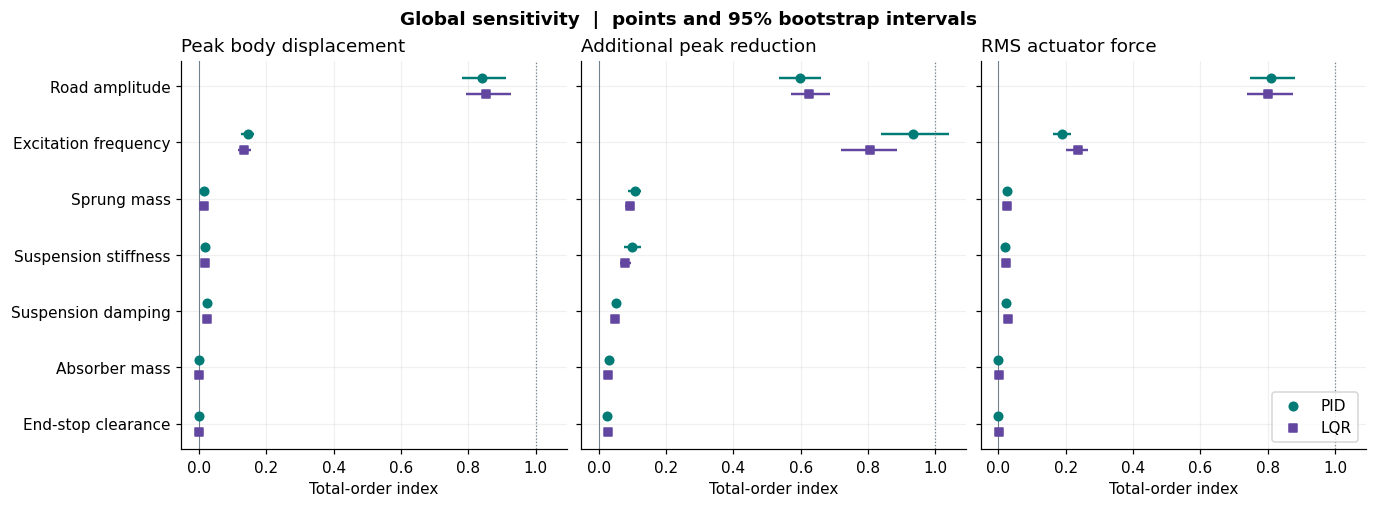

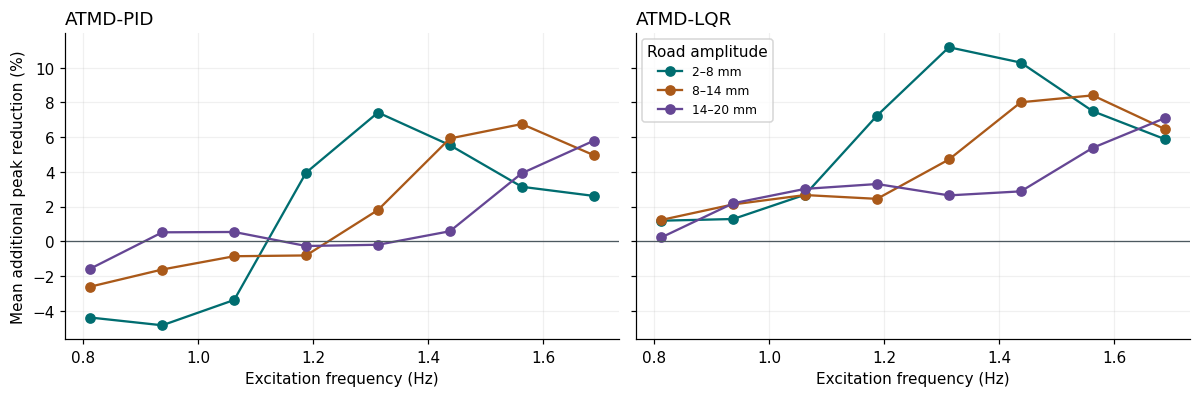

**Pengaruh langsung dan total pada additional peak reduction.** Selisih antara $S_1$ dan $S_T$ menunjukkan peran interaksi.

Factor,LQR S1,PID S1,LQR ST,PID ST
Road amplitude,0.149,0.045,0.625,0.599
Excitation frequency,0.309,0.311,0.807,0.934
Sprung mass,-0.014,-0.009,0.092,0.107
Suspension stiffness,-0.019,-0.002,0.079,0.098
Suspension damping,-0.019,-0.023,0.048,0.051
Absorber mass,-0.010,0.007,0.028,0.031
End-stop clearance,-0.019,-0.003,0.029,0.026


In [29]:
factor_order = factor_spec["Factor"].tolist()
figure, axes = plt.subplots(1,3,figsize=(12.4,4.5),sharey=True,sharex=True)
for axis,output in zip(axes,metric_titles.values()):
    for system,offset,mark in (("PID",-.14,"o"),("LQR",.14,"s")):
        subset = (sensitivity_report.query("System == @system and Output == @output")
                  .set_index("Factor").loc[factor_order])
        y_position = np.arange(len(factor_order))+offset
        axis.hlines(y_position,subset["CI low"],subset["CI high"],colors=colors[system],lw=1.6)
        axis.scatter(subset["ST"],y_position,color=colors[system],marker=mark,s=31,label=system,zorder=3)
    axis.axvline(1.,lw=.8,ls=":",color="#71808b")
    axis.axvline(0.,lw=.7,color="#71808b")
    axis.set(title=output,xlabel="Total-order index")
    axis.set_yticks(np.arange(len(factor_order)),labels=factor_order)
axes[0].invert_yaxis()
axes[-1].legend(loc="lower right")
figure.suptitle("Global sensitivity  |  points and 95% bootstrap intervals",weight="bold")
plt.show()

# Hitung conditional mean pada independent samples A+B. Bins dipakai untuk visualisasi saja.
independent_factors = pd.concat([mc_factors["A"],mc_factors["B"]],ignore_index=True)
frequency_edges = np.linspace(factor_spec.loc["frequency_hz","Low"],factor_spec.loc["frequency_hz","High"],9)
amplitude_edges = np.linspace(factor_spec.loc["amplitude_mm","Low"],factor_spec.loc["amplitude_mm","High"],4)
centres = .5*(frequency_edges[1:]+frequency_edges[:-1])
frequency_bin = pd.cut(independent_factors.frequency_hz,frequency_edges,labels=False,include_lowest=True)
amplitude_bin = pd.cut(independent_factors.amplitude_mm,amplitude_edges,labels=False,include_lowest=True)
bin_keys = pd.DataFrame({"Frequency bin":frequency_bin,"Amplitude bin":amplitude_bin})
bin_counts = bin_keys.value_counts()
fig, axes = plt.subplots(1,2,figsize=(10.8,3.5),sharey=True)
for axis,system in zip(axes,("PID","LQR")):
    grouped = bin_keys.assign(reduction=mc_population[(system,"extra_pct")]).groupby(
            ["Frequency bin","Amplitude bin"]).reduction.mean().unstack()
    for i,col in enumerate(("#006d70","#aa5919","#654694")):
        if i in grouped:
            axis.plot(centres,grouped[i].reindex(range(8)),marker="o",color=col,
                      label=f"{amplitude_edges[i]:g}–{amplitude_edges[i+1]:g} mm")
    axis.axhline(0,lw=.85,color="#4d5960")
    axis.set(xlabel="Excitation frequency (Hz)",title=f"ATMD-{system}")
axes[0].set_ylabel("Mean additional peak reduction (%)")
axes[1].legend(title="Road amplitude",fontsize=8)
plt.show()
print(f"Jumlah independent samples per bin yang terisi berkisar antara {bin_counts.min()} dan {bin_counts.max()}.")


benefit = sensitivity_report.query("Output == 'Additional peak reduction'")
index_detail = benefit.pivot(index="Factor",columns="System",values=["S1","ST"])
index_detail.columns = [f"{name} {measure}" for measure,name in index_detail.columns]
index_detail = index_detail.reindex(factor_order)
display(Markdown("**Pengaruh langsung dan total pada additional peak reduction.** Selisih antara $S_1$ dan $S_T$ menunjukkan peran interaksi."))
show_table(index_detail.reset_index(),3)

### Cara mengubah eksperimen

| Yang ingin diperiksa | Pengaturan di notebook | Cara memperoleh hasil yang konsisten |
|---|---|---|
| Kecepatan, massa, atau jenis jalan | §3, `training` dan `evaluation`. Untuk menambah kasus, buat `Scenario` baru. | Jalankan dari §3 agar *tuning*, tabel evaluasi, animasi, dan kesimpulan konsisten. |
| Segmen ARAN berbeda | §3, unggah `ATMD_measured_spatial_vectors.csv` dan ubah `default_segment_start`. | Tanpa unggahan, gunakan cuplikan bawaan 500–596 m. |
| Pilihan *actuator* atau *clearance* | §1, `Hardware`. Jaga *end-stop onset* di dalam *rated half-stroke*. | Jalankan **Run all**. Periksa ulang batas dan *unit* pada §9–10. |
| Resolusi grafik dan *check frequency* | §9, `frequency_grid_hz`. Untuk *fixed-frequency comparison* ubah daftar pada §9.1 dan §9.5 bersama-sama. | Jalankan ulang §9–11. |
| *Monte Carlo ranges*, jumlah sampel, atau *seed* | §10, `factor_spec`, `base_sample_size`, dan `monte_carlo_seed`. Nilai bawaan $N=1024$, dengan 400 *bootstrap replicates*. | Jalankan ulang §10–11. Pertahankan *seed* untuk membandingkan desain secara berpasangan. Ubah *seed* untuk memeriksa kestabilan peringkat. |

### Referensi

[1] Fédération Internationale de l’Automobile, International Court of Appeal, “Appeal against Decision N°8 handed down by the Stewards of the Meeting … concerning the T car of competitor Mild Seven Renault F1,” Paris, France, Aug. 22, 2006. [Putusan FIA](https://api.fia.com/sites/default/files/judgements/22-08-2006-ica-RenaultF1-a.pdf).

[2] Y. Taskin, I. Yuksek, and N. Yagiz, “Vibration control of vehicles with active tuned mass damper,” *Journal of Vibroengineering*, vol. 19, no. 5, pp. 3533–3541, Aug. 2017. [doi:10.21595/jve.2017.18138](https://doi.org/10.21595/jve.2017.18138).

[3] S. M. Karamihas, *Ride Quality of Jointed Concrete Pavements*, Univ. of Michigan Transportation Research Institute, Ann Arbor, MI, USA, Rep. UMTRI-2010-24, Nov. 2009, pp. 15–17, Fig. 7. [doi:10.7302/6991](https://doi.org/10.7302/6991).

[4] NTI AG, “Linear Modules DM01,” data sheet 0185-0112, ver. 1V4, sec. “Performance Data DM01-37x120,” and product data for part 0150-4013. Accessed Nov. 21, 2026. [Data sheet PDF](https://amplify-stevens.s3.us-east-1.amazonaws.com/images/Products/Linmot/Linmot-0185-0112-US_1V4_DS_Linear_Modules_DM01.pdf) · [LinMot product data](https://shop.linmot.com/E/dm01.37.1/linear-modules-___-guides/linear-modules-dm01/linear-modules-dm01-37/dm01-37-standard/dm01-37x120f-hp-r-95.htm).

[5] NTI AG, “PP03_95-37x120F_80-23x160H-MS11_TC01,” assembly drawing 0380-0123A, sheet 1, Dec. 23, 2025. [LinMot assembly drawing](https://shop.linmot.com/data/import/CAD/0380-0123_251223_PP03_95-37x120F_80-23x160H-MS11_TC01.PDF).

[6] K. Samaroo, A. W. Awan, S. Marimuthu, M. N. Iqbal, K. Daniel, and N. Shabbir, “Performance investigation of active, semi-active and passive suspension using quarter car model,” *Algorithms*, vol. 18, no. 2, Art. no. 100, Feb. 2025. [doi:10.3390/a18020100](https://doi.org/10.3390/a18020100).

[7] A. Skar *et al.*, “LiRA-CD: An open-source dataset for road condition modelling and research,” *Data in Brief*, vol. 49, Art. no. 109426, Aug. 2023. [doi:10.1016/j.dib.2023.109426](https://doi.org/10.1016/j.dib.2023.109426).

[8] K. J. Åström and R. M. Murray, *Feedback Systems: An Introduction for Scientists and Engineers*, 2nd ed. Princeton, NJ, USA: Princeton Univ. Press, 2021. [Penerbit](https://press.princeton.edu/books/hardcover/9780691193984/feedback-systems).

[9] M. J. W. Jansen, “Analysis of variance designs for model output,” *Computer Physics Communications*, vol. 117, nos. 1–2, pp. 35–43, Mar. 1999. [doi:10.1016/S0010-4655(98)00154-4](https://doi.org/10.1016/S0010-4655(98)00154-4).

[10] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto, and S. Tarantola, “Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index,” *Computer Physics Communications*, vol. 181, no. 2, pp. 259–270, Feb. 2010. [doi:10.1016/j.cpc.2009.09.018](https://doi.org/10.1016/j.cpc.2009.09.018).

## 11 · Kesimpulan

Nilai berikut berasal dari konfigurasi dan *Monte Carlo distributions* yang digunakan pada eksekusi ini.

In [30]:
# Angka, selisih, dan peringkat di bawah dibentuk dari hasil run saat ini.
nominal = results[results.case=="Nominal sine"].set_index("controller")
stress = results[results.case=="High-amplitude sine"].set_index("controller")
match = matched_results.set_index("Scenario").loc["Nominal sine"]
ideal = ablation[ablation.kondisi=="Unconstrained"].set_index("controller")
force_only = ablation[ablation.kondisi=="Force limit only"].set_index("controller")
bumper_range = contact_sensitivity.loc[contact_sensitivity.controller=="LQR","extra_pct"]
risk = risk_summary.set_index("System")
scores = leading_factors.set_index(["System","Output"])
ip = indonesia
nominal_amp_mm = 1000*nominal_sine.amplitude_m
stress_amp_mm = 1000*stress_case.amplitude_m
matched_winner = match["Lower RMS force at matched peak reduction"]
match_text = (f"Pada target ini, {matched_winner} membutuhkan RMS force lebih rendah."
              if bool(match["Difference (pp)"]<=1 and min(nominal.loc["PID","extra_pct"],nominal.loc["LQR","extra_pct"])>0
                      and nominal.loc["PID","screen"] and nominal.loc["LQR","screen"])
              else "Pasangan ini berada di luar syarat perbandingan gaya §5.")
def ranking(metric):
    statements = []
    for system in ("PID","LQR"):
        record = scores.loc[(system,metric_titles[metric])]
        statements.append(f"{system} **{record['Factor']}** ($S_T$ {ip(record['ST'],2)}, "
                          f"95% CI {ip(record['CI low'],2)}–{ip(record['CI high'],2)})")
    return " dan ".join(statements)
gain_summary = ", ".join(f"{system} **{ip(point_view.loc[(system,nominal_excitation_hz),'Gain (m/m)'],3)}**"
                         for system in ("Standard","Passive TMD","ATMD-PID","ATMD-LQR"))
display(Markdown(f"""
**1. Pada frekuensi desain.** Untuk sinus **{ip(nominal_excitation_hz,1)} Hz**, *road-to-body gain* masing-masing adalah {gain_summary} m/m.
Terhadap TMD pasif, PID mengurangi *steady-state amplitude* sebesar **{ip(nominal_pid['Reduction vs TMD (%)'])}%** dan LQR sebesar **{ip(nominal_lqr['Reduction vs TMD (%)'])}%**.
Pada 0,8 Hz, *additional peak reduction* untuk PID adalah **{ip(delta_pid)}%**. Pemilihan *gain* perlu memperhitungkan rentang *excitation frequency* yang akan dilalui kendaraan.

**2. Pada evaluation case yang sebanding.** Dengan *road amplitude* **{ip(nominal_amp_mm,1)} mm** dan seluruh *startup transient* disertakan, *peak body displacement* mencapai **{ip(nominal.loc['TMD','peak_mm'])} mm** untuk TMD, **{ip(nominal.loc['PID','peak_mm'])} mm** untuk PID, dan **{ip(nominal.loc['LQR','peak_mm'])} mm** untuk LQR.
Selisih *additional peak reduction* antara PID dan LQR adalah **{ip(match['Difference (pp)'])} poin persentase**. {match_text}
*RMS actuator force* masing-masing adalah **{ip(nominal.loc['PID','rms_force_N'])} N** dan **{ip(nominal.loc['LQR','rms_force_N'])} N**. Nilai ini memakai tiga periode terakhir.

**3. Batas mekanis.** Pada {ip(nominal_excitation_hz,1)} Hz, *linear model* memprediksi *first contact* pada *road amplitude* **{ip(limit_view.loc['ATMD-PID','First contact amplitude (mm)'])} mm** untuk PID dan **{ip(limit_view.loc['ATMD-LQR','First contact amplitude (mm)'])} mm** untuk LQR.
Pada uji **{ip(stress_amp_mm,0)} mm**, *peak reduction* ideal PID/LQR adalah **{ip(ideal.loc['PID','extra_pct'])}% / {ip(ideal.loc['LQR','extra_pct'])}%**. Dengan seluruh batas fisik, nilainya **{ip(stress.loc['PID','extra_pct'])}% / {ip(stress.loc['LQR','extra_pct'])}%**, dengan **{int(stress.loc['PID','contact_events'])} / {int(stress.loc['LQR','contact_events'])}** *contact events*.
Pada kasus *force limit only*, keduanya meminta *peak stroke* **{ip(force_only.loc['PID','stroke_mm'],0)} / {ip(force_only.loc['LQR','stroke_mm'],0)} mm** dari tengah. Ruang tersedia adalah **{ip(1000*hardware.half_travel,1)} mm**.
Variasi *bumper stiffness* dan *damping* menggeser tambahan penurunan LQR pada uji ini dari **{ip(bumper_range.min())}%** sampai **{ip(bumper_range.max())}%**.

**4. Faktor yang paling memengaruhi.** Untuk *peak body displacement*, faktor teratas adalah {ranking('peak_mm')}. Untuk *additional peak reduction* terhadap TMD, urutannya menjadi {ranking('extra_pct')}.
Untuk *RMS actuator force*, faktor teratas adalah {ranking('force_rms_N')}. Interval menyatakan *sampling uncertainty* dalam rentang §10. Pada daerah linear, *road amplitude* yang sama ikut tereliminasi saat *active peak* dibagi dengan *passive peak*.

**5. Implikasi untuk desain.** Di antara **{format(2*base_sample_size,",").replace(",",".")}** realisasi independen, PID menghasilkan *peak* lebih kecil daripada TMD pada **{ip(risk.loc['PID','Peak below TMD (%)'],1)}%** kasus dan LQR pada **{ip(risk.loc['LQR','Peak below TMD (%)'],1)}%** kasus. *End-stop contact* terjadi pada **{ip(risk.loc['PID','Any contact (%)'],1)}% / {ip(risk.loc['LQR','Any contact (%)'],1)}%** kasus PID/LQR. *Force saturation* terjadi pada **{ip(risk.loc['PID','Force saturation (%)'],1)}% / {ip(risk.loc['LQR','Force saturation (%)'],1)}%** kasus.
Untuk menentukan *operating envelope* prototipe, ukur *road amplitude* serta *excitation frequency*, lalu karakterisasi *end-stop force* terhadap *stroke* dan *relative velocity*. Persentase kasus dan peringkat di atas berlaku untuk asumsi *independent uniform sampling* studi ini. Verifikasi pada mobil fisik memerlukan data jalan, gerak bodi, *stroke*, dan gaya yang direkam serentak.
"""))


**1. Pada frekuensi desain.** Untuk sinus **1,2 Hz**, *road-to-body gain* masing-masing adalah Standard **1,911**, Passive TMD **1,719**, ATMD-PID **1,481**, ATMD-LQR **1,513** m/m.
Terhadap TMD pasif, PID mengurangi *steady-state amplitude* sebesar **13,89%** dan LQR sebesar **12,01%**.
Pada 0,8 Hz, *additional peak reduction* untuk PID adalah **-4,23%**. Pemilihan *gain* perlu memperhitungkan rentang *excitation frequency* yang akan dilalui kendaraan.

**2. Pada evaluation case yang sebanding.** Dengan *road amplitude* **4,0 mm** dan seluruh *startup transient* disertakan, *peak body displacement* mencapai **6,88 mm** untuk TMD, **6,10 mm** untuk PID, dan **6,16 mm** untuk LQR.
Selisih *additional peak reduction* antara PID dan LQR adalah **0,88 poin persentase**. Pada target ini, LQR membutuhkan RMS force lebih rendah.
*RMS actuator force* masing-masing adalah **3,51 N** dan **3,02 N**. Nilai ini memakai tiga periode terakhir.

**3. Batas mekanis.** Pada 1,2 Hz, *linear model* memprediksi *first contact* pada *road amplitude* **4,77 mm** untuk PID dan **5,87 mm** untuk LQR.
Pada uji **30 mm**, *peak reduction* ideal PID/LQR adalah **11,41% / 10,53%**. Dengan seluruh batas fisik, nilainya **-1,60% / 0,70%**, dengan **32 / 32** *contact events*.
Pada kasus *force limit only*, keduanya meminta *peak stroke* **275 / 209 mm** dari tengah. Ruang tersedia adalah **47,5 mm**.
Variasi *bumper stiffness* dan *damping* menggeser tambahan penurunan LQR pada uji ini dari **0,04%** sampai **1,66%**.

**4. Faktor yang paling memengaruhi.** Untuk *peak body displacement*, faktor teratas adalah PID **Road amplitude** ($S_T$ 0,84, 95% CI 0,78–0,91) dan LQR **Road amplitude** ($S_T$ 0,85, 95% CI 0,79–0,93). Untuk *additional peak reduction* terhadap TMD, urutannya menjadi PID **Excitation frequency** ($S_T$ 0,93, 95% CI 0,84–1,04) dan LQR **Excitation frequency** ($S_T$ 0,81, 95% CI 0,72–0,89).
Untuk *RMS actuator force*, faktor teratas adalah PID **Road amplitude** ($S_T$ 0,81, 95% CI 0,75–0,88) dan LQR **Road amplitude** ($S_T$ 0,80, 95% CI 0,74–0,88). Interval menyatakan *sampling uncertainty* dalam rentang §10. Pada daerah linear, *road amplitude* yang sama ikut tereliminasi saat *active peak* dibagi dengan *passive peak*.

**5. Implikasi untuk desain.** Di antara **2.048** realisasi independen, PID menghasilkan *peak* lebih kecil daripada TMD pada **62,7%** kasus dan LQR pada **90,9%** kasus. *End-stop contact* terjadi pada **81,5% / 75,2%** kasus PID/LQR. *Force saturation* terjadi pada **0,0% / 0,0%** kasus.
Untuk menentukan *operating envelope* prototipe, ukur *road amplitude* serta *excitation frequency*, lalu karakterisasi *end-stop force* terhadap *stroke* dan *relative velocity*. Persentase kasus dan peringkat di atas berlaku untuk asumsi *independent uniform sampling* studi ini. Verifikasi pada mobil fisik memerlukan data jalan, gerak bodi, *stroke*, dan gaya yang direkam serentak.


## 12 · Tuning PID dan LQR dengan optimasi terkendala

**Pertanyaan riset.** Dengan 64 kandidat per metode per keluarga controller, berapa RMS actuator force yang dibutuhkan untuk mencapai reduksi peak rata-rata minimal 5% dibanding TMD? Apakah penghematan gaya bertahan pada sembilan skenario evaluasi dan variasi parameter kendaraan?

Eksperimen ini memakai pasangan gain §4 sebagai titik awal bersama. Tiga jalan desain berbobot sama mencakup kedua jalan tuning §3 dan sinus 3 mm pada 1,25 Hz dengan sprung mass +10%. Setiap jalan mengizinkan kenaikan peak paling besar 3% terhadap TMD. Desain harus stabil pada setiap model sampled, bebas clipping dan kontak saat tuning, dan lolos screening gaya kontinu, kecepatan serta beban ban. Evaluasi memakai model nonlinear asli dengan saturasi dan end stops aktif. Data evaluasi menentukan pelaporan sesudah gain dibekukan.

Lima objektif membentuk himpunan Pareto empiris: rasio peak dan RMS displacement terhadap TMD, rerata RMS force, stroke maksimum, dan rerata estimasi energi motoring. Aturan keputusan memilih RMS force terendah di antara desain feasible. PID memakai Kp, rasio Ki/max(Kp,100), Kd dan stroke mix. LQR memakai skala gaya dan bobot stroke pada cost yang sudah dinormalisasi (§4). Riccati menghasilkan gain feedback.

In [31]:
# Constrained gain search. Units and model constants come from Sections 1–5.
from time import perf_counter
from scipy.special import ndtr
from scipy.stats import qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from threadpoolctl import threadpool_limits

design_roads = [*training, Scenario("Design mass +10%", "sine", .003, 10., 12.5, 1.10)]
gain_target_pct = 5.0
search_budget = 64
search_seeds = (11, 29, 47)
objective_names = ["peak_ratio", "rms_ratio", "force_N", "stroke_mm", "energy_J"]
reference = [batch_metrics(s, [passive])["TMD"] for s in design_roads]
baseline_controls = {"PID": auto_pid, "LQR": auto_lqr}

def decode_design(family, point):
    """Positive physical scales and continuous stroke weighting in a unit box."""
    if family == "PID":
        kp = np.expm1(point[0] * np.log1p(12000.))
        ki = max(kp, 100.) * (.12 + .53 * point[1])
        kd = 35. * (1150./35.)**point[2]
        return design_pid("PID", kp, ki, kd, .7*point[3])
    return design_lqr("LQR", 2.*125.**point[0], .02*150.**point[1])

def initial_design(family):
    if family == "PID":
        kp,ki,kd,beta = auto_pid.parameters
        return np.array([np.log1p(kp)/np.log1p(12000.), (ki/max(kp,100.)-.12)/.53,
                         np.log(kd/35.)/np.log(1150./35.), beta/.7])
    scale,weight = auto_lqr.parameters
    return np.array([np.log(scale/2.)/np.log(125.), np.log(weight/.02)/np.log(150.)])

def prepare_design_road(s):
    """Lift four exact plant steps into one controller period; retain each substep."""
    car = replace(vehicle, body_mass=vehicle.body_mass*s.mass_factor)
    phi, gamma = discrete_plant(car,tuned_absorber,integration_step)
    stride = round(control_period/integration_step)
    n = round(s.duration_s/integration_step)
    t = np.arange(n+1)*integration_step
    road = road_input(t,s)
    forcing = (.5*(road[:-1]+road[1:]))[:,None]*gamma[:,0] + (np.diff(road)/integration_step)[:,None]*gamma[:,1]
    forcing = forcing.reshape(-1,stride,6)
    transition, act, offsets = [np.eye(6)], [np.zeros(6)], [np.zeros((len(forcing),6))]
    for j in range(stride):
        transition.append(phi@transition[-1])
        act.append(phi@act[-1]+gamma[:,2])
        offsets.append(offsets[-1]@phi.T+forcing[:,j])
    return s,car,t,road,transition,act,offsets

design_models = [prepare_design_road(s) for s in design_roads]

def design_trace(c, model):
    """Exact no-contact/no-clipping trajectory, valid until first constraint crossing."""
    s,car,t,road,phi,act,offset = model
    gain = np.asarray(c.feedback)
    use_i = c.integral_gain > 0
    dim = 6 + int(use_i)
    closed = np.zeros((dim,dim))
    closed[:6,:6] = phi[-1] - np.outer(act[-1],gain)
    drive = np.zeros((len(offset[-1]),dim))
    drive[:,:6] = offset[-1]
    if use_i:
        closed[:6,6] = act[-1]
        closed[6,:6] = -control_period*c.integral_gain*np.array([1+c.stroke_mix,0,-c.stroke_mix,0,0,0])
        closed[6,6] = 1-control_period*integral_leak_rate
    poles, modes = linalg.eig(closed)
    if np.max(abs(poles)) >= 1:
        return None
    if np.linalg.cond(modes) > 1e9:
        # Rare defective modal bases: propagate the small recurrence directly.
        coarse = np.zeros((len(drive)+1,dim))
        for j,d in enumerate(drive):
            coarse[j+1] = closed@coarse[j]+d
    else:
        modal_drive = linalg.solve(modes,drive.T).T
        modal = np.column_stack([signal.lfilter([1.],[1.,-pole],modal_drive[:,j])
                                 for j,pole in enumerate(poles)])
        coarse = np.vstack((np.zeros(dim), (modal@modes.T).real))
    requests = -coarse[:,:6]@gain + (coarse[:,6] if use_i else 0.)
    stride = len(act)-1
    positions = np.zeros((len(t),6))
    for j in range(stride):
        positions[j:-1:stride] = coarse[:-1,:6]@phi[j].T + requests[:-1,None]*act[j] + offset[j]
    positions[-1] = coarse[-1,:6]
    force = np.r_[np.repeat(requests[:-1],stride),requests[-1]]
    trace = Trace(t,road,positions[:,0],positions[:,1],positions[:,2],positions[:,5]-positions[:,3],
                  force,force,np.zeros_like(force),True)
    return metrics(trace,s)

def score_point(family, point):
    c = decode_design(family,point)
    rows = [design_trace(c,m) for m in design_models]
    if any(m is None for m in rows):
        return np.full(5,1e3),100.,-1e3
    peaks = np.array([m["peak_mm"]/p["peak_mm"] for m,p in zip(rows,reference)])
    rms = [m["rms_mm"]/p["rms_mm"] for m,p in zip(rows,reference)]
    obj = np.array([peaks.mean(),np.mean(rms),np.mean([m["rms_force_N"] for m in rows]),
                    max(m["stroke_mm"] for m in rows),np.mean([m["motor_energy_J"] for m in rows])])
    gain = 100*(1-obj[0])
    limits = [(gain_target_pct-gain)/100., peaks.max()-1.03]
    for m in rows:
        limits.extend([m["stroke_mm"]/(1000*hardware.stop_onset)-1,
                       m["peak_force_N"]/hardware.peak_force-1,
                       max(m["rms_force_N"],m["duty_rms_N"])/hardware.continuous_force-1,
                       m["speed_m_s"]/hardware.speed_reference-1,
                       -m["tire_normal_min_N"]/3000.])
    return obj,max(limits),gain

# Check the lifted solver against the nonlinear notebook solver at the common starting designs.
for family,c in baseline_controls.items():
    for case,model in zip(design_roads,design_models):
        lifted = design_trace(c,model)
        exact = batch_metrics(case,[c])[c.label]
        assert exact["contact_events"] == 0 and exact["sat_pct"] == 0
        for metric in ["peak_mm","rms_mm","rms_force_N","stroke_mm","motor_energy_J"]:
            np.testing.assert_allclose(lifted[metric],exact[metric],rtol=2e-7,atol=1e-8)


### 12.1 · Pencarian dengan anggaran setara

Grid deterministik menggunakan 64 titik termasuk titik awal bersama. DE dan BO memakai 16 titik awal yang sama per seed, lalu 48 evaluasi adaptif. DE menggunakan mutasi rand/1/bin dan seleksi berbasis feasibility. BO memakai GP Matérn untuk margin kendala serta objective scalarized dan memilih kandidat dengan expected improvement dikalikan probabilitas feasibility. Kedua pencarian bergantian menekankan gaya dan kombinasi berbobot dari lima objektif. Referensi metode: [Storn & Price](https://doi.org/10.1023/A:1008202821328), [Knowles](https://doi.org/10.1109/TEVC.2005.851274), dan [Gardner dkk.](https://proceedings.mlr.press/v32/gardner14.html).

Margin pada lintasan linear mendeteksi pelanggaran pertama. Setelah pelanggaran, nilai linear hanya dipakai untuk mengarahkan pencarian. Seluruh kandidat final diuji kembali menggunakan model kontak. Tiga seed dipakai untuk metode stokastik.

In [32]:
def grid_points(family):
    dims = (4,2,4,2) if family=="PID" else (8,8)
    grid = np.array(list(product(*[np.linspace(0,1,n) for n in dims])))
    start = initial_design(family)
    return np.vstack([start,np.delete(grid,np.argmin(np.linalg.norm(grid-start,axis=1)),axis=0)])

def scalar_loss(values, feasible, weights):
    """Augmented Tchebycheff scalarization of the five engineering objectives."""
    anchor = values[feasible] if np.any(feasible) else values
    lo = anchor.min(axis=0)
    span = np.maximum(np.ptp(anchor,axis=0),[.02,.02,.5,5.,.2])
    weighted = weights*(values-lo)/span
    return weighted.max(axis=1)+.05*weighted.sum(axis=1)

def weights_for_step(rng, step):
    return np.eye(5)[2] if step%2==0 else rng.dirichlet(np.ones(5))

def expected_improvement(mean,sd,best):
    sd = np.maximum(sd,1e-12)
    z = (best-mean)/sd
    return (best-mean)*ndtr(z)+sd*np.exp(-.5*z**2)/np.sqrt(2*np.pi)

def gp_predict(x,y,pool):
    # Fixed smoothness and unit-box length scale make small-budget runs repeatable.
    model = GaussianProcessRegressor(kernel=Matern(length_scale=.32,nu=2.5),
        alpha=1e-6,normalize_y=True,optimizer=None)
    return model.fit(x,y).predict(pool,return_std=True)

def benchmark(family,method,seed):
    rng = np.random.default_rng(seed)
    start = initial_design(family)
    dim = len(start)
    points, objectives, margins, gains, elapsed = [],[],[],[],[]
    clock = perf_counter()
    def evaluate(x):
        obj,margin,gain = score_point(family,x)
        points.append(np.array(x)); objectives.append(obj); margins.append(margin); gains.append(gain)
        elapsed.append(perf_counter()-clock)
    if method=="Grid":
        for x in grid_points(family): evaluate(x)
    else:
        initial = qmc.LatinHypercube(d=dim,seed=seed).random(15)
        for x in np.vstack([start,initial]): evaluate(x)
        population = np.arange(16)
        while len(points)<search_budget:
            x = np.array(points)
            y = np.array(objectives)
            margin = np.array(margins)
            feasible = margin <= 1e-10
            w = weights_for_step(rng,len(points) if method=="BO" else len(points)//16)
            if method=="DE":
                # DE/rand/1/bin, F=0.7 and CR=0.85; preserve feasible solutions.
                trials = []
                for target in range(len(population)):
                    a,b,c = rng.choice(np.delete(population,target),3,replace=False)
                    mutant = np.clip(x[a]+.7*(x[b]-x[c]),0,1)
                    mask = rng.random(dim)<.85
                    mask[rng.integers(dim)]=True
                    trials.append(np.where(mask,mutant,x[population[target]]))
                offset = len(points)
                for trial in trials: evaluate(trial)
                m = np.array(margins)
                losses = scalar_loss(np.array(objectives),m<=1e-10,w)
                for j,old in enumerate(population.copy()):
                    new=offset+j
                    def rank(i):
                        return (m[i]>1e-10,max(0.,m[i]),losses[i])
                    if rank(new)<rank(old): population[j]=new
            else:
                # Constrained ParEGO: model scalarized objectives on feasible trajectories.
                # A second GP models the signed maximum design constraint.
                candidates = rng.random((1536,dim))
                best_x = x[np.flatnonzero(feasible)[np.argmin(y[feasible,2])]]
                local = np.clip(best_x+rng.normal(0,.1,(512,dim)),0,1)
                candidates = np.vstack([candidates,local])
                # Signed log transform preserves the feasibility boundary at zero.
                transformed = np.sign(margin)*np.log1p(abs(margin))
                mu_c,sd_c = gp_predict(x,transformed,candidates)
                probability = ndtr(-mu_c/np.maximum(sd_c,1e-9))
                if feasible.sum()>=2:
                    loss = scalar_loss(y,feasible,w)[feasible]
                    mu,sd = gp_predict(x[feasible],loss,candidates)
                    acquisition = expected_improvement(mu,sd,loss.min())*probability
                else:
                    acquisition = probability*(sd_c+.01)
                nearest = np.min(np.linalg.norm(candidates[:,None,:]-x[None,:,:],axis=2),axis=1)
                acquisition[nearest<1e-6]=-np.inf
                evaluate(candidates[np.argmax(acquisition)])
    records=[]
    for i,(point,obj,margin,gain,seconds) in enumerate(zip(points,objectives,margins,gains,elapsed),1):
        records.append(dict(family=family,method=method,seed=seed,call=i,unit_point=point.tolist(),
            feasible=margin<=1e-10,margin=margin,mean_gain_pct=gain,seconds=seconds,**dict(zip(objective_names,obj))))
    return records

history_rows=[]
with threadpool_limits(limits=1):
    for family in baseline_controls:
        for method in ("Grid","DE","BO"):
            for seed in ((search_seeds[0],) if method=="Grid" else search_seeds):
                history_rows.extend(benchmark(family,method,seed))
search_history=pd.DataFrame(history_rows)
run_keys=["family","method","seed"]
feasible_history=search_history[search_history.feasible]
selected_indices=feasible_history.groupby(run_keys).force_N.idxmin()
frozen=search_history.loc[selected_indices].copy().sort_values(run_keys)
frozen["parameters"]=[tuple(map(float,decode_design(r.family,r.unit_point).parameters)) for r in frozen.itertuples()]
frozen["budget_s"]=[search_history[(search_history.family==r.family)&(search_history.method==r.method)&
    (search_history.seed==r.seed)].seconds.iloc[-1] for r in frozen.itertuples()]
assert (search_history.groupby(run_keys).size()==search_budget).all()
assert len(frozen)==14
print(frozen[run_keys+["mean_gain_pct","force_N","call","budget_s"]].round(3).to_string(index=False))


family method  seed  mean_gain_pct  force_N  call  budget_s
   LQR     BO    11          5.001    1.228    45     0.752
   LQR     BO    29          5.003    1.229    59     0.736
   LQR     BO    47          5.002    1.228    43     0.757
   LQR     DE    11          5.735    1.692    12     0.565
   LQR     DE    29          5.466    1.429    45     0.442
   LQR     DE    47          6.719    1.905     7     0.453
   LQR   Grid    11          5.905    1.636    42     0.519
   PID     BO    11          5.129    1.421    32     0.837
   PID     BO    29          5.218    1.355    25     0.840
   PID     BO    47          5.006    1.270    57     0.806
   PID     DE    11          6.890    2.043    47     0.470
   PID     DE    29          7.775    2.253     1     0.472
   PID     DE    47          6.367    1.758    41     0.467
   PID   Grid    11          5.801    1.610    41     0.474


### 12.2 · Validasi gain beku dan konvergensi

Satu trial memilih satu controller dari data tuning. Statistik evaluasi memberi bobot yang sama pada sembilan skenario. Tabel menampilkan median antar-seed untuk setiap metrik. Grafik atas menampilkan median dan rentang incumbent antar-seed. Grafik bawah memproyeksikan kandidat nondominated di lima objektif ke dua sumbu.

               train_force_N  train_gain_pct  test_gain_pct  test_force_N  test_energy_J  screen_min  elapsed_s  best_call
family method                                                                                                             
LQR    BO              1.228           5.002          3.273         4.408          3.631           9      0.752       45.0
       DE              1.692           5.735          4.065         7.021          4.765           9      0.453       12.0
       Grid            1.636           5.905          4.014         6.601          4.749           9      0.519       42.0
PID    BO              1.355           5.129          2.806         3.744          3.442           9      0.837       32.0
       DE              2.043           6.890          3.090         6.224          6.103           9      0.470       41.0
       Grid            1.610           5.801          2.991         4.711          4.880           9      0.474       41.0


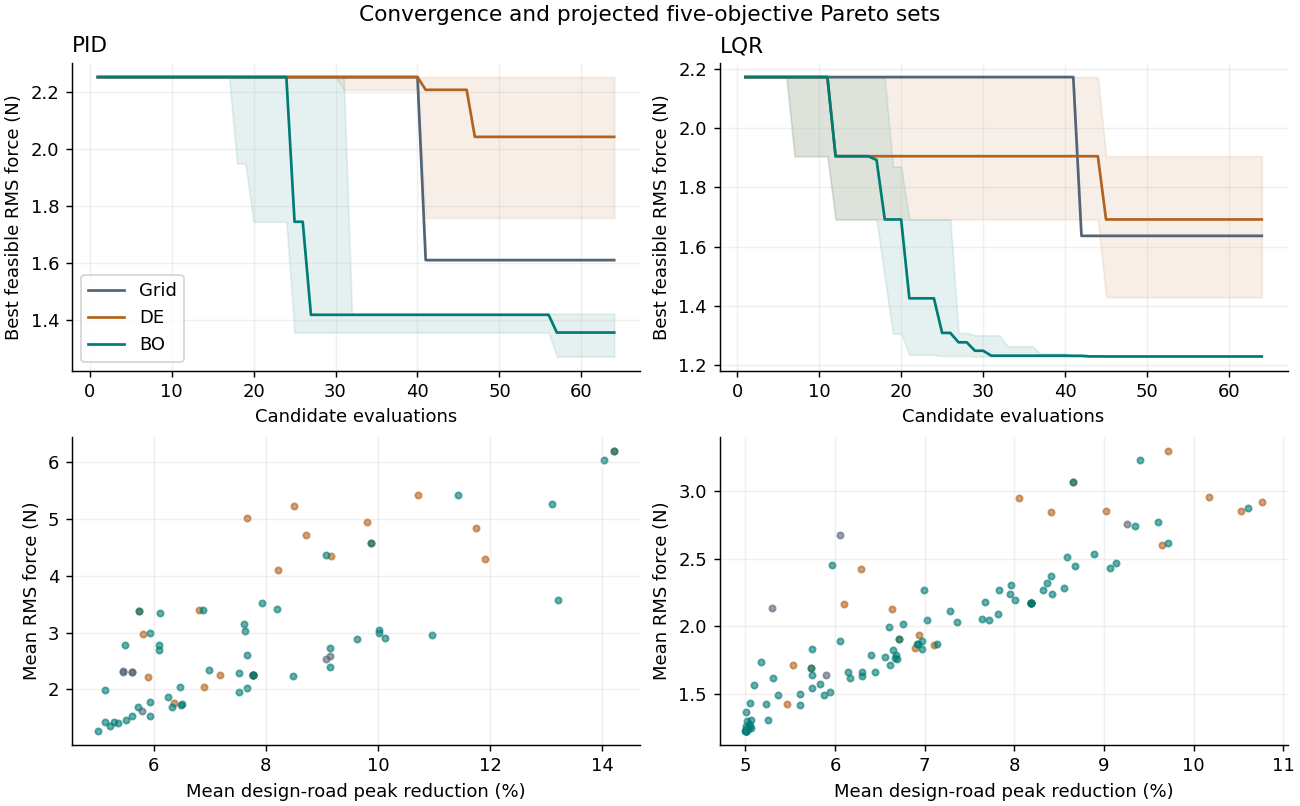

In [33]:
# Freeze each seed's selection before reading evaluation scores.
held_rows=[]
for case in evaluation:
    ctrls=[replace(decode_design(r.family,r.unit_point),label=f"{r.family}-{r.method}-{r.seed}")
           for r in frozen.itertuples()]
    reference_peak=batch_metrics(case,[passive])["TMD"]["peak_mm"]
    tested=batch_metrics(case,ctrls)
    for c,r in zip(ctrls,frozen.itertuples()):
        m=tested[c.label]
        held_rows.append(dict(family=r.family,method=r.method,seed=r.seed,case=case.name,
            gain_pct=100*(1-m["peak_mm"]/reference_peak),screen=screened(m),**m))
heldout=pd.DataFrame(held_rows)
summary_runs=frozen[run_keys+["force_N","mean_gain_pct","budget_s","call"]].merge(
    heldout.groupby(run_keys,as_index=False).agg(test_gain_pct=("gain_pct","mean"),
        test_force_N=("rms_force_N","mean"),test_energy_J=("motor_energy_J","mean"),
        worst_gain_pct=("gain_pct","min"),screen_passes=("screen","sum")))
comparison=summary_runs.groupby(["family","method"]).agg(
    train_force_N=("force_N","median"),train_gain_pct=("mean_gain_pct","median"),
    test_gain_pct=("test_gain_pct","median"),test_force_N=("test_force_N","median"),
    test_energy_J=("test_energy_J","median"),screen_min=("screen_passes","min"),
    elapsed_s=("budget_s","median"),best_call=("call","median"))
print(comparison.round(3).to_string())

def pareto_mask(values):
    return np.array([not np.any(np.all(values<=row,axis=1)&np.any(values<row,axis=1)) for row in values])
search_history["pareto"]=False
for _,group in feasible_history.groupby(run_keys):
    search_history.loc[group.index[pareto_mask(group[objective_names].to_numpy())],"pareto"]=True

fig,axs=plt.subplots(2,2,figsize=(10,6.2),layout="constrained")
for col,family in enumerate(("PID","LQR")):
    for method,color in zip(("Grid","DE","BO"),("#536476","#b3621c","#007b76")):
        dataset=search_history[(search_history.family==family)&(search_history.method==method)]
        traces=[g.force_N.where(g.feasible,np.inf).cummin().values for _,g in dataset.groupby("seed")]
        axs[0,col].plot(np.arange(1,search_budget+1),np.median(traces,axis=0),label=method,color=color)
        axs[0,col].fill_between(np.arange(1,search_budget+1),np.min(traces,axis=0),np.max(traces,axis=0),
                                color=color,alpha=.10)
        points=dataset[dataset.pareto]
        axs[1,col].scatter(points.mean_gain_pct,points.force_N,s=12,alpha=.6,color=color,label=method)
    axs[0,col].set(title=family,xlabel="Candidate evaluations",ylabel="Best feasible RMS force (N)")
    axs[1,col].set(xlabel="Mean design-road peak reduction (%)",ylabel="Mean RMS force (N)")
axs[0,0].legend()
fig.suptitle("Convergence and projected five-objective Pareto sets")
plt.show()


### 12.3 · Ketahanan terhadap variasi parameter

Untuk setiap metode dan keluarga, gunakan run aktual yang berada pada median gaya tuning. Enam controller dan TMD menerima 2.048 sampel independen A+B yang identik. Tujuh blok hybrid tambahan dipakai untuk indeks Sobol pasangan BO. Pembandingan ini menggunakan rentang parameter dan seed §10.

In [34]:
# Select an actual run at median training effort. All nine test scores remain unseen by this rule.
representatives = {}
for (family,method),group in frozen.groupby(["family","method"]):
    mid = group.sort_values(["force_N","seed"]).iloc[len(group)//2]
    representatives[(family,method)] = replace(decode_design(family,mid.unit_point),label=f"{method}-{family}")

def comparative_uncertainty():
    all_controls = [passive,*representatives.values()]
    bo_controls = [passive,representatives["PID","BO"],representatives["LQR","BO"]]
    blocks = {}
    for key,factors in mc_factors.items():
        controls = all_controls if key in ("A","B") else bo_controls
        blocks[key]=pd.concat([simulate_uncertain_batch(factors.iloc[i:i+sample_batch_size],controls)
                              for i in range(0,len(factors),sample_batch_size)])
    population=pd.concat([blocks["A"],blocks["B"]],ignore_index=True)
    summaries=[]
    for (family,method),c in representatives.items():
        a=population[c.label]
        summaries.append(dict(family=family,method=method,draws=len(a),median_peak_mm=a.peak_mm.median(),
            median_force_N=a.force_rms_N.median(),median_gain_pct=a.extra_pct.median(),
            beat_TMD_pct=100*(a.extra_pct>0).mean(),contact_pct=100*a.contact.mean(),
            failed_screens=int((~a.screen).sum())))
    selected_metrics=[(c.label,k) for c in bo_controls[1:] for k in ("peak_mm","extra_pct","force_rms_N")]
    a,b=[blocks[k].loc[:,selected_metrics].to_numpy() for k in ("A","B")]
    ab=np.stack([blocks[k].loc[:,selected_metrics].to_numpy() for k in factor_spec.index],axis=1)
    first,total=jansen_indices(a,b,ab)
    indices=[dict(controller=ctrl,metric=metric,factor=f,first=first[i,j],total=total[i,j])
             for j,(ctrl,metric) in enumerate(selected_metrics) for i,f in enumerate(factor_spec.index)]
    return pd.DataFrame(summaries),pd.DataFrame(indices)

with threadpool_limits(limits=1):
    uncertainty_comparison,bo_sobol=comparative_uncertainty()
print(uncertainty_comparison.round(3).to_string(index=False))
print(bo_sobol.loc[bo_sobol.groupby(["controller","metric"]).total.idxmax()].round(3).to_string(index=False))


family method  draws  median_peak_mm  median_force_N  median_gain_pct  beat_TMD_pct  contact_pct  failed_screens
   LQR     BO   2048          16.729           5.513            2.194        88.525       67.432               0
   LQR     DE   2048          16.471           7.930            3.604        95.801       65.869               0
   LQR   Grid   2048          16.532           7.703            3.419        94.043       67.236               0
   PID     BO   2048          17.019           5.609           -0.158        47.607       73.340               0
   PID     DE   2048          17.467           9.061           -3.141        40.283       74.951               0
   PID   Grid   2048          16.969           6.596            0.533        60.400       75.244               0
controller      metric       factor  first  total
    BO-LQR   extra_pct frequency_hz  0.279  0.850
    BO-LQR force_rms_N amplitude_mm  0.736  0.825
    BO-LQR     peak_mm amplitude_mm  0.834  0.859
    BO-PI

### Pemeriksaan gain representatif
Model nonlinear dijalankan ulang pada tiga jalan desain untuk memeriksa seleksi gain, kemudian dihitung batas frekuensi dengan gain di bawah TMD.

In [35]:
# Engineering check on each representative design: full nonlinear training replay and small-signal band.
band_grid=np.geomspace(.55,2.5,651)
passive_gain=np.abs(frequency_channels(passive,band_grid)["body"])
response_rows=[]
for (family,method),c in representatives.items():
    for s,model in zip(design_roads,design_models):
        m=batch_metrics(s,[c])[c.label]
        assert m["contact_events"]==0 and m["sat_pct"]==0 and screened(m)
        linear=design_trace(c,model)
        for k in ("peak_mm","rms_mm","rms_force_N","stroke_mm","motor_energy_J"):
            np.testing.assert_allclose(m[k],linear[k],rtol=2e-7,atol=1e-8)
    ratio=np.abs(frequency_channels(c,band_grid)["body"])/passive_gain-1
    def difference(f):
        return abs(frequency_channels(c,[f])["body"][0])/abs(frequency_channels(passive,[f])["body"][0])-1
    roots=[brentq(difference,a,b) for a,b,l,r in zip(band_grid[:-1],band_grid[1:],ratio[:-1],ratio[1:]) if l*r<0]
    edges=[band_grid[0],*roots,band_grid[-1]]
    ranges=[(float(a),float(b)) for a,b in zip(edges[:-1],edges[1:]) if difference(np.sqrt(a*b))<0]
    response_rows.append(dict(family=family,method=method,
        gain_at_1p2=abs(frequency_channels(c,[1.2])["body"][0]),benefit_bands_Hz=ranges,
        parameters=list(map(float,c.parameters)),feedback=list(map(float,c.feedback))))
representative_response=pd.DataFrame(response_rows)
print(representative_response[["family","method","gain_at_1p2","benefit_bands_Hz"]].to_string(index=False))


family method  gain_at_1p2                                                                     benefit_bands_Hz
   LQR     BO     1.593734                                           [(0.7880509976618518, 1.8386255956917026)]
   LQR     DE     1.592643 [(0.7294928282714465, 1.0010112274821203), (1.0671648203109931, 2.0632044992515994)]
   LQR   Grid     1.581918                                           [(0.7435838339752618, 1.9955627842748198)]
   PID     BO     1.564917                                            [(0.9213799861212645, 2.195838515829174)]
   PID     DE     1.508097                                                          [(0.9985789027576774, 2.5)]
   PID   Grid     1.546016                                           [(0.8935337114070465, 1.8657002401444631)]


### 12.4 · Jawaban penelitian

Angka berikut dihitung dari data eksperimen di atas. Semua persentase reduksi peak displacement memakai TMD pasif pada jalan yang sama sebagai baseline.

In [36]:
for fam in ("PID","LQR"):
    grid,bo=[comparison.loc[(fam,method)] for method in ("Grid","BO")]
    rep=representatives[fam,"BO"]
    print(f"{fam} — Dengan target tuning {gain_target_pct:.0f}%, median RMS force BO "
          f"{bo.train_force_N:.3f} N vs grid {grid.train_force_N:.3f} N "
          f"({100*(1-bo.train_force_N/grid.train_force_N):.1f}% lebih rendah).")
    print(f"Sembilan skenario: gaya rata-rata menjadi {bo.test_force_N:.3f} vs {grid.test_force_N:.3f} N, "
          f"dengan reduksi peak {bo.test_gain_pct:.2f}% vs {grid.test_gain_pct:.2f}%.")
    print("Parameter BO representatif:",np.round(rep.parameters,6))
    if fam=="LQR": print("K LQR [zs,zu,za,vs,vu,va]:",np.round(rep.feedback,6))
    for row in uncertainty_comparison.query("family == @fam").itertuples():
        print(f"{row.method}: peak lebih kecil daripada TMD pada {row.beat_TMD_pct:.1f}% dari "
              f"{row.draws} realisasi; median gaya {row.median_force_N:.3f} N.")
print("Target 5% berlaku pada rata-rata tiga jalan tuning. Efek di jalan lain bergantung pada "
      "frekuensi, bentuk gangguan, dan kontak. Anggaran 64 titik dan tiga seed membatasi peringkat metode.")


PID — Dengan target tuning 5%, median RMS force BO 1.355 N vs grid 1.610 N (15.8% lebih rendah).
Sembilan skenario: gaya rata-rata menjadi 3.744 vs 4.711 N, dengan reduksi peak 2.81% vs 2.99%.
Parameter BO representatif: [408.210249  48.98523   35.205595   0.      ]
BO: peak lebih kecil daripada TMD pada 47.6% dari 2048 realisasi; median gaya 5.609 N.
DE: peak lebih kecil daripada TMD pada 40.3% dari 2048 realisasi; median gaya 9.061 N.
Grid: peak lebih kecil daripada TMD pada 60.4% dari 2048 realisasi; median gaya 6.596 N.
LQR — Dengan target tuning 5%, median RMS force BO 1.228 N vs grid 1.636 N (24.9% lebih rendah).
Sembilan skenario: gaya rata-rata menjadi 4.408 vs 6.601 N, dengan reduksi peak 3.27% vs 4.01%.
Parameter BO representatif: [4.3379507e+01 2.0000000e-02]
K LQR [zs,zu,za,vs,vu,va]: [ 723.705718 -115.647933  -23.531844   27.649271    1.174765  -18.65044 ]
BO: peak lebih kecil daripada TMD pada 88.5% dari 2048 realisasi; median gaya 5.513 N.
DE: peak lebih kecil daripada T